# F1 Podium Prediction · Step 1: Data Cleaning & Auditing

This notebook audits and cleans the 14 Ergast tables (1950–2024) before any feature engineering. Every cleaning action follows the same four steps: **SEE** the problem in a table or plot, **DECIDE** with the numbers in view, **ACT** on the `clean` copy only, and **VERIFY** with asserts and before/after counts. The raw CSVs stay untouched in `raw`.

## 0. Setup

In [1]:
# ── 0. Setup: imports, configuration, paths, plot style ─────────────────────
import html
import os
import platform
import random
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# Reproducibility: nothing in this notebook is stochastic, but we fix seeds so any sampling stays deterministic.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Data location: Kaggle input dataset if present. Locally, the notebook may be started from the project
# root or from notebooks/, so use whichever of the current folder or its parent holds the CSVs.
KAGGLE_DIR = Path("/kaggle/input/formula-1-world-championship-1950-2020/")
ON_KAGGLE = KAGGLE_DIR.exists()
if ON_KAGGLE:
    DATA_DIR = KAGGLE_DIR
else:
    DATA_DIR = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / "races.csv").exists()), Path.cwd())

# Outputs: Kaggle's input folder is read-only, so write under /kaggle/working; locally write next to the data.
OUT_DIR = (Path("/kaggle/working") if ON_KAGGLE else DATA_DIR) / "outputs" / "clean"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# The 14 Ergast tables this notebook audits.
TABLES = [
    "circuits", "constructors", "constructor_results", "constructor_standings",
    "drivers", "driver_standings", "races", "results", "qualifying",
    "lap_times", "pit_stops", "sprint_results", "seasons", "status",
]

# The two text forms Ergast uses for "missing" (measured in Section 1, replaced in Section 2).
PLACEHOLDERS = [r"\N", ""]

# Plot + display style.
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.figsize": (12, 4.5), "figure.dpi": 100, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)
warnings.filterwarnings("ignore", category=FutureWarning)

# Environment report + confirm every expected file is present before going further.
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__} | missingno {msno.__version__}")
print(f"DATA_DIR = {DATA_DIR}  ({'Kaggle' if ON_KAGGLE else 'local'}; notebook started from {Path.cwd()})")
print(f"OUT_DIR  = {OUT_DIR}")

file_check = pd.DataFrame({
    "table": TABLES,
    "exists": [(DATA_DIR / f"{t}.csv").exists() for t in TABLES],
    "size_MB": [round((DATA_DIR / f"{t}.csv").stat().st_size / 1e6, 3) if (DATA_DIR / f"{t}.csv").exists() else np.nan
                for t in TABLES],
}).sort_values("size_MB", ascending=False, ignore_index=True)
display(file_check)

missing_files = file_check.loc[~file_check["exists"], "table"].tolist()
assert not missing_files, f"Missing CSVs in {DATA_DIR}: {missing_files}"
print(f"All {len(TABLES)} CSVs found, {file_check['size_MB'].sum():.1f} MB total.")

Python 3.12.5 | pandas 3.0.6 | numpy 2.5.3 | matplotlib 3.11.2 | seaborn 0.13.2 | missingno 0.5.2
DATA_DIR = C:\Users\omaro\F1  (local; notebook started from C:\Users\omaro\F1\notebooks)
OUT_DIR  = C:\Users\omaro\F1\outputs\clean


,table,exists,size_MB
0,lap_times,True,17.622
1,results,True,1.722
2,driver_standings,True,0.884
3,qualifying,True,0.465
4,pit_stops,True,0.444
5,constructor_standings,True,0.317
6,constructor_results,True,0.219
7,races,True,0.164
8,drivers,True,0.094
9,sprint_results,True,0.025


All 14 CSVs found, 22.0 MB total.


### Loading decision: read every CSV as plain text

We load all 14 tables with `dtype=str, keep_default_na=False`, so pandas converts nothing on load.

- The placeholders (`\N`, `""`) stay visible, so we can count them before cleaning (brief: sentinel handling, EDA before and after).
- `raw` keeps the files exactly as delivered. All cleaning happens on copies in `clean`.
- Real types (dates, seconds, IDs) are assigned later, in Section 3.

In [2]:
# ── 0. Load all 14 CSVs as plain text into the immutable `raw` dict ─────────
def load_raw(table: str) -> pd.DataFrame:
    """Read one Ergast CSV exactly as written: every value is text, nothing is turned into NaN."""
    return pd.read_csv(DATA_DIR / f"{table}.csv", dtype=str, keep_default_na=False, na_filter=False)


def fingerprint(df: pd.DataFrame) -> int:
    """Content hash of a table. Used at the end of the notebook to prove `raw` was never modified."""
    return int(pd.util.hash_pandas_object(df, index=True).sum())


raw = {t: load_raw(t) for t in TABLES}
RAW_FINGERPRINT = {t: fingerprint(df) for t, df in raw.items()}

load_summary = pd.DataFrame({
    "rows": {t: len(df) for t, df in raw.items()},
    "columns": {t: df.shape[1] for t, df in raw.items()},
    "memory_MB": {t: round(df.memory_usage(deep=True).sum() / 1e6, 2) for t, df in raw.items()},
    "real_NaN_cells": {t: int(df.isna().sum().sum()) for t, df in raw.items()},
    "backslash_N_cells": {t: int((df == r"\N").sum().sum()) for t, df in raw.items()},
    "empty_string_cells": {t: int((df == "").sum().sum()) for t, df in raw.items()},
}).rename_axis("table").sort_values("rows", ascending=False)
display(load_summary)

# Proof that the load kept the raw values: no real NaN anywhere, so every placeholder is still visible as text.
assert load_summary["real_NaN_cells"].sum() == 0, "pandas converted some values to NaN on load"
print(f"Loaded {len(raw)} tables, {load_summary['rows'].sum():,} rows in total, "
      f"{load_summary['memory_MB'].sum():.1f} MB in memory.")
n_backslash_n = load_summary["backslash_N_cells"].sum()
print(f"Placeholders kept as text: {n_backslash_n:,} '\\N' cells and "
      f"{load_summary['empty_string_cells'].sum():,} empty-string cells (counted per column in Section 1).")

,rows,columns,memory_MB,real_NaN_cells,backslash_N_cells,empty_string_cells
table,,,,,,
lap_times,589081,6,41.19,0,0,0
driver_standings,34863,7,2.52,0,0,0
results,26759,18,4.99,0,122887,0
constructor_standings,13391,7,0.95,0,0,0
constructor_results,12625,5,0.66,0,12608,0
pit_stops,11371,7,0.96,0,0,0
qualifying,10494,9,1.09,0,11600,68
races,1125,18,0.30,0,11349,0
drivers,861,9,0.14,0,1559,0


Loaded 14 tables, 701,433 rows in total, 52.9 MB in memory.
Placeholders kept as text: 160,076 '\N' cells and 68 empty-string cells (counted per column in Section 1).


**Finding:** 14 tables, 701,433 rows. There are 0 real NaN cells; all 160,144 placeholders are still visible as text.

**Why it matters:** the "before" numbers describe the files exactly as delivered. The stored fingerprints let us prove at the end that `raw` never changed.

## 1. Raw inventory & pre-cleaning EDA (the "before" snapshot)

Everything in this section describes the data exactly as delivered. Key numbers are stored in `BEFORE` so Section 7 can compare them with the cleaned data.

In [3]:
# ── 1. Raw inventory: first look at every table ─────────────────────────────
for t, df in raw.items():
    display(Markdown(f"#### `{t}` — {len(df):,} rows × {df.shape[1]} columns"))
    display(df.head())

#### `circuits` — 77 rows × 9 columns

,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.8497,144.968,10,http://en.wikipedia.org/wiki/Melbourne_Grand_Prix_Circuit
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.738,18,http://en.wikipedia.org/wiki/Sepang_International_Circuit
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.0325,50.5106,7,http://en.wikipedia.org/wiki/Bahrain_International_Circuit
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcelona-Catalunya
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.9517,29.405,130,http://en.wikipedia.org/wiki/Istanbul_Park


#### `constructors` — 212 rows × 5 columns

,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Prix_Enginee...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formula_One
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso


#### `constructor_results` — 12,625 rows × 5 columns

...

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1,1,1,3,17,25:38.426,1538426,14,1:30.013,1
1,2,1061,1,131,44,1,2,2,2,2,17,+1.430,1539856,17,1:29.937,1
2,3,1061,822,131,77,3,3,3,3,1,17,+7.502,1545928,17,1:29.958,1
3,4,1061,844,6,16,4,4,4,4,0,17,+11.278,1549704,16,1:30.163,1
4,5,1061,846,1,4,6,5,5,5,0,17,+24.111,1562537,16,1:30.566,1


#### `seasons` — 75 rows × 2 columns

,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_season
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_season
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_season
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_season
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_season


#### `status` — 139 rows × 2 columns

,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine


**Finding:** the files are not in time order (`raceId 1` is the 2009 Australian GP, and `seasons` starts at 2009). Time columns come in several formats: `m:ss.sss`, `+gap`, and clock times in `pit_stops.time`.

**Why it matters:** anything time-based must sort by year/round or date, and the Section 3 parser must handle every format.

,table,column,rows,backslash_N,empty_string,NaN,missing,pct_missing
0,constructor_results,status,12625,12608,0,0,12608,99.87
1,drivers,number,861,802,0,0,802,93.15
2,drivers,code,861,757,0,0,757,87.92
3,qualifying,q3,10494,6819,46,0,6865,65.42
4,qualifying,q2,10494,4625,22,0,4647,44.28
5,qualifying,q1,10494,156,0,0,156,1.49
6,races,sprint_time,1125,1110,0,0,1110,98.67
7,races,sprint_date,1125,1107,0,0,1107,98.40
8,races,fp3_time,1125,1072,0,0,1072,95.29
9,races,fp1_time,1125,1057,0,0,1057,93.96


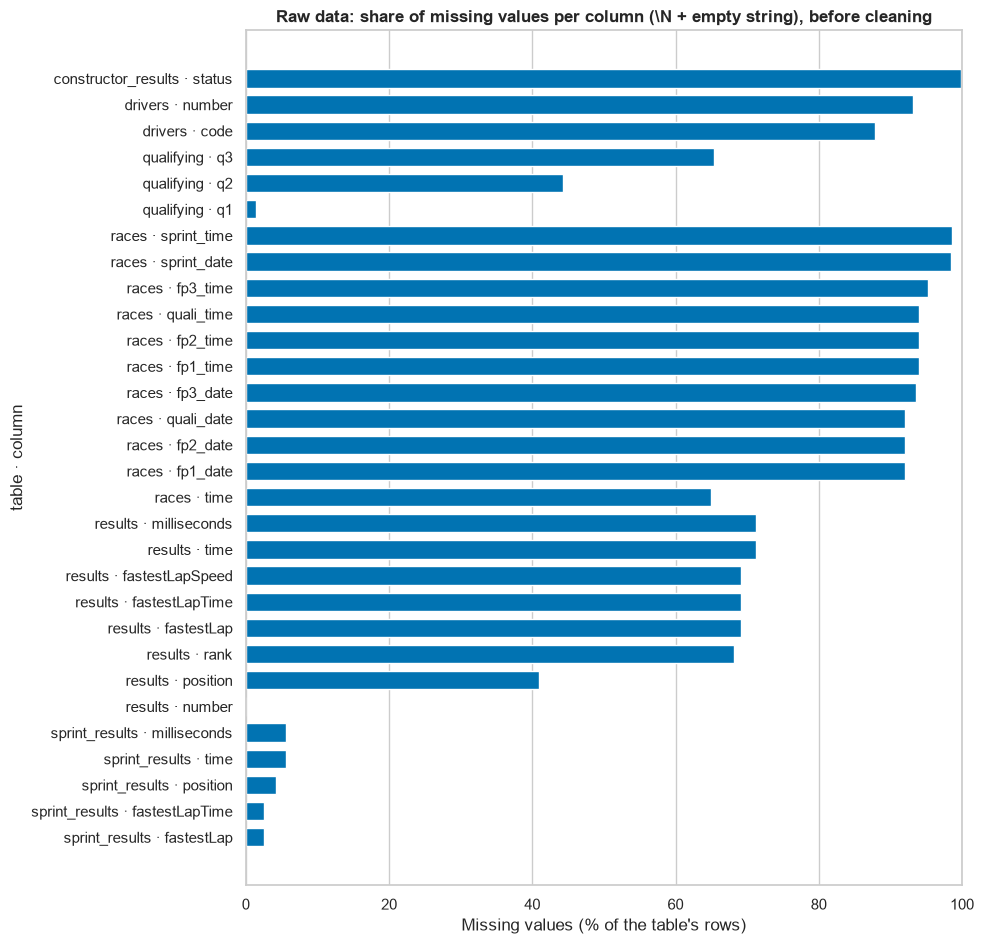

30 of 120 columns contain missing values, in 6 of 14 tables.
Totals: 160,076 '\N', 68 empty strings, 0 real NaN.
Empty strings found only in: [('qualifying', 'q3'), ('qualifying', 'q2')]


In [4]:
# ── 1. Missing-value map: three forms of "missing", per column ──────────────
def missing_report(tables: dict) -> pd.DataFrame:
    """Count each form of missing value per (table, column): the '\\N' sentinel, the empty string, and real NaN."""
    rows = []
    for t, df in tables.items():
        for c in df.columns:
            s = df[c]
            n_nan = int(s.isna().sum())
            as_text = s.astype("string")
            n_bsn = int((as_text == r"\N").sum())
            n_empty = int((as_text == "").sum())
            total = n_bsn + n_empty + n_nan
            rows.append({"table": t, "column": c, "rows": len(df), "backslash_N": n_bsn,
                         "empty_string": n_empty, "NaN": n_nan, "missing": total,
                         "pct_missing": round(100 * total / len(df), 2)})
    return pd.DataFrame(rows)


BEFORE = {}                                   # "before" snapshot, compared against the clean data in Section 7
BEFORE["missing"] = missing_report(raw)
affected = (BEFORE["missing"].query("missing > 0")
            .sort_values(["table", "pct_missing"], ascending=[True, False], ignore_index=True))

with pd.option_context("display.max_rows", 100):
    display(affected)

# Plot: % missing for every affected column, grouped by table (magnitude → bar chart, one hue).
plot_df = affected.assign(label=affected["table"] + " · " + affected["column"]).sort_values(
    ["table", "pct_missing"], ascending=[False, True])
fig, ax = plt.subplots(figsize=(10, 0.28 * len(plot_df) + 1.2))
ax.barh(plot_df["label"], plot_df["pct_missing"], color=sns.color_palette("colorblind")[0], height=0.7)
ax.set_xlim(0, 100)
ax.set_xlabel("Missing values (% of the table's rows)")
ax.set_ylabel("table · column")
ax.set_title("Raw data: share of missing values per column (\\N + empty string), before cleaning")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print(f"{len(affected)} of {len(BEFORE['missing'])} columns contain missing values, in "
      f"{affected['table'].nunique()} of {len(raw)} tables.")
print(f"Totals: {affected['backslash_N'].sum():,} '\\N', {affected['empty_string'].sum():,} empty strings, "
      f"{affected['NaN'].sum():,} real NaN.")
print("Empty strings found only in:", affected.loc[affected['empty_string'] > 0, ['table', 'column']]
      .apply(tuple, axis=1).tolist())

**Finding:** 30 of 120 columns (6 tables) have missing values: 160,076 `\N` and 68 empty strings (only in `q2`/`q3`). The key columns (`raceId`, `driverId`, `grid`, `positionOrder`, `statusId`) are complete.

**Why it matters:** Section 2 must replace both forms. Most gaps have a meaning (e.g. knocked out in Q1), so we mark them as NA rather than fill them.

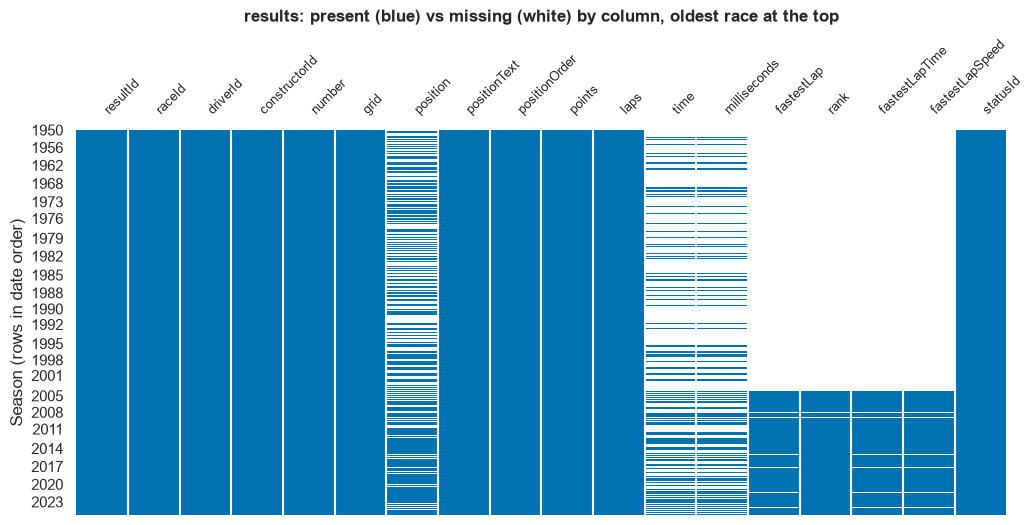

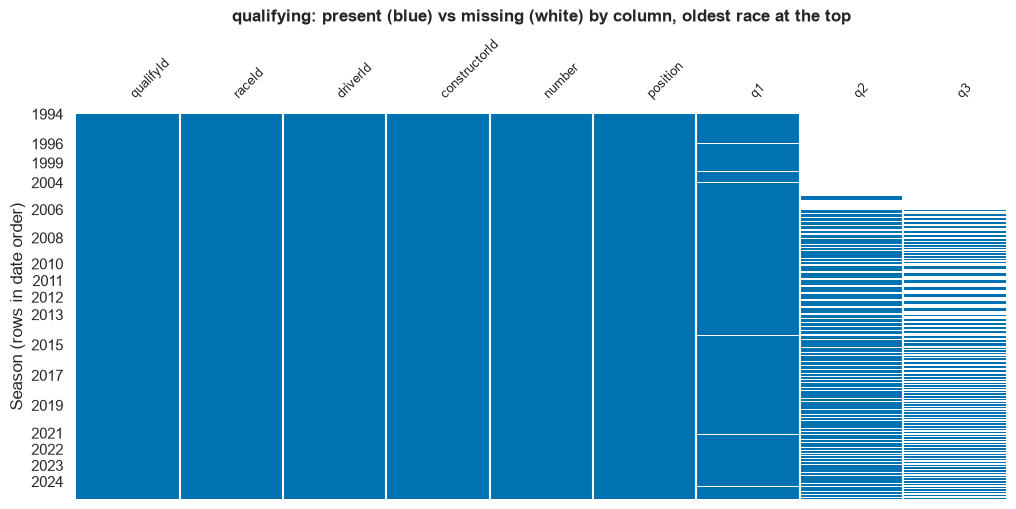

raw tables unchanged (fingerprints match).


In [5]:
# ── 1. Where in time are the gaps? missingno matrix, rows sorted by race date ─
def chronological_na_view(table: str) -> tuple[pd.DataFrame, pd.Series]:
    """Read-only view for plotting: rows sorted by race date, placeholders shown as NaN so missingno can see them.
    This does NOT clean anything; `raw` is untouched and the real replacement happens in Section 2.
    Returns the view and the season of each row (for axis labels)."""
    race_dates = raw["races"][["raceId", "date"]]
    view = raw[table].merge(race_dates, on="raceId", how="left", validate="many_to_one")
    view = view.sort_values(["date", "raceId"], kind="stable", ignore_index=True)
    return view.drop(columns="date").replace(PLACEHOLDERS, np.nan), view["date"].str[:4].astype(int)


def plot_missing_matrix(table: str, title: str) -> None:
    view, years = chronological_na_view(table)
    ax = msno.matrix(view, sparkline=False, figsize=(12, 5), fontsize=9, color=(0.0, 0.45, 0.70))
    # One label at the first row of each season, skipping labels that would sit closer than 4% of the rows apart.
    ticks, last = {}, -np.inf
    for row, year in years.drop_duplicates().items():
        if row - last >= 0.04 * len(years):
            ticks[row], last = year, row
    ticks = pd.Series(ticks)
    ax.set_yticks(ticks.index)
    ax.set_yticklabels(ticks.values)
    ax.set_ylabel("Season (rows in date order)")
    ax.set_title(title, fontsize=12, fontweight="bold", pad=12)
    plt.show()


plot_missing_matrix("results", "results: present (blue) vs missing (white) by column, oldest race at the top")
plot_missing_matrix("qualifying", "qualifying: present (blue) vs missing (white) by column, oldest race at the top")
assert all(fingerprint(raw[t]) == RAW_FINGERPRINT[t] for t in TABLES), "raw was modified"
print("raw tables unchanged (fingerprints match).")

**Finding:** the gaps follow eras. Fastest-lap columns are empty until the mid-2000s, qualifying starts in 1994 and is thin until 2003, and Q2/Q3 start around 2006.

**Why it matters:** missingness comes from what each era recorded, so it is handled by era (training window), not row by row.

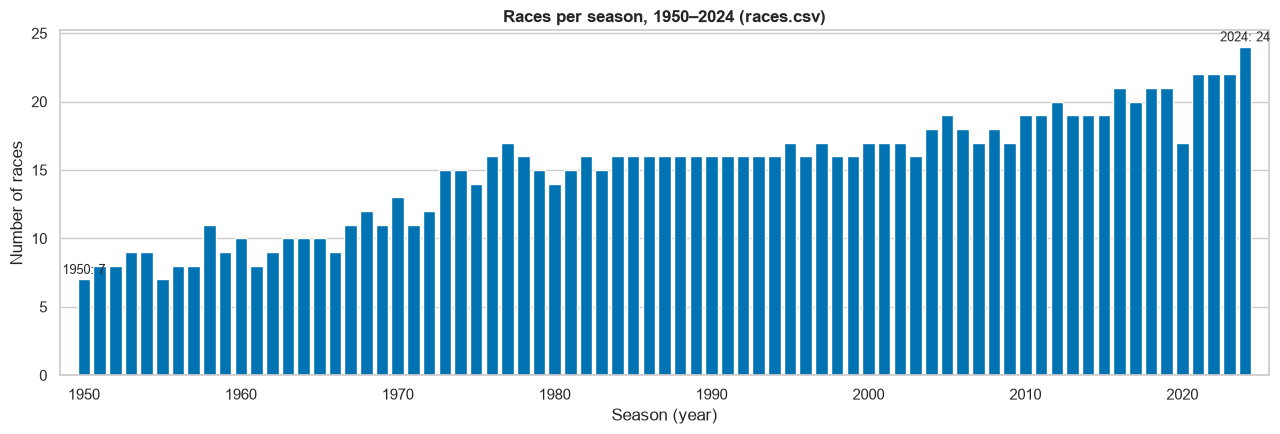

Seasons in races.csv: 1950–2024, 75 distinct years, 1,125 races.
Missing years inside that range: none
seasons.csv: 75 years; same set as races.csv: True; stored in year order: False
Fewest races: 7 (1950, 1955); most: 24 (2024)


In [6]:
# ── 1. Races per season: how many races, and which years? ───────────────────
race_years = raw["races"]["year"].astype(int)
season_years = raw["seasons"]["year"].astype(int)
races_per_season = race_years.value_counts().sort_index().rename("races")
BEFORE["races_per_season"] = races_per_season

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(races_per_season.index, races_per_season.values, color=sns.color_palette("colorblind")[0], width=0.8)
for yr in (races_per_season.idxmin(), races_per_season.idxmax()):        # label only the extremes
    ax.annotate(f"{yr}: {races_per_season[yr]}", (yr, races_per_season[yr]), xytext=(0, 4),
                textcoords="offset points", ha="center", fontsize=9)
ax.set_xlabel("Season (year)")
ax.set_ylabel("Number of races")
ax.set_title("Races per season, 1950–2024 (races.csv)")
ax.set_xlim(1948.5, 2025.5)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

full_range = set(range(race_years.min(), race_years.max() + 1))
print(f"Seasons in races.csv: {race_years.min()}–{race_years.max()}, {race_years.nunique()} distinct years, "
      f"{len(raw['races']):,} races.")
print(f"Missing years inside that range: {sorted(full_range - set(race_years)) or 'none'}")
print(f"seasons.csv: {len(season_years)} years; same set as races.csv: {set(season_years) == set(race_years)}; "
      f"stored in year order: {season_years.is_monotonic_increasing or season_years.is_monotonic_decreasing}")
print(f"Fewest races: {races_per_season.min()} ({', '.join(map(str, races_per_season[races_per_season == races_per_season.min()].index))}); "
      f"most: {races_per_season.max()} ({', '.join(map(str, races_per_season[races_per_season == races_per_season.max()].index))})")

**Finding:** 1950–2024 is complete: 75 seasons and 1,125 races. Seasons grew from 7 to 24 races. 2020 had only 17 (COVID).

**Why it matters:** recent seasons hold far more races, and 2020 sits in the validation window, so validation is a little smaller.

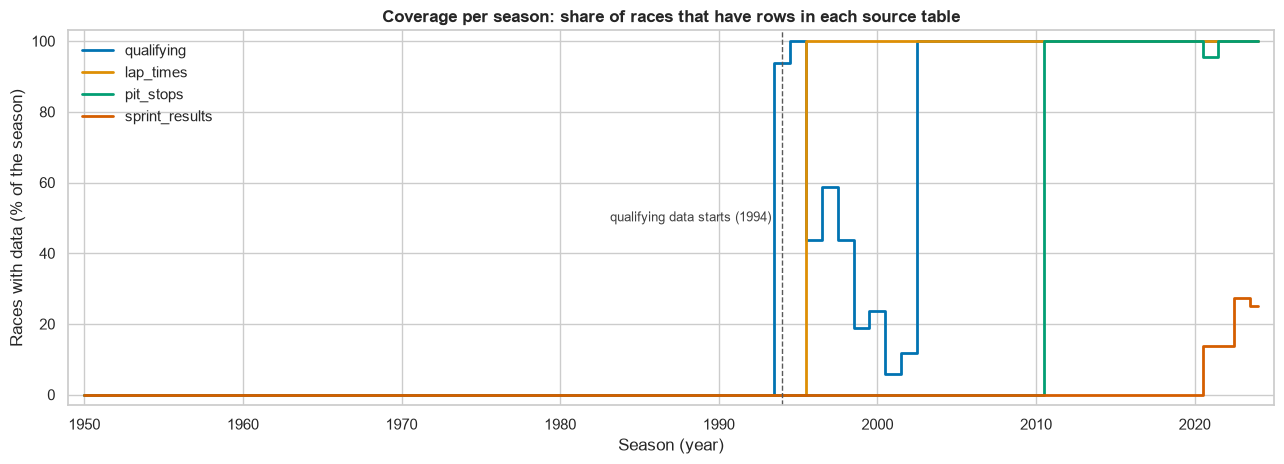

,first_season_any,first_season_100pct,partial_seasons,races_covered
qualifying,1994,1995,"1994 (94%), 1996 (44%), 1997 (59%), 1998 (44%), 1999 (19%), 2000 (24%), 2001 (6%), 2002 (12%)",494
lap_times,1996,1996,none,544
pit_stops,2011,2011,2021 (95%),285
sprint_results,2021,None,"2021 (14%), 2022 (14%), 2023 (27%), 2024 (25%)",18


In [7]:
# ── 1. Data-source coverage: which seasons have qualifying, lap, pit and sprint data? ─
COVERAGE_SOURCES = ["qualifying", "lap_times", "pit_stops", "sprint_results"]
race_year = raw["races"].set_index("raceId")["year"].astype(int)

coverage = pd.DataFrame({
    src: race_year.index.isin(raw[src]["raceId"].unique()) for src in COVERAGE_SOURCES
}, index=race_year.index).groupby(race_year).mean().mul(100).rename_axis("year")
BEFORE["coverage"] = coverage

fig, ax = plt.subplots(figsize=(13, 4.8))
palette = sns.color_palette("colorblind")
for i, src in enumerate(COVERAGE_SOURCES):
    ax.plot(coverage.index, coverage[src], color=palette[i], linewidth=2, label=src,
            drawstyle="steps-mid")
q_start = int(coverage.index[coverage["qualifying"] > 0].min())
ax.axvline(q_start, color="0.35", linestyle="--", linewidth=1)
ax.annotate(f"qualifying data starts ({q_start})", (q_start, 50), xytext=(-8, 0), textcoords="offset points",
            ha="right", va="center", fontsize=9, color="0.25")
ax.set_ylim(-3, 103)
ax.set_xlim(1949, 2025)
ax.set_xlabel("Season (year)")
ax.set_ylabel("Races with data (% of the season)")
ax.set_title("Coverage per season: share of races that have rows in each source table")
ax.legend(loc="upper left", frameon=False)
plt.tight_layout()
plt.show()


def coverage_summary(cov: pd.DataFrame) -> pd.DataFrame:
    """First season with any data, first season with 100% coverage, and seasons with partial coverage."""
    rows = {}
    for src in cov.columns:
        s = cov[src]
        partial = s[(s > 0) & (s < 100)]
        rows[src] = {
            "first_season_any": int(s[s > 0].index.min()),
            "first_season_100pct": int(s[s == 100].index.min()) if (s == 100).any() else None,
            "partial_seasons": ", ".join(f"{y} ({v:.0f}%)" for y, v in partial.items()) or "none",
            "races_covered": int(race_year.index.isin(raw[src]["raceId"].unique()).sum()),
        }
    return pd.DataFrame(rows).T


with pd.option_context("display.max_colwidth", 200):
    display(coverage_summary(coverage))

**Finding:** qualifying covers 94–100% of races in 1994–1995, only 6–59% in 1996–2002, and 100% from 2003. Lap times are complete from 1996 and pit stops from 2011 (one 2021 race is missing). Sprints are partial by design.

**Why it matters:** this is the brief's "qualifying-coverage drift". A feature can only be used where its source exists.

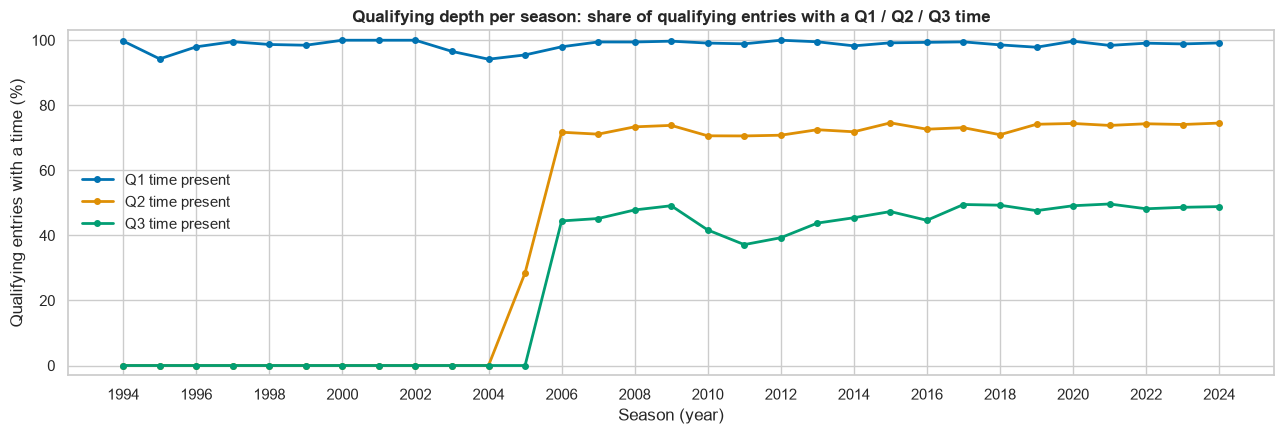

year,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
q1,99.7,94.3,98.0,99.5,98.7,98.5,100.0,100.0,100.0,96.6,94.2,95.5,98.0,99.5,99.5,99.7,99.1,98.9,100.0,99.5,98.3,99.2,99.3,99.5,98.6,97.8,99.7,98.4,99.1,98.9,99.2
q2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,28.5,71.7,71.1,73.4,73.8,70.6,70.6,70.8,72.5,71.9,74.6,72.6,73.1,71.0,74.2,74.4,73.8,74.3,74.1,74.5
q3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,44.4,45.2,47.8,49.1,41.7,37.2,39.3,43.8,45.4,47.3,44.6,49.5,49.3,47.6,49.1,49.7,48.2,48.6,48.9
entries,392.0,418.0,148.0,220.0,153.0,65.0,88.0,22.0,42.0,320.0,360.0,376.0,396.0,374.0,368.0,340.0,456.0,452.0,476.0,418.0,405.0,374.0,457.0,398.0,420.0,418.0,340.0,439.0,440.0,440.0,479.0


In [8]:
# ── 1. Qualifying depth: of the qualifying rows that exist, how many have a Q1, Q2, Q3 time? ─
quali = raw["qualifying"].assign(year=lambda d: d["raceId"].map(race_year))
SESSIONS = ["q1", "q2", "q3"]
quali_depth = (quali[SESSIONS].apply(lambda s: ~s.isin(PLACEHOLDERS))
               .groupby(quali["year"]).mean().mul(100))
quali_depth["entries"] = quali.groupby("year").size()
BEFORE["quali_depth"] = quali_depth

fig, ax = plt.subplots(figsize=(13, 4.5))
palette = sns.color_palette("colorblind")
for i, q in enumerate(SESSIONS):
    ax.plot(quali_depth.index, quali_depth[q], marker="o", markersize=4, linewidth=2, color=palette[i],
            label=f"{q.upper()} time present")
ax.set_ylim(-3, 103)
ax.set_xticks(range(1994, 2025, 2))
ax.set_xlabel("Season (year)")
ax.set_ylabel("Qualifying entries with a time (%)")
ax.set_title("Qualifying depth per season: share of qualifying entries with a Q1 / Q2 / Q3 time")
ax.legend(loc="center left", frameon=False)
plt.tight_layout()
plt.show()

display(quali_depth.round(1).T)

**Finding:** Q1 times are present for 94–100% of entries. Q2/Q3 only exist from 2005–2006, at about 74% and 49%, which matches 15 and 10 of 20 cars reaching them.

**Why it matters:** a missing Q2/Q3 means "knocked out", not lost data. Qualifying `position` is complete in every format, which makes it the safest qualifying feature.

In [9]:
# ── 1. Training-window evidence: how many rows, and how much qualifying, for each possible start year? ─
# Course split (F1 for Newcomers): train ≤ 2019, validation 2020–2021, test ≥ 2022.
# Counts use raw results rows (before de-duplication in Section 5), so they are indicative, not final.
WINDOW_STARTS = [1950, 1994, 2003, 2006]

res_rows = raw["results"][["raceId", "driverId"]].assign(year=lambda d: d["raceId"].map(race_year))
quali_keys = pd.MultiIndex.from_frame(raw["qualifying"][["raceId", "driverId"]])
res_rows["has_qualifying"] = pd.MultiIndex.from_frame(res_rows[["raceId", "driverId"]]).isin(quali_keys)


def window_row(start: int) -> dict:
    w = res_rows[res_rows["year"] >= start]
    return {"start_year": start,
            "all_rows": len(w),
            "train_rows_<=2019": int((w["year"] <= 2019).sum()),
            "val_rows_2020_2021": int(w["year"].between(2020, 2021).sum()),
            "test_rows_>=2022": int((w["year"] >= 2022).sum()),
            "pct_rows_with_qualifying": round(100 * w["has_qualifying"].mean(), 1),
            "pct_train_rows_with_qualifying": round(100 * w.loc[w["year"] <= 2019, "has_qualifying"].mean(), 1)}


training_windows = pd.DataFrame([window_row(s) for s in WINDOW_STARTS]).set_index("start_year")
BEFORE["training_windows"] = training_windows
display(training_windows)

# The per-season detail behind the 1994–2005 qualifying gap (from the coverage table above).
gap_detail = pd.DataFrame({
    "races": races_per_season.loc[1994:2005],
    "races_with_qualifying_%": BEFORE["coverage"].loc[1994:2005, "qualifying"].round(0),
    "result_rows_with_qualifying_%": res_rows.groupby("year")["has_qualifying"].mean().mul(100).round(1).loc[1994:2005],
}).T
display(gap_detail)

,all_rows,train_rows_<=2019,val_rows_2020_2021,test_rows_>=2022,pct_rows_with_qualifying,pct_train_rows_with_qualifying
start_year,,,,,,
1950,26759,24620,780,1359,39.2,33.9
1994,12358,10219,780,1359,84.9,81.8
2003,8970,6831,780,1359,99.7,99.7
2006,7914,5775,780,1359,99.7,99.6


year,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005
races,16.0,17.0,16.0,17.0,16.0,16.0,17.0,17.0,17.0,16.0,18.0,19.0
races_with_qualifying_%,94.0,100.0,44.0,59.0,44.0,19.0,24.0,6.0,12.0,100.0,100.0,100.0
result_rows_with_qualifying_%,88.3,100.0,43.5,58.5,43.8,18.5,23.6,5.9,11.6,100.0,100.0,100.0


**Finding: qualifying is complete only from 2003.** The 1996–2002 seasons have qualifying for just 6–59% of races.

- **2003 is the natural cut:** 6,831 training rows with 99.7% qualifying. Starting in 2006 loses about 1,050 rows for no gain. Starting in 1950 has 3.6× more rows but only 34% with qualifying.
- **Formats differ** (single-lap in 2003–2005, knockout from 2006), so qualifying features must be relative (position or gap-to-pole %), not raw seconds.
- **No years are removed here.** The window is chosen on validation in feature engineering, testing three options: 2003+, 1950+ with a grid fallback, and all years plus a `has_qualifying` flag.

**Limitations:** Question 1's qualifying-vs-grid comparison only works from 2003, so its "pre-2014" side is 2003–2013. Validation is small (780 rows, including COVID 2020), so small score gaps shouldn't be over-read.

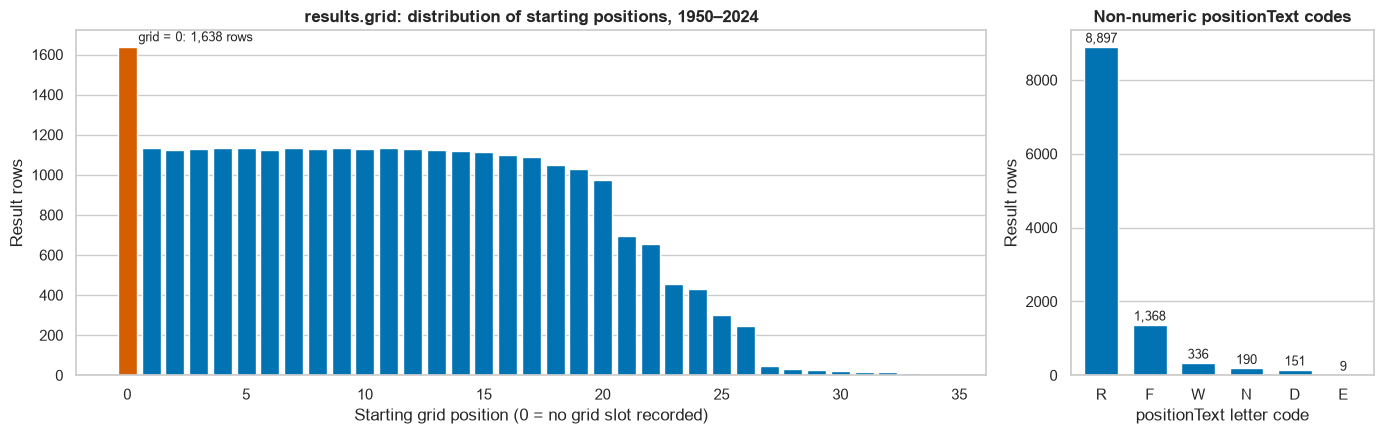

grid: min 0, max 34; grid = 0 in 1,638 of 26,759 rows (6.1%).
positionText: 15,808 numeric, 10,951 letter codes -> R=8,897, F=1,368, W=336, N=190, D=151, E=9


In [10]:
# ── 1. Results first look (a): grid distribution and positionText codes ─────
res = raw["results"]
grid = res["grid"].astype(int)                       # grid has no placeholders (cell above), so a plain cast is safe
grid_counts = grid.value_counts().sort_index()
pos_text = res["positionText"]
is_code = ~pos_text.str.fullmatch(r"\d+")
code_counts = pos_text[is_code].value_counts()
BEFORE["grid_counts"], BEFORE["positionText_codes"] = grid_counts, code_counts

palette = sns.color_palette("colorblind")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [3, 1]})

colors = [palette[3] if g == 0 else palette[0] for g in grid_counts.index]
ax1.bar(grid_counts.index, grid_counts.values, color=colors, width=0.8)
ax1.annotate(f"grid = 0: {grid_counts.get(0, 0):,} rows", (0, grid_counts.get(0, 0)), xytext=(8, 4),
             textcoords="offset points", fontsize=9)
ax1.set_xlabel("Starting grid position (0 = no grid slot recorded)")
ax1.set_ylabel("Result rows")
ax1.set_title("results.grid: distribution of starting positions, 1950–2024")
ax1.grid(axis="x", visible=False)

ax2.bar(code_counts.index, code_counts.values, color=palette[0], width=0.7)
for x, v in zip(code_counts.index, code_counts.values):
    ax2.annotate(f"{v:,}", (x, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax2.set_xlabel("positionText letter code")
ax2.set_ylabel("Result rows")
ax2.set_title("Non-numeric positionText codes")
ax2.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print(f"grid: min {grid.min()}, max {grid.max()}; grid = 0 in {grid_counts.get(0, 0):,} of {len(grid):,} rows "
      f"({100 * grid_counts.get(0, 0) / len(grid):.1f}%).")
print(f"positionText: {int((~is_code).sum()):,} numeric, {int(is_code.sum()):,} letter codes -> "
      + ", ".join(f"{k}={v:,}" for k, v in code_counts.items()))

**Finding:** `grid = 0` appears in 1,638 rows (6.1%), more than any real slot, so it is a special value. The positionText codes are R, F, W, N, D and E (8,897 / 1,368 / 336 / 190 / 151 / 9).

**Why it matters:** 0 must not read as "better than pole", and Section 6 establishes what it means. F and W mark entrants who never started.

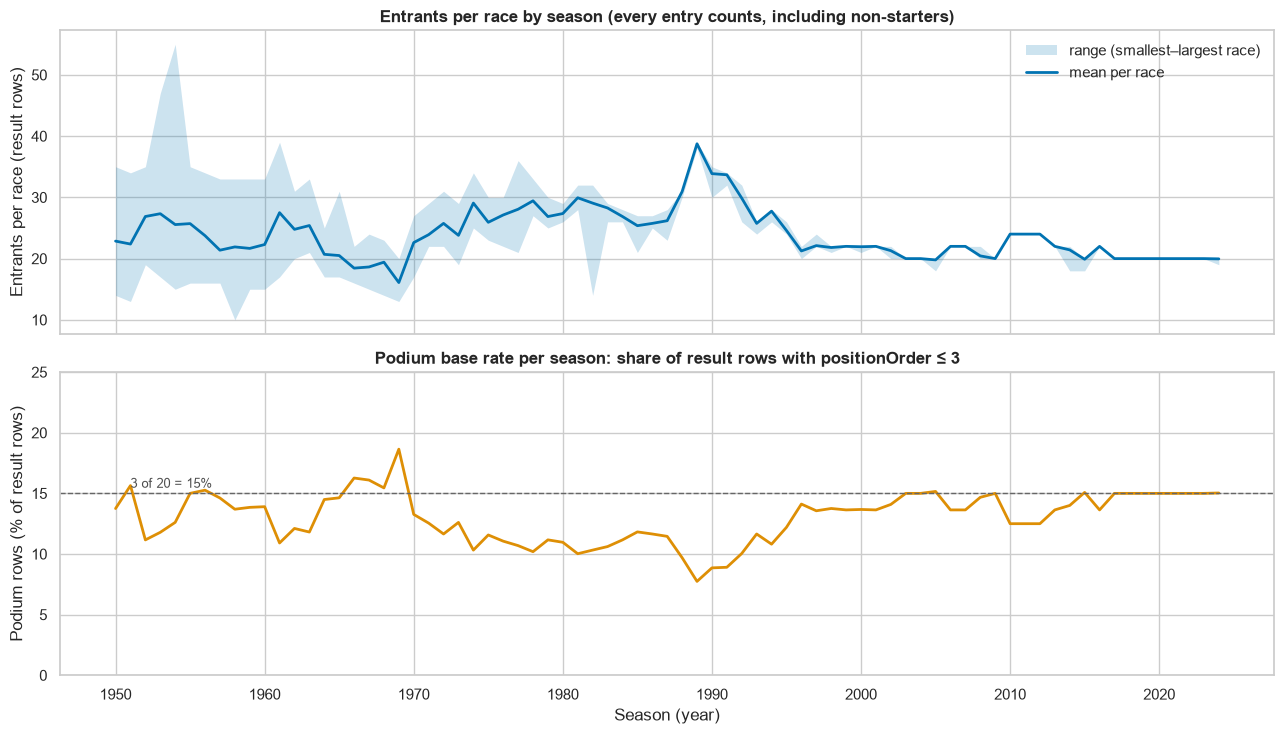

Overall podium rate: 12.7% of 26,759 rows.
  1950–1979: mean entrants 23.9, podium rate 12.7%
  1980–1995: mean entrants 29.0, podium rate 10.3%
  1996–2013: mean entrants 21.7, podium rate 13.8%
  2014–2024: mean entrants 20.3, podium rate 14.8%
Races without exactly 3 podium rows: 18 -> {4: 16, 7: 1, 5: 1} (years [1950, 1951, 1953, 1954, 1955, 1956, 1957, 1960])


In [11]:
# ── 1. Results first look (b): entrants per race and podium base rate per season ─
res_y = raw["results"][["raceId", "positionOrder"]].assign(
    year=lambda d: d["raceId"].map(race_year),
    podium=lambda d: d["positionOrder"].astype(int) <= 3)
entrants = res_y.groupby("raceId").agg(year=("year", "first"), entrants=("podium", "size"), podium_rows=("podium", "sum"))
per_season = entrants.groupby("year").agg(mean_entrants=("entrants", "mean"), min_entrants=("entrants", "min"),
                                          max_entrants=("entrants", "max"))
per_season["podium_rate_%"] = res_y.groupby("year")["podium"].mean().mul(100)
BEFORE["entrants_per_season"] = per_season

palette = sns.color_palette("colorblind")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True)
ax1.fill_between(per_season.index, per_season["min_entrants"], per_season["max_entrants"], color=palette[0],
                 alpha=0.2, linewidth=0, label="range (smallest–largest race)")
ax1.plot(per_season.index, per_season["mean_entrants"], color=palette[0], linewidth=2, label="mean per race")
ax1.set_ylabel("Entrants per race (result rows)")
ax1.set_title("Entrants per race by season (every entry counts, including non-starters)")
ax1.legend(loc="upper right", frameon=False)

ax2.plot(per_season.index, per_season["podium_rate_%"], color=palette[1], linewidth=2)
ax2.axhline(100 * 3 / 20, color="0.4", linestyle="--", linewidth=1)
ax2.annotate("3 of 20 = 15%", (1951, 15), xytext=(0, 4), textcoords="offset points", fontsize=9, color="0.3")
ax2.set_ylabel("Podium rows (% of result rows)")
ax2.set_xlabel("Season (year)")
ax2.set_title("Podium base rate per season: share of result rows with positionOrder ≤ 3")
ax2.set_ylim(0, 25)
plt.tight_layout()
plt.show()

print(f"Overall podium rate: {100 * res_y['podium'].mean():.1f}% of {len(res_y):,} rows.")
for label, (a, b) in {"1950–1979": (1950, 1979), "1980–1995": (1980, 1995), "1996–2013": (1996, 2013),
                      "2014–2024": (2014, 2024)}.items():
    s = per_season.loc[a:b]
    print(f"  {label}: mean entrants {s['mean_entrants'].mean():.1f}, podium rate "
          f"{100 * res_y.loc[res_y['year'].between(a, b), 'podium'].mean():.1f}%")
odd = entrants[entrants["podium_rows"] != 3]
print(f"Races without exactly 3 podium rows: {len(odd)} -> {odd['podium_rows'].value_counts().to_dict()} "
      f"(years {sorted(odd['year'].unique().tolist())})")

**Finding:** the podium rate follows field size, about 3 ÷ entrants: 10.3% in 1980–1995 (big fields) and 14.8% in 2014–2024. 18 races from 1950–1960 have more than 3 podium rows.

**Why it matters:** podiums are rare, so accuracy is misleading and we need PR-AUC and F1. The extra podium rows are probably shared drives (checked in Sections 4–5).

## 2. Sentinel handling

The Ergast files mark missing values with text placeholders. Before replacing them, we check that `\N` and the empty string are the only forms in use, and how many cells each table will lose to NA.

In [12]:
# ── 2. Sentinel handling · SEE: which values would be replaced, and are there other hidden forms? ─
# (a) Other spellings of "missing" that sometimes hide in CSVs. Each is counted as a whole cell value,
#     plus whitespace-only cells, so we know whether \N and "" are really the only placeholders.
CANDIDATES = ["NA", "N/A", "NaN", "nan", "NULL", "null", "None", "none", "-", "--", "?", "\\n", "0000-00-00"]
candidate_hits = []
for t, df in raw.items():
    for c in df.columns:
        s = df[c]
        for cand in CANDIDATES:
            n = int((s == cand).sum())
            if n:
                candidate_hits.append({"table": t, "column": c, "value": cand, "rows": n,
                                       "example_row": df.loc[s == cand].iloc[0].to_dict()})
        n_ws = int(s.str.fullmatch(r"\s+").sum())
        if n_ws:
            candidate_hits.append({"table": t, "column": c, "value": "<whitespace>", "rows": n_ws, "example_row": None})
candidate_hits = pd.DataFrame(candidate_hits, columns=["table", "column", "value", "rows", "example_row"])
print("Other possible placeholder spellings found:", "none" if candidate_hits.empty else "")
if not candidate_hits.empty:
    with pd.option_context("display.max_colwidth", 120):
        display(candidate_hits)

# (b) What Section 2 will replace: the measured \N and "" counts per table (from the Section 1 snapshot).
to_replace = (BEFORE["missing"].groupby("table")[["backslash_N", "empty_string"]].sum()
              .assign(total=lambda d: d.sum(axis=1), columns_affected=BEFORE["missing"].query("missing > 0")
                      .groupby("table").size())
              .fillna({"columns_affected": 0}).astype(int).sort_values("total", ascending=False))
display(to_replace)
print(f"Cells to replace: {to_replace['total'].sum():,} "
      f"({to_replace['backslash_N'].sum():,} '\\N' + {to_replace['empty_string'].sum():,} empty strings) "
      f"in {int((to_replace['total'] > 0).sum())} tables.")

Other possible placeholder spellings found: none


,backslash_N,empty_string,total,columns_affected
table,,,,
results,122887,0,122887,8
constructor_results,12608,0,12608,1
qualifying,11600,68,11668,3
races,11349,0,11349,11
drivers,1559,0,1559,2
sprint_results,73,0,73,5
driver_standings,0,0,0,0
constructors,0,0,0,0
constructor_standings,0,0,0,0


Cells to replace: 160,144 (160,076 '\N' + 68 empty strings) in 6 tables.


**Finding:** no other spelling of "missing" (`NA`, `NULL`, `None`, `-`, whitespace, ...) appears anywhere. Only `\N` and `""` are used, in 6 tables (160,144 cells).

**Why it matters:** replacing exactly these two forms is complete, so nothing fake survives into the type conversion.

In [13]:
# ── 2. Sentinel handling · SEE: what would each way of handling the placeholders cost? ─
n_bsn = int(BEFORE["missing"]["backslash_N"].sum())
n_empty = int(BEFORE["missing"]["empty_string"].sum())

# Rows that contain at least one placeholder, per affected table (what "drop incomplete rows" would delete).
row_loss = pd.DataFrame({
    t: {"rows": len(raw[t]), "rows_with_a_placeholder": int(raw[t].isin(PLACEHOLDERS).any(axis=1).sum())}
    for t in to_replace.index[to_replace["total"] > 0]
}).T
row_loss["pct_rows_lost_if_dropped"] = (100 * row_loss["rows_with_a_placeholder"] / row_loss["rows"]).round(1)
display(row_loss)

res_raw = raw["results"]
podium_mask = res_raw["positionOrder"].astype(int) <= 3
podium_lost = int((podium_mask & res_raw.isin(PLACEHOLDERS).any(axis=1)).sum())

alternatives = pd.DataFrame([
    {"option": "A. Drop every row that has a placeholder",
     "rows_removed": int(row_loss["rows_with_a_placeholder"].sum()), "results_podium_rows_lost": podium_lost,
     "placeholders_left": 0, "invented_values": 0},
    {"option": "B. Replace only '\\N' with NA",
     "rows_removed": 0, "results_podium_rows_lost": 0, "placeholders_left": n_empty, "invented_values": 0},
    {"option": "C. Replace '\\N' and '' with NA (no rows removed)",
     "rows_removed": 0, "results_podium_rows_lost": 0, "placeholders_left": 0, "invented_values": 0},
    {"option": "D. Fill placeholders with a value (e.g. 0 or the column mean)",
     "rows_removed": 0, "results_podium_rows_lost": 0, "placeholders_left": 0, "invented_values": n_bsn + n_empty},
]).set_index("option")
display(alternatives)
print(f"results has {int(podium_mask.sum()):,} podium rows; option A would delete {podium_lost:,} of them "
      f"({100 * podium_lost / podium_mask.sum():.0f}%).")

,rows,rows_with_a_placeholder,pct_rows_lost_if_dropped
results,26759,22494,84.1
constructor_results,12625,12608,99.9
qualifying,10494,6865,65.4
races,1125,1125,100.0
drivers,861,802,93.1
sprint_results,360,20,5.6


,rows_removed,results_podium_rows_lost,placeholders_left,invented_values
option,,,,
A. Drop every row that has a placeholder,43914,2168,0,0
B. Replace only '\N' with NA,0,0,68,0
C. Replace '\N' and '' with NA (no rows removed),0,0,0,0
D. Fill placeholders with a value (e.g. 0 or the column mean),0,0,0,160144


results has 3,397 podium rows; option A would delete 2,168 of them (64%).


### Decision: replace `\N` and `""` with NA, keep every row

Only these two placeholders exist (160,144 cells in 6 tables). We turn them into NA in the `clean` copy and remove no rows.

- **Not A (drop rows):** it would delete 84% of `results`, all of `races` and 93% of `drivers` (it would also remove 64% of the podium rows).
- **Not B (only `\N`):** 68 empty strings would remain and break the time conversion in Section 3.
- **Not D (fill with 0/mean):** it would invent 160,144 values. A Q3 time of 0 s would look like the fastest lap ever.

The gaps carry meaning, so they stay missing:

- **`qualifying.q2`, `q3`:** the driver was knocked out before that session (2006+), or the session did not exist (1994–2005). A filled Q3 time would make a backmarker look like a top-10 qualifier.
- **`qualifying.q1`:** the driver took part but set no valid lap. Qualifying `position` is still recorded for these drivers, so nothing is lost.
- **`results.position`:** the driver was not classified (retired, disqualified, etc.). `positionOrder` is complete and is the target source.
- **`results.time`, `milliseconds`, `fastestLap*`, `rank`:** not recorded for that driver or era. These are post-race columns and never features.
- **`races` session dates/times, `drivers.number`/`code`:** not recorded in older seasons. Not used for modelling.

Any filling-in a model needs is decided later, in feature engineering, and learned from the training seasons only.

In [14]:
# ── 2. Sentinel handling · ACT: build `clean` with \N and "" turned into NA ─
CLEANING_LOG = []                                   # one entry per change; shown in Section 7, saved in Section 8


def log_step(table: str, step: str, affected: int, unit: str, reason: str) -> None:
    CLEANING_LOG.append({"table": table, "step": step, "affected": affected, "unit": unit, "reason": reason})


clean = {}
for t, df in raw.items():
    is_placeholder = df.isin(PLACEHOLDERS)
    clean[t] = df.mask(is_placeholder)              # copy of raw; placeholder cells become NA, everything else unchanged
    n = int(is_placeholder.to_numpy().sum())
    if n:
        log_step(t, "Section 2: sentinels to NA", n, "cells", "'\\N' and '' are text placeholders for missing values")

print(f"`clean` built: {len(clean)} tables; {sum(e['affected'] for e in CLEANING_LOG):,} cells set to NA "
      f"in {len(CLEANING_LOG)} tables.")

`clean` built: 14 tables; 160,144 cells set to NA in 6 tables.


**Done:** `clean` holds a copy of all 14 tables, with 160,144 placeholder cells set to NA in 6 of them. The change is recorded in `CLEANING_LOG`.

**Why it matters:** cleaning happens on copies only, as the brief requires. The log will become the cleaning-log table in Section 7.

In [15]:
# ── 2. Sentinel handling · VERIFY: prove the replacement did exactly what was decided ─
expected = BEFORE["missing"].groupby("table")["missing"].sum()
check = pd.DataFrame({
    "placeholders_before": expected,
    "NA_after": {t: int(clean[t].isna().to_numpy().sum()) for t in TABLES},
    "placeholders_left": {t: int(clean[t].isin(PLACEHOLDERS).to_numpy().sum()) for t in TABLES},
    "rows_raw": {t: len(raw[t]) for t in TABLES},
    "rows_clean": {t: len(clean[t]) for t in TABLES},
}).loc[TABLES]
display(check)

for t in TABLES:
    assert check.loc[t, "placeholders_left"] == 0, f"{t}: placeholders remain"
    assert check.loc[t, "NA_after"] == check.loc[t, "placeholders_before"], f"{t}: NA count differs from placeholders"
    assert clean[t].shape == raw[t].shape and list(clean[t].columns) == list(raw[t].columns), f"{t}: shape changed"
    kept = clean[t].notna()
    assert (clean[t][kept] == raw[t][kept]).to_numpy()[kept.to_numpy()].all(), f"{t}: a real value changed"
    assert fingerprint(raw[t]) == RAW_FINGERPRINT[t], f"{t}: raw was modified"

print(f"All checks passed for {len(TABLES)} tables: 0 placeholders left, "
      f"{check['NA_after'].sum():,} NA = {check['placeholders_before'].sum():,} placeholders measured before, "
      f"row counts unchanged, every real value identical to raw, raw untouched.")

,placeholders_before,NA_after,placeholders_left,rows_raw,rows_clean
circuits,0,0,0,77,77
constructors,0,0,0,212,212
constructor_results,12608,12608,0,12625,12625
constructor_standings,0,0,0,13391,13391
drivers,1559,1559,0,861,861
driver_standings,0,0,0,34863,34863
races,11349,11349,0,1125,1125
results,122887,122887,0,26759,26759
qualifying,11668,11668,0,10494,10494
lap_times,0,0,0,589081,589081


All checks passed for 14 tables: 0 placeholders left, 160,144 NA = 160,144 placeholders measured before, row counts unchanged, every real value identical to raw, raw untouched.


**Verified:** 0 placeholders left, NA count = 160,144 = the placeholders measured before, row counts unchanged, every real value identical to `raw`, and `raw` untouched.

**Why it matters:** the sentinel step did exactly what was decided and nothing else. `clean` is now the starting point for typing in Section 3.

## 3. Semantic typing

Every column is still text. Here we give dates real date types, turn lap and stop times into seconds, and make IDs and counts numeric. First we look at every raw format that the conversion has to handle.

In [16]:
# ── 3. Semantic typing · SEE: current dtypes and every raw format in the date/time columns ─
print("dtypes in clean right now:", sorted({str(d) for df in clean.values() for d in df.dtypes}))

# Ordered patterns: the first match wins. Decimals are optional (1950s times were often whole seconds).
# Anything unmatched is reported as "OTHER" with examples.
FORMATS = {
    "date YYYY-MM-DD":       r"\d{4}-\d{2}-\d{2}",
    "clock HH:MM:SS":        r"\d{2}:\d{2}:\d{2}",
    "h:mm:ss.sss":           r"\d+:\d{2}:\d{2}(?:\.\d+)?",
    "m:ss.sss":              r"\d{1,2}:\d{2}(?:\.\d+)?",
    "ss.sss":                r"\d+\.\d+",
    "+ss.sss (gap)":         r"\+\d+(?:\.\d+)?",
    "+m:ss.sss (gap)":       r"\+\d+:\d{2}(?:\.\d+)?",
}
TIME_COLUMNS = {
    "races": ["date", "time"], "drivers": ["dob"],
    "qualifying": ["q1", "q2", "q3"],
    "results": ["time", "fastestLapTime"], "sprint_results": ["time", "fastestLapTime"],
    "lap_times": ["time"], "pit_stops": ["time", "duration"],
}


def format_profile(table: str, column: str) -> list[dict]:
    s = clean[table][column].dropna()
    label = pd.Series("OTHER", index=s.index)
    for name, rx in reversed(FORMATS.items()):        # reversed so the first pattern in FORMATS wins
        label[s.str.fullmatch(rx)] = name
    out = []
    for name, grp in s.groupby(label):
        out.append({"table": table, "column": column, "format": name, "values": len(grp),
                    "examples": " | ".join(grp.drop_duplicates().head(3))})
    return out


formats_seen = pd.DataFrame([row for t, cols in TIME_COLUMNS.items() for c in cols for row in format_profile(t, c)])
with pd.option_context("display.max_rows", 60, "display.max_colwidth", 60):
    display(formats_seen)

n_colon = int(clean["pit_stops"]["duration"].str.contains(":", na=False).sum())
print(f"pit_stops.duration values containing ':' (long stops, minutes:seconds): {n_colon}")
unmatched = formats_seen.loc[formats_seen["format"] == "OTHER", ["table", "column"]].apply(tuple, axis=1).tolist()
print(f"Columns with an unmatched (OTHER) format: {unmatched or 'none'}")

dtypes in clean right now: ['str']


,table,column,format,values,examples
0,races,date,date YYYY-MM-DD,1125,2009-03-29 | 2009-04-05 | 2009-04-19
1,races,time,clock HH:MM:SS,394,06:00:00 | 09:00:00 | 07:00:00
2,drivers,dob,date YYYY-MM-DD,861,1985-01-07 | 1977-05-10 | 1985-06-27
3,qualifying,q1,m:ss.sss,10338,1:26.572 | 1:26.103 | 1:25.664
4,qualifying,q2,m:ss.sss,5847,1:25.187 | 1:25.315 | 1:25.452
5,qualifying,q3,m:ss.sss,3629,1:26.714 | 1:26.869 | 1:27.079
6,results,time,+m:ss.sss (gap),2193,+1:08.130 | +1:10.041 | +1:16.220
7,results,time,+ss.sss (gap),4359,+5.478 | +8.163 | +17.181
8,results,time,h:mm:ss.sss,1125,1:34:50.616 | 1:31:18.555 | 1:31:06.970
9,results,time,m:ss.sss,3,24:34.899 | 42:53.7 | 3:27.071


pit_stops.duration values containing ':' (long stops, minutes:seconds): 517
Columns with an unmatched (OTHER) format: none


**Finding:** all columns are still text. The duration columns use three formats: `m:ss.sss` (most lap and qualifying times), `ss.sss` (most pit stops), and `h:mm:ss.sss`. That last one includes 43 laps longer than an hour in `lap_times`. 517 pit-stop durations use minutes (`16:44.718`). `pit_stops.time` and `races.time` are clock times, not durations. `results.time` mixes winner times and `+gap` strings. One gap, `+1:10`, has no decimals: it is a 70-second gap in the 1954 British GP, timed to whole seconds, and it matches `milliseconds`.

**Why it matters:** one parser must handle `ss.sss`, `m:ss.sss` and `h:mm:ss.sss`, with decimals optional. Clock times stay as time of day. `results.time` is not converted, because `milliseconds` already holds the race time as a number, and the column is post-race anyway.

In [17]:
# ── 3. Semantic typing · one time parser for ss.sss, m:ss.sss and h:mm:ss.sss, tested on edge cases ─
# Optional hours and minutes, seconds with optional decimals. "+gap" strings and clock times are NOT durations
# and are deliberately rejected (they become NA and are counted as failures).
DURATION_RE = r"^(?:(?:(?P<h>\d+):)?(?P<m>\d+):)?(?P<s>\d+(?:\.\d+)?)$"


def parse_duration(values: pd.Series) -> pd.Series:
    """Convert duration strings to seconds (float). Missing stays NaN; anything unparseable becomes NaN."""
    text = values.astype("string").str.strip()
    parts = text.str.extract(DURATION_RE)
    h, m, s = (parts[k].astype(float) for k in ("h", "m", "s"))
    seconds = h.fillna(0) * 3600 + m.fillna(0) * 60 + s
    out_of_range = (m.notna() & (s >= 60)) | (h.notna() & (m >= 60))      # e.g. "1:75.0" is not a real time
    return seconds.mask(out_of_range).astype(float)


def parse_failures(values: pd.Series) -> pd.Series:
    """Values that were present but could not be parsed (for reporting)."""
    return values[values.notna() & parse_duration(values).isna()]


# Unit tests: input -> expected seconds (NaN = must be rejected / stay missing).
TESTS = [
    ("26.898", 26.898, "pit stop, plain seconds"),
    ("16:44.718", 16 * 60 + 44.718, "long pit stop with a colon (one of the 517)"),
    ("1:26.572", 86.572, "qualifying / lap time"),
    ("2:05:05.152", 2 * 3600 + 5 * 60 + 5.152, "lap longer than an hour (one of the 43)"),
    ("42:53.7", 42 * 60 + 53.7, "one decimal place"),
    ("1:10", 70.0, "whole seconds, no decimals (1950s timing)"),
    ("59", 59.0, "integer seconds"),
    (" 1:26.572 ", 86.572, "surrounding spaces"),
    (np.nan, np.nan, "missing stays missing"),
    ("+5.478", np.nan, "gap to the winner is not a duration"),
    ("1:75.000", np.nan, "seconds >= 60 is invalid"),
    ("abc", np.nan, "garbage text"),
    ("", np.nan, "empty string"),
]
inputs = pd.Series([t[0] for t in TESTS], dtype="object")
got = parse_duration(inputs)
test_table = pd.DataFrame({"input": inputs, "expected_s": [t[1] for t in TESTS], "parsed_s": got,
                           "case": [t[2] for t in TESTS]})
test_table["pass"] = [(np.isnan(e) and np.isnan(g)) or np.isclose(e, g)
                      for e, g in zip(test_table["expected_s"], test_table["parsed_s"])]
display(test_table)
assert test_table["pass"].all(), "parse_duration failed a test case"
print(f"All {len(TESTS)} parser tests passed.")

,input,expected_s,parsed_s,case,pass
0,26.898,26.898,26.898,"pit stop, plain seconds",True
1,16:44.718,1004.718,1004.718,long pit stop with a colon (one of the 517),True
2,1:26.572,86.572,86.572,qualifying / lap time,True
3,2:05:05.152,7505.152,7505.152,lap longer than an hour (one of the 43),True
4,42:53.7,2573.700,2573.700,one decimal place,True
5,1:10,70.000,70.000,"whole seconds, no decimals (1950s timing)",True
6,59,59.000,59.000,integer seconds,True
7,1:26.572,86.572,86.572,surrounding spaces,True
8,NaN,NaN,NaN,missing stays missing,True
9,+5.478,NaN,NaN,gap to the winner is not a duration,True


All 13 parser tests passed.


**Finding:** `parse_duration` passes all 13 test cases: plain seconds, colon pit stops, laps over an hour, one decimal place, whole seconds, spaces, and missing values. It also rejects `+gap` strings, out-of-range seconds and garbage, which become NA instead of a wrong number.

**Why it matters:** one tested function converts every duration column the same way. Anything it cannot read is reported as a failure, never silently mis-converted.

### Decision: give every column its real type

- **Dates → datetime:** `races.date`, `drivers.dob`, and the `races` session dates (typed but not used, since they are 92–99% missing).
- **Durations → seconds (float), same column names:** `qualifying.q1/q2/q3`, `results.fastestLapTime`, `sprint_results.fastestLapTime`, `lap_times.time`, `pit_stops.duration`, all via the tested `parse_duration`.
- **Clock times → time of day (timedelta since midnight):** `races.time`, the `races` session times, and `pit_stops.time`. These are not durations.
- **IDs, counts and positions → nullable integers (`Int64`):** e.g. `raceId`, `grid`, `positionOrder`, `laps`, `milliseconds`. **Points, speeds and coordinates → float.**
- **Not converted:** `results.time` and `sprint_results.time` (they mix winner times and `+gaps`; `milliseconds` already holds the race time). Text columns stay text.
- **Names:** HTML entities (e.g. `&amp;`) are decoded so names read correctly.

Every conversion is checked: anything present that fails to parse is reported, and the lap and pit-stop seconds are cross-checked against their `milliseconds` columns.

In [18]:
# ── 3. Semantic typing · ACT: convert every column of `clean` to its real type ─
SESSION_DATES = ["fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]
SESSION_TIMES = ["fp1_time", "fp2_time", "fp3_time", "quali_time", "sprint_time"]
TYPE_PLAN = {
    "circuits": {"int": ["circuitId", "alt"], "float": ["lat", "lng"]},
    "constructors": {"int": ["constructorId"]},
    "constructor_results": {"int": ["constructorResultsId", "raceId", "constructorId"], "float": ["points"]},
    "constructor_standings": {"int": ["constructorStandingsId", "raceId", "constructorId", "position", "wins"],
                              "float": ["points"]},
    "drivers": {"int": ["driverId", "number"], "date": ["dob"]},
    "driver_standings": {"int": ["driverStandingsId", "raceId", "driverId", "position", "wins"], "float": ["points"]},
    "races": {"int": ["raceId", "year", "round", "circuitId"], "date": ["date"] + SESSION_DATES,
              "clock": ["time"] + SESSION_TIMES},
    "results": {"int": ["resultId", "raceId", "driverId", "constructorId", "number", "grid", "position",
                        "positionOrder", "laps", "milliseconds", "fastestLap", "rank", "statusId"],
                "float": ["points", "fastestLapSpeed"], "duration": ["fastestLapTime"]},
    "qualifying": {"int": ["qualifyId", "raceId", "driverId", "constructorId", "number", "position"],
                   "duration": ["q1", "q2", "q3"]},
    "lap_times": {"int": ["raceId", "driverId", "lap", "position", "milliseconds"], "duration": ["time"]},
    "pit_stops": {"int": ["raceId", "driverId", "stop", "lap", "milliseconds"], "clock": ["time"],
                  "duration": ["duration"]},
    "sprint_results": {"int": ["resultId", "raceId", "driverId", "constructorId", "number", "grid", "position",
                               "positionOrder", "laps", "milliseconds", "fastestLap", "statusId"],
                       "float": ["points"], "duration": ["fastestLapTime"]},
    "seasons": {"int": ["year"]},
    "status": {"int": ["statusId"]},
}
NAME_COLUMNS = {"circuits": ["name", "location"], "constructors": ["name"], "drivers": ["forename", "surname"],
                "races": ["name"]}


def to_int(s):   return pd.to_numeric(s, errors="coerce").astype("Float64")   # Int64 cast happens after the check
def to_float(s): return pd.to_numeric(s, errors="coerce").astype(float)
def to_date(s):  return pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
def to_clock(s): return pd.to_timedelta(s.where(s.str.fullmatch(r"\d{2}:\d{2}:\d{2}", na=False)), errors="coerce")


CONVERTERS = {"int": to_int, "float": to_float, "date": to_date, "clock": to_clock, "duration": parse_duration}
assert all(pd.api.types.is_string_dtype(clean[t][c]) for t, p in TYPE_PLAN.items() for cols in p.values() for c in cols), \
    "clean is already typed: re-run the notebook from Section 2 (ACT) so this cell starts from text"
BEFORE["dtypes"] = {t: clean[t].dtypes.astype(str) for t in TABLES}

typing_report = []
for t, plan in TYPE_PLAN.items():
    for kind, cols in plan.items():
        for c in cols:
            original = clean[t][c]
            converted = CONVERTERS[kind](original)
            failed = original.notna() & converted.isna()
            if kind == "int":                                  # an "integer" with a fractional part is a failure too
                failed |= converted.notna() & (converted % 1 != 0)
                converted = converted.where(~failed).round().astype("Int64")
            typing_report.append({"table": t, "column": c, "to": kind, "present": int(original.notna().sum()),
                                  "failed": int(failed.sum()),
                                  "failed_examples": " | ".join(original[failed].astype(str).unique()[:3])})
            clean[t][c] = converted
typing_report = pd.DataFrame(typing_report)
for t, grp in typing_report.groupby("table", sort=False):
    log_step(t, "Section 3: semantic typing", len(grp), "columns",
             "text converted to " + ", ".join(sorted(grp["to"].unique())))

# HTML entities in names (e.g. "&amp;"): decode and keep a before/after list of every changed value.
html_changes = []
for t, cols in NAME_COLUMNS.items():
    for c in cols:
        before = clean[t][c]
        after = before.map(lambda v: html.unescape(v) if isinstance(v, str) else v)
        changed = before.ne(after) & before.notna()
        html_changes += [{"table": t, "column": c, "before": b, "after": a}
                         for b, a in zip(before[changed], after[changed])]
        clean[t][c] = after
        if changed.any():
            log_step(t, f"Section 3: HTML entities decoded in {c}", int(changed.sum()), "values",
                     "names stored with HTML escapes such as &amp;")
html_changes = pd.DataFrame(html_changes, columns=["table", "column", "before", "after"])

print(f"Converted {len(typing_report)} columns in {typing_report['table'].nunique()} tables; "
      f"values that failed to parse: {typing_report['failed'].sum()}.")
print(f"HTML-entity names changed: {len(html_changes)}")
display(html_changes)

Converted 94 columns in 14 tables; values that failed to parse: 0.
HTML-entity names changed: 1


,table,column,before,after
0,constructors,name,Lotus-Pratt &amp; Whitney,Lotus-Pratt & Whitney


**Done:** 94 columns in all 14 tables were converted, and **0 present values failed to parse**. Only one name contained an HTML entity: `Lotus-Pratt &amp; Whitney` became `Lotus-Pratt & Whitney`.

**Why it matters:** every date, duration and number is now usable as a real value, with nothing silently turned into NA. Section 3 VERIFY checks the dtypes and cross-checks the seconds against `milliseconds`.

,before,after
circuits,str,"str×5, Int64×2, float64×2"
constructors,str,"str×4, Int64×1"
constructor_results,str,"Int64×3, float64×1, str×1"
constructor_standings,str,"Int64×5, float64×1, str×1"
drivers,str,"str×6, Int64×2, datetime64[us]×1"
driver_standings,str,"Int64×5, float64×1, str×1"
races,str,"datetime64[us]×6, timedelta64[us]×6, Int64×4, str×2"
results,str,"Int64×13, float64×3, str×2"
qualifying,str,"Int64×6, float64×3"
lap_times,str,"Int64×5, float64×1"


,table,column,rows,max_diff_ms,rows_off_by_more_than_1ms
0,lap_times,time,589081,0.0,0
1,pit_stops,duration,11371,0.0,0


drivers   lap_s  race_median_lap_s
year name                lap                                    
2011 Canadian Grand Prix 25        23  7507.5              103.3
2014 British Grand Prix  1          2  3702.6              100.9
                         2         18  3803.5              100.9

,min_s,median_s,max_s
column,,,
qualifying.q1,53.904,87.141,1002.640
qualifying.q2,53.647,87.125,132.470
qualifying.q3,53.377,87.039,129.776
results.fastestLapTime,55.404,90.268,202.300
sprint_results.fastestLapTime,68.321,84.892,124.760
lap_times.time,55.404,90.608,7507.547
pit_stops.duration,12.897,23.606,3069.017


Slowest q1 in the table (an outlier, kept as recorded and flagged):


,year,name,surname,position,q1
0,1995,Japanese Grand Prix,Blundell,24,1002.64


Pit stops >= 60 s: 517 (109 between 60 and 1000 s, 408 of 1000 s or more).
Age at first race: youngest 17.5, oldest 53.6 years (861 drivers).


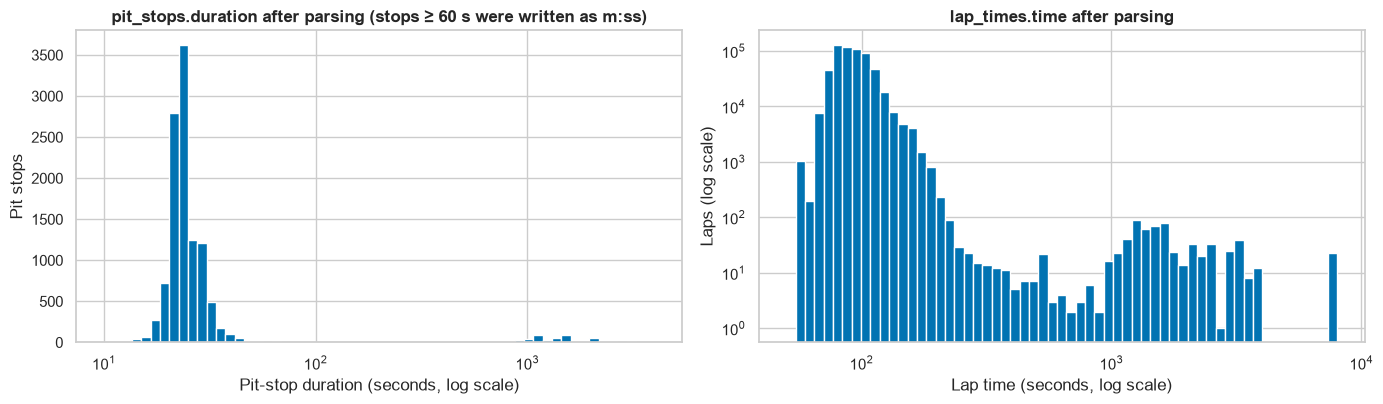

All typing checks passed: 0 parse failures, seconds match milliseconds within 1 ms, no HTML entities left, race dates 1950-05-13–2024-12-08, birth dates 1896-12-28–2005-05-08.


In [19]:
# ── 3. Semantic typing · VERIFY: right types, right values, plausible ranges ─
# (1) dtypes before vs after, per table.
dtype_summary = pd.DataFrame({
    "before": {t: ", ".join(sorted(BEFORE["dtypes"][t].unique())) for t in TABLES},
    "after": {t: ", ".join(f"{d}×{n}" for d, n in clean[t].dtypes.astype(str).value_counts().items()) for t in TABLES},
})
display(dtype_summary)

# (2) Parsed seconds vs the independent milliseconds column (must agree within 1 ms).
crosscheck = []
for t, col in [("lap_times", "time"), ("pit_stops", "duration")]:
    diff_ms = (clean[t][col] * 1000 - clean[t]["milliseconds"].astype(float)).abs()
    crosscheck.append({"table": t, "column": col, "rows": len(diff_ms), "max_diff_ms": round(diff_ms.max(), 3),
                       "rows_off_by_more_than_1ms": int((diff_ms > 1).sum())})
crosscheck = pd.DataFrame(crosscheck)
display(crosscheck)

# (3) The 43 laps longer than an hour: which races, and how do they compare with that race's normal laps?
lt = clean["lap_times"].merge(clean["races"][["raceId", "year", "name"]], on="raceId")
race_median = lt.groupby("raceId")["time"].transform("median")
long_laps = lt[lt["time"] >= 3600].assign(race_median_lap_s=race_median[lt["time"] >= 3600])
display(long_laps.groupby(["year", "name", "lap"]).agg(drivers=("driverId", "size"), lap_s=("time", "max"),
                                                       race_median_lap_s=("race_median_lap_s", "first")).round(1))

# (4) No HTML entities left in any text column.
entity_left = {f"{t}.{c}": int(clean[t][c].str.contains(r"&(?:[A-Za-z]+|#\d+);", na=False).sum())
               for t in TABLES for c in clean[t].columns if pd.api.types.is_string_dtype(clean[t][c])}
entity_left = {k: v for k, v in entity_left.items() if v}

# (5) Plausible ranges.
dur_cols = [("qualifying", "q1"), ("qualifying", "q2"), ("qualifying", "q3"), ("results", "fastestLapTime"),
            ("sprint_results", "fastestLapTime"), ("lap_times", "time"), ("pit_stops", "duration")]
ranges = pd.DataFrame([{"column": f"{t}.{c}", "min_s": clean[t][c].min(), "median_s": clean[t][c].median(),
                        "max_s": clean[t][c].max()} for t, c in dur_cols]).set_index("column").round(3)
display(ranges)
q1_outlier = (clean["qualifying"].nlargest(1, "q1")
              .merge(clean["races"][["raceId", "year", "name"]], on="raceId")
              .merge(clean["drivers"][["driverId", "surname"]], on="driverId"))
print("Slowest q1 in the table (an outlier, kept as recorded and flagged):")
display(q1_outlier[["year", "name", "surname", "position", "q1"]])
pit_s = clean["pit_stops"]["duration"]
print(f"Pit stops >= 60 s: {int((pit_s >= 60).sum())} ({int(pit_s.between(60, 1000, inclusive='left').sum())} "
      f"between 60 and 1000 s, {int((pit_s >= 1000).sum())} of 1000 s or more).")
race_dates = clean["races"]["date"]
dob = clean["drivers"]["dob"]
debut = (clean["results"].merge(clean["races"][["raceId", "date"]], on="raceId")
         .groupby("driverId")["date"].min().rename("debut"))
age_at_debut = (debut - clean["drivers"].set_index("driverId")["dob"]).dt.days / 365.25
print(f"Age at first race: youngest {age_at_debut.min():.1f}, oldest {age_at_debut.max():.1f} years "
      f"({age_at_debut.notna().sum()} drivers).")

# Distributions of two converted columns (log scale shows short and long values together).
palette = sns.color_palette("colorblind")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
ax1.hist(clean["pit_stops"]["duration"], bins=np.logspace(np.log10(10), np.log10(4000), 60), color=palette[0])
ax1.set_xscale("log")
ax1.set_xlabel("Pit-stop duration (seconds, log scale)")
ax1.set_ylabel("Pit stops")
ax1.set_title("pit_stops.duration after parsing (stops ≥ 60 s were written as m:ss)")
ax2.hist(clean["lap_times"]["time"], bins=np.logspace(np.log10(50), np.log10(8000), 60), color=palette[0])
ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_xlabel("Lap time (seconds, log scale)")
ax2.set_ylabel("Laps (log scale)")
ax2.set_title("lap_times.time after parsing")
plt.tight_layout()
plt.show()

assert typing_report["failed"].sum() == 0, "some present values failed to parse"
assert crosscheck["rows_off_by_more_than_1ms"].sum() == 0, "parsed seconds disagree with milliseconds"
assert not entity_left, f"HTML entities remain: {entity_left}"
assert race_dates.notna().all() and race_dates.between("1950-01-01", "2024-12-31").all(), "race date out of range"
assert age_at_debut.dropna().between(15, 60).all(), "implausible birth date (age at first race outside 15–60)"
assert (ranges["min_s"] > 0).all(), "a duration is zero or negative"
print("All typing checks passed: 0 parse failures, seconds match milliseconds within 1 ms, no HTML entities left, "
      f"race dates {race_dates.min().date()}–{race_dates.max().date()}, birth dates {dob.min().date()}–{dob.max().date()}.")

**Verified:** every table is now typed (`Int64`, `float64`, datetime, timedelta, with text only for names and codes). The parsed lap and pit-stop seconds match `milliseconds` exactly (0 ms difference across 600,452 rows). The 43 laps over an hour belong to two races (2011 Canadian GP lap 25 and 2014 British GP laps 1–2), where every driver has the same long lap. That points to a race stoppage, not a parsing error. All 517 pit stops of 60 s or more are exactly the 517 written as `m:ss`. Race dates run 1950-05-13 to 2024-12-08, and every driver was 17.5–53.6 years old at their first race.

**Flagged, kept as recorded:** one `q1` of 1,002.6 s (1995 Japanese GP, Blundell, qualified last). That is about 10× a normal lap. It is outside the 2003+ qualifying window, and relative qualifying features (position, gap to pole) limit its effect.

## 3b. Scope: remove the Indianapolis 500

The Indianapolis 500 counted toward the championship from 1950 to 1960, but it was a separate American oval race with its own drivers. We measure how separate it is, then remove it from `clean` so every later step (key checks, duplicates, flags, EDA) runs on the Formula 1 races only.

In [20]:
# ── 3b. Scope: Indianapolis 500 · SEE: which races, how many rows, and who raced in them ─
# Identified by race NAME + year, not by circuit: circuitId 19 (Indianapolis) also hosted the US Grand Prix later.
indy_races = clean["races"][clean["races"]["name"].eq("Indianapolis 500")]
INDY_RACE_IDS = set(indy_races["raceId"])
print(f"Races named 'Indianapolis 500': {len(indy_races)}, seasons {indy_races['year'].min()}–{indy_races['year'].max()}, "
      f"circuitIds {sorted(int(c) for c in indy_races['circuitId'].unique())}")
other_at_19 = clean["races"].query("circuitId == 19 and name != 'Indianapolis 500'")
print(f"Other races at circuitId 19 (must be kept): {len(other_at_19)} "
      f"-> {other_at_19.groupby('name')['year'].agg(['min', 'max', 'count']).to_dict('index')}")

# Rows in every race-level table that belong to these races.
RACE_TABLES = ["results", "qualifying", "driver_standings", "constructor_standings", "constructor_results",
               "lap_times", "pit_stops", "sprint_results"]
indy_rows = pd.DataFrame({t: {"rows": len(clean[t]), "indy_rows": int(clean[t]["raceId"].isin(INDY_RACE_IDS).sum())}
                          for t in RACE_TABLES}).T
indy_rows["pct"] = (100 * indy_rows["indy_rows"] / indy_rows["rows"]).round(2)
display(indy_rows)

# How separate is the Indy 500 field from the rest of each season?
res_year = clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId")
is_indy_row = res_year["raceId"].isin(INDY_RACE_IDS)
overlap = []
for yr, grp in res_year[res_year["year"] <= 1960].groupby("year"):
    indy_drivers = set(grp.loc[is_indy_row[grp.index], "driverId"])
    other_drivers = set(grp.loc[~is_indy_row[grp.index], "driverId"])
    overlap.append({"year": yr, "indy_entrants": int(is_indy_row[grp.index].sum()),
                    "indy_drivers": len(indy_drivers), "also_raced_another_GP_that_season": len(indy_drivers & other_drivers)})
overlap = pd.DataFrame(overlap).set_index("year")
display(overlap.T)
all_indy = set(res_year.loc[is_indy_row, "driverId"])
all_other = set(res_year.loc[~is_indy_row & (res_year["year"] <= 1960), "driverId"])
print(f"Across 1950–1960: {len(all_indy)} Indy 500 drivers; {len(all_indy & all_other)} of them also raced any other GP.")

Races named 'Indianapolis 500': 11, seasons 1950–1960, circuitIds [19]
Other races at circuitId 19 (must be kept): 8 -> {'United States Grand Prix': {'min': 2000, 'max': 2007, 'count': 8}}


,rows,indy_rows,pct
results,26759,405,1.51
qualifying,10494,0,0.00
driver_standings,34863,669,1.92
constructor_standings,13391,26,0.19
constructor_results,12625,21,0.17
lap_times,589081,0,0.00
pit_stops,11371,0,0.00
sprint_results,360,0,0.00


year,1950,1951,1952,1953,1954,1955,1956,1957,1958,1959,1960
indy_entrants,35,34,33,47,55,35,34,33,33,33,33
indy_drivers,34,34,33,37,42,35,34,33,33,33,33
also_raced_another_GP_that_season,0,0,1,0,0,0,0,0,0,1,0


Across 1950–1960: 107 Indy 500 drivers; 3 of them also raced any other GP.


**Finding:** 11 races named "Indianapolis 500" (1950–1960), all at circuitId 19. The same circuit also hosted 8 United States Grands Prix (2000–2007), which must stay, so the race is identified by name, not circuit. Its rows: 405 in `results`, 669 in `driver_standings`, 26 in `constructor_standings` and 21 in `constructor_results`. Of its 107 drivers, only 3 raced any other Grand Prix in 1950–1960 (at most 1 in any season).

**Why it matters:** the Indy 500 field barely overlaps with the rest of Formula 1, so its rows describe a different competition. They would also distort the home-race question (American drivers at an American race).

In [21]:
# ── 3b. Scope: Indianapolis 500 · SEE: evidence that it is a different competition ─
ev = (clean["results"]
      .merge(clean["races"][["raceId", "year", "circuitId"]], on="raceId")
      .merge(clean["drivers"][["driverId", "nationality"]], on="driverId")
      .merge(clean["circuits"][["circuitId", "country"]], on="circuitId"))
ev["indy"] = ev["raceId"].isin(INDY_RACE_IDS)
ev["podium"] = ev["positionOrder"] <= 3
era = ev[ev["year"] <= 1960]                                    # compare against the other races of the same seasons
indy, other = era[era["indy"]], era[~era["indy"]]
ever_elsewhere = set(ev.loc[~ev["indy"], "driverId"])           # drivers with any non-Indy race, any year
home_usa = (ev["nationality"] == "American") & ev["country"].isin(["USA", "United States"])
indy_podium_drivers = set(indy.loc[indy["podium"], "driverId"])

evidence = pd.DataFrame([
    ("Drivers who also raced another GP in 1950–1960",
     f"{len(set(indy.driverId) & set(other.driverId))} of {indy.driverId.nunique()}"),
    ("Constructors that also raced another GP in 1950–1960",
     f"{len(set(indy.constructorId) & set(other.constructorId))} of {indy.constructorId.nunique()}"),
    ("Entrants per race (mean)", f"Indy {indy.groupby('raceId').size().mean():.1f} vs other GPs "
                                 f"{other.groupby('raceId').size().mean():.1f}"),
    ("Share of rows with an American driver", f"Indy {100 * (indy.nationality == 'American').mean():.0f}% vs other GPs "
                                               f"{100 * (other.nationality == 'American').mean():.0f}%"),
    ("'American driver racing in the USA' rows (all years) that are Indy",
     f"{int((home_usa & ev['indy']).sum())} of {int(home_usa.sum())} "
     f"({100 * (home_usa & ev['indy']).sum() / home_usa.sum():.0f}%)"),
    ("Podium rows in 1950–1960 that are Indy", f"{int(indy.podium.sum())} of {int(era.podium.sum())}"),
    ("Indy podium drivers who ever raced any other F1 race",
     f"{len(indy_podium_drivers & ever_elsewhere)} of {len(indy_podium_drivers)}"),
], columns=["check", "result"]).set_index("check")
with pd.option_context("display.max_colwidth", 80):
    display(evidence)

,result
check,
Drivers who also raced another GP in 1950–1960,3 of 107
Constructors that also raced another GP in 1950–1960,3 of 34
Entrants per race (mean),Indy 36.8 vs other GPs 22.0
Share of rows with an American driver,Indy 100% vs other GPs 9%
'American driver racing in the USA' rows (all years) that are Indy,404 of 525 (77%)
Podium rows in 1950–1960 that are Indy,36 of 304
Indy podium drivers who ever raced any other F1 race,2 of 25


### Decision: remove the Indianapolis 500 (11 races, 1950–1960) from `clean`

- **Separate drivers and constructors.** Only 3 of its 107 drivers and 3 of its 34 constructors raced any other Grand Prix in those seasons.
- **A different competition.** It was an American oval race with larger fields (36.8 vs 22.0 entrants per race) that counted for points in name only.
- **It distorts Question 2 (home advantage).** Its field is 100% American at an American track: 404 of all 525 "American driver racing in the USA" rows (77%) come from these 11 races.
- **Irrelevant to what we predict.** The test seasons (2022–2024) contain no such race, and the course guide calls excluding it "a defensible choice".

*Supporting evidence:* 23 of its 25 podium drivers never raced any other F1 race, which confirms the separation above.

**What we keep:** circuit 19 (it also hosted 8 US Grands Prix, 2000–2007) and the Indy-only drivers in `drivers`, which become drivers with no results. **Limitation:** 1950–1960 standings after each Indy race still include its championship points; this only matters if training uses the 1950s.

In [22]:
# ── 3b. Scope: Indianapolis 500 · ACT: remove the 11 races and every row that belongs to them ─
rows_before_indy = {t: len(clean[t]) for t in ["races"] + RACE_TABLES}
removed_indy = {}
for t in ["races"] + RACE_TABLES:
    is_indy = clean[t]["raceId"].isin(INDY_RACE_IDS)
    removed_indy[t] = int(is_indy.sum())
    clean[t] = clean[t].loc[~is_indy].reset_index(drop=True)      # filtering by raceId: re-running removes nothing more
    if removed_indy[t]:
        log_step(t, "Section 3b: Indianapolis 500 removed", removed_indy[t], "rows",
                 "separate competition: 3 of 107 drivers raced other GPs; 77% of US-home rows; not in test seasons")
print("Rows removed:", {t: n for t, n in removed_indy.items() if n})

Rows removed: {'races': 11, 'results': 405, 'driver_standings': 669, 'constructor_standings': 26, 'constructor_results': 21}


**Done:** removed 11 races, 405 results, 669 driver-standings rows, 26 constructor-standings rows and 21 constructor-results rows. Each removal is logged in `CLEANING_LOG`.

**Why it matters:** every later step (key checks, duplicates, flags, the "after" EDA) now runs on Formula 1 races only.

In [23]:
# ── 3b. Scope: Indianapolis 500 · VERIFY: gone everywhere, nothing else lost ─
indy_check = pd.DataFrame({
    "rows_before": rows_before_indy, "removed": removed_indy,
    "rows_after": {t: len(clean[t]) for t in rows_before_indy},
    "indy_raceIds_left": {t: int(clean[t]["raceId"].isin(INDY_RACE_IDS).sum()) for t in rows_before_indy},
})
display(indy_check)

us_gp_kept = clean["races"].query("circuitId == 19")
assert (indy_check["indy_raceIds_left"] == 0).all(), "Indy rows remain"
assert (indy_check["rows_before"] - indy_check["removed"] == indy_check["rows_after"]).all(), "unexpected row loss"
assert not clean["races"]["name"].eq("Indianapolis 500").any()
assert len(us_gp_kept) == 8 and us_gp_kept["name"].eq("United States Grand Prix").all(), "US GP at circuit 19 lost"

# Before/after for the affected seasons: races per season and mean entrants per race.
res_after = clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId")
seasons_5060 = pd.DataFrame({
    "races_before": BEFORE["races_per_season"].loc[1950:1960],
    "races_after": clean["races"]["year"].value_counts().sort_index().loc[1950:1960],
    "entrants_per_race_before": BEFORE["entrants_per_season"]["mean_entrants"].loc[1950:1960].round(1),
    "entrants_per_race_after": res_after.groupby(["year", "raceId"]).size().groupby("year").mean().loc[1950:1960].round(1),
}).T
display(seasons_5060)
print(f"Indianapolis 500 removed from every table; the {len(us_gp_kept)} US Grands Prix at circuit 19 "
      f"({us_gp_kept['year'].min()}–{us_gp_kept['year'].max()}) are kept; no other rows lost.")

,rows_before,removed,rows_after,indy_raceIds_left
races,1125,11,1114,0
results,26759,405,26354,0
qualifying,10494,0,10494,0
driver_standings,34863,669,34194,0
constructor_standings,13391,26,13365,0
constructor_results,12625,21,12604,0
lap_times,589081,0,589081,0
pit_stops,11371,0,11371,0
sprint_results,360,0,360,0


year,1950,1951,1952,1953,1954,1955,1956,1957,1958,1959,1960
races_before,7,8,8,9,9,7,8,8,11,9,10
races_after,6,7,7,8,8,6,7,7,10,8,9
entrants_per_race_before,22.9,22.4,26.9,27.3,25.6,25.7,23.8,21.4,21.9,21.7,22.3
entrants_per_race_after,20.8,20.7,26.0,24.9,21.9,24.2,22.3,19.7,20.8,20.2,21.1


Indianapolis 500 removed from every table; the 8 US Grands Prix at circuit 19 (2000–2007) are kept; no other rows lost.


**Verified:** no Indianapolis 500 raceId remains in any table. For every table, rows before − removed = rows after (e.g. `races` 1,125 → 1,114, `results` 26,759 → 26,354). The 8 US Grands Prix at circuit 19 (2000–2007) are kept. Each 1950–1960 season loses exactly one race, and mean entrants per race fall by 1–4 (e.g. 1954: 25.6 → 21.9).

**Why it matters:** the removal touched exactly the 11 races and nothing else. Section 1 stays the "before" snapshot (Indy included). From here on, every number excludes it.

## 4. Key integrity audit

The brief requires primary keys to be unique and non-null, and foreign keys to reconcile. We check every table, then the links between tables, then a set of logical rules.

In [24]:
# ── 4. Key integrity · primary keys: unique and never empty? ─────────────────
# "id" = the table's own ID column. "natural" = the real-world combination that should also be unique
# (one standing per driver per race, one lap per driver per lap number, ...).
PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"],
    "races": ["raceId"], "seasons": ["year"], "status": ["statusId"],
    "results": ["resultId"], "qualifying": ["qualifyId"], "sprint_results": ["resultId"],
    "constructor_results": ["constructorResultsId"], "constructor_standings": ["constructorStandingsId"],
    "driver_standings": ["driverStandingsId"],
    "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"],
}
NATURAL_KEYS = {
    "races": ["year", "round"], "results": ["raceId", "driverId"], "qualifying": ["raceId", "driverId"],
    "sprint_results": ["raceId", "driverId"], "driver_standings": ["raceId", "driverId"],
    "constructor_standings": ["raceId", "constructorId"], "constructor_results": ["raceId", "constructorId"],
}


def key_check(table: str, key: list[str], kind: str) -> dict:
    df = clean[table]
    null_rows = int(df[key].isna().any(axis=1).sum())
    dup_rows = int(df.duplicated(subset=key, keep=False).sum())
    return {"table": table, "key": " + ".join(key), "kind": kind, "rows": len(df), "null_key_rows": null_rows,
            "rows_in_duplicate_keys": dup_rows, "duplicate_keys": int(df[df.duplicated(subset=key, keep=False)]
                                                                          .drop_duplicates(subset=key).shape[0]),
            "ok": null_rows == 0 and dup_rows == 0}


pk_report = pd.DataFrame([key_check(t, k, "id") for t, k in PRIMARY_KEYS.items()]
                         + [key_check(t, k, "natural") for t, k in NATURAL_KEYS.items()])
display(pk_report)
n_id_ok = int(pk_report.loc[pk_report["kind"] == "id", "ok"].sum())
print(f"ID keys: {n_id_ok} of {len(PRIMARY_KEYS)} unique and non-null.")
failed = pk_report.loc[~pk_report["ok"], ["table", "key", "duplicate_keys"]]
print("Keys that fail:", "none" if failed.empty else failed.to_dict("records"))

,table,key,kind,rows,null_key_rows,rows_in_duplicate_keys,duplicate_keys,ok
0,circuits,circuitId,id,77,0,0,0,True
1,constructors,constructorId,id,212,0,0,0,True
2,drivers,driverId,id,861,0,0,0,True
3,races,raceId,id,1114,0,0,0,True
4,seasons,year,id,75,0,0,0,True
5,status,statusId,id,139,0,0,0,True
6,results,resultId,id,26354,0,0,0,True
7,qualifying,qualifyId,id,10494,0,0,0,True
8,sprint_results,resultId,id,360,0,0,0,True
9,constructor_results,constructorResultsId,id,12604,0,0,0,True


ID keys: 14 of 14 unique and non-null.
Keys that fail: [{'table': 'results', 'key': 'raceId + driverId', 'duplicate_keys': 64}]


**Finding:** all 14 ID keys are unique and never empty, and so are the natural keys of `races`, `qualifying`, `sprint_results`, both standings tables and `constructor_results`. The only failure is `results` on `raceId + driverId`: 64 pairs appear more than once (131 rows). That is 85 pairs before the Indianapolis 500 was removed.

**Why it matters:** every table can be joined safely by its ID. The one exception is exactly the grain problem the brief describes (a driver with more than one row in a race), which Section 5 resolves.

In [25]:
# ── 4. Key integrity · foreign keys: does every reference point to a row that exists? ─
# (child table, child columns, parent table, parent columns)
FOREIGN_KEYS = [
    ("results", ["raceId"], "races", ["raceId"]), ("results", ["driverId"], "drivers", ["driverId"]),
    ("results", ["constructorId"], "constructors", ["constructorId"]), ("results", ["statusId"], "status", ["statusId"]),
    ("qualifying", ["raceId"], "races", ["raceId"]), ("qualifying", ["driverId"], "drivers", ["driverId"]),
    ("qualifying", ["constructorId"], "constructors", ["constructorId"]),
    ("sprint_results", ["raceId"], "races", ["raceId"]), ("sprint_results", ["driverId"], "drivers", ["driverId"]),
    ("sprint_results", ["constructorId"], "constructors", ["constructorId"]),
    ("sprint_results", ["statusId"], "status", ["statusId"]),
    ("driver_standings", ["raceId"], "races", ["raceId"]), ("driver_standings", ["driverId"], "drivers", ["driverId"]),
    ("constructor_standings", ["raceId"], "races", ["raceId"]),
    ("constructor_standings", ["constructorId"], "constructors", ["constructorId"]),
    ("constructor_results", ["raceId"], "races", ["raceId"]),
    ("constructor_results", ["constructorId"], "constructors", ["constructorId"]),
    ("lap_times", ["raceId"], "races", ["raceId"]), ("lap_times", ["driverId"], "drivers", ["driverId"]),
    ("pit_stops", ["raceId"], "races", ["raceId"]), ("pit_stops", ["driverId"], "drivers", ["driverId"]),
    ("races", ["circuitId"], "circuits", ["circuitId"]), ("races", ["year"], "seasons", ["year"]),
    # Row-level links: every lap, pit stop and qualifying entry should belong to a driver who has a result in that race.
    ("lap_times", ["raceId", "driverId"], "results", ["raceId", "driverId"]),
    ("pit_stops", ["raceId", "driverId"], "results", ["raceId", "driverId"]),
    ("qualifying", ["raceId", "driverId"], "results", ["raceId", "driverId"]),
]


def orphans(child: str, ccols: list[str], parent: str, pcols: list[str]) -> pd.DataFrame:
    """Child rows whose key combination does not exist in the parent table."""
    parent_keys = pd.MultiIndex.from_frame(clean[parent][pcols].drop_duplicates())
    child_keys = pd.MultiIndex.from_frame(clean[child][ccols])
    return clean[child][~child_keys.isin(parent_keys)]


fk_report = []
for child, ccols, parent, pcols in FOREIGN_KEYS:
    o = orphans(child, ccols, parent, pcols)
    fk_report.append({"child": child, "column(s)": " + ".join(ccols), "parent": parent, "child_rows": len(clean[child]),
                      "orphan_rows": len(o), "pct_orphans": round(100 * len(o) / len(clean[child]), 3),
                      "example_orphan_keys": o[ccols].drop_duplicates().head(3).to_dict("records") if len(o) else ""})
fk_report = pd.DataFrame(fk_report)
with pd.option_context("display.max_colwidth", 70):
    display(fk_report)

# The other direction: parents that nothing points to (not errors, but worth knowing).
races_without_results = clean["races"][~clean["races"]["raceId"].isin(clean["results"]["raceId"])]
drivers_without_results = clean["drivers"][~clean["drivers"]["driverId"].isin(clean["results"]["driverId"])]
print(f"Links checked: {len(fk_report)}; links with orphans: {int((fk_report['orphan_rows'] > 0).sum())}.")
print(f"Races with no results: {len(races_without_results)}; drivers with no results: {len(drivers_without_results)}; "
      f"status codes never used in results or sprints: "
      f"{int((~clean['status']['statusId'].isin(pd.concat([clean['results']['statusId'], clean['sprint_results']['statusId']]))).sum())}.")

,child,column(s),parent,child_rows,orphan_rows,pct_orphans,example_orphan_keys
0,results,raceId,races,26354,0,0.0,
1,results,driverId,drivers,26354,0,0.0,
2,results,constructorId,constructors,26354,0,0.0,
3,results,statusId,status,26354,0,0.0,
4,qualifying,raceId,races,10494,0,0.0,
5,qualifying,driverId,drivers,10494,0,0.0,
6,qualifying,constructorId,constructors,10494,0,0.0,
7,sprint_results,raceId,races,360,0,0.0,
8,sprint_results,driverId,drivers,360,0,0.0,
9,sprint_results,constructorId,constructors,360,0,0.0,


Links checked: 26; links with orphans: 0.
Races with no results: 0; drivers with no results: 103; status codes never used in results or sprints: 3.


**Finding:** all 26 links reconcile, with **0 orphan rows**. Every `raceId`, `driverId`, `constructorId`, `statusId`, `circuitId` and season points to an existing row. Every lap, pit stop and qualifying entry also belongs to a driver who has a result in that race. In the other direction, every race has results. 103 drivers have no results: they are exactly the drivers who only raced the Indianapolis 500, removed in Section 3b. 3 status codes are never used (2 were already unused in the raw data, and 1 was only used by Indy rows).

**Why it matters:** the brief requires foreign keys to reconcile, and they do, so joins across tables lose no rows. The unused drivers and status codes point to nothing, so they cannot break a join, and they are kept.

In [26]:
# ── 4. Key integrity · logical checks: do the values obey the rules of a race result? ─
res = clean["results"].merge(clean["races"][["raceId", "year", "name"]], on="raceId")
checks, details = [], {}

# (1) positionOrder unique within each race, and running 1..N.
dup_po = res[res.duplicated(["raceId", "positionOrder"], keep=False)]
checks.append(("positionOrder unique within each race", dup_po["raceId"].nunique(), "races"))
details["duplicate positionOrder"] = (dup_po.groupby(["year", "name"]).size().rename("rows_sharing_a_position")
                                      .reset_index())
per_race = res.groupby("raceId")["positionOrder"].agg(["max", "size", "min"])
checks.append(("positionOrder runs 1..N (max = number of rows)", int((per_race["max"] != per_race["size"]).sum()), "races"))

# (2) Numeric position agrees with positionText; missing position goes with a letter code.
pos_mismatch = res[(res["position"].notna() & (res["positionText"] != res["position"].astype("string")))
                   | (res["position"].isna() & res["positionText"].str.fullmatch(r"\d+"))]
checks.append(("position matches positionText", len(pos_mismatch), "rows"))
details["position vs positionText"] = pos_mismatch[["year", "name", "driverId", "position", "positionText",
                                                    "positionOrder", "laps", "statusId"]]

# (3) grid is never negative; race dates inside the dataset's range.
checks.append(("grid >= 0", int((res["grid"] < 0).sum()), "rows"))
checks.append(("race date within 1950-01-01..2024-12-31",
               int((~clean["races"]["date"].between("1950-01-01", "2024-12-31")).sum()), "races"))

# (4) Cross-table rules (re-stated from the foreign-key cell so all rules sit in one table).
checks.append(("every qualifying entry has a results row",
               int(fk_report.query("child == 'qualifying' and parent == 'results'")["orphan_rows"].sum()), "rows"))
checks.append(("every results statusId exists in status",
               int(fk_report.query("child == 'results' and parent == 'status'")["orphan_rows"].sum()), "rows"))

# (5) Pit-stop numbers: stop k should exist for every k up to a driver's last stop.
ps = clean["pit_stops"]
stops = ps.groupby(["raceId", "driverId"])["stop"].agg(["max", "size"])
checks.append(("pit stops numbered 1..k with no gaps", int((stops["max"] != stops["size"]).sum()), "driver-races"))
top_stops = (stops.sort_values("max", ascending=False).head(5).reset_index()
             .merge(clean["races"][["raceId", "year", "name"]], on="raceId"))
details["most pit stops by one driver in one race"] = top_stops[["year", "name", "driverId", "max"]]

logic_report = pd.DataFrame(checks, columns=["check", "violations", "unit"])
logic_report["ok"] = logic_report["violations"] == 0
display(logic_report)
for title, table in details.items():
    if len(table):
        print(f"\n{title}:")
        display(table)

,check,violations,unit,ok
0,positionOrder unique within each race,40,races,False
1,positionOrder runs 1..N (max = number of rows),40,races,False
2,position matches positionText,2,rows,False
3,grid >= 0,0,rows,True
4,race date within 1950-01-01..2024-12-31,0,races,True
5,every qualifying entry has a results row,0,rows,True
6,every results statusId exists in status,0,rows,True
7,pit stops numbered 1..k with no gaps,8,driver-races,False



duplicate positionOrder:


,year,name,rows_sharing_a_position
0,1950,British Grand Prix,4
1,1950,French Grand Prix,4
2,1950,Italian Grand Prix,4
3,1951,French Grand Prix,6
4,1951,Italian Grand Prix,2
5,1952,Dutch Grand Prix,2
6,1952,French Grand Prix,4
7,1952,Swiss Grand Prix,2
8,1953,Argentine Grand Prix,2
9,1953,Belgian Grand Prix,2



position vs positionText:


,year,name,driverId,position,positionText,positionOrder,laps,statusId
1148,2005,Australian Grand Prix,18,<NA>,11,11,56,11
1151,2005,Australian Grand Prix,11,<NA>,14,14,55,12



most pit stops by one driver in one race:


,year,name,driverId,max
0,2024,Monaco Grand Prix,855,70
1,2024,Monaco Grand Prix,858,57
2,2024,Monaco Grand Prix,830,52
3,2024,Monaco Grand Prix,1,51
4,2024,Monaco Grand Prix,840,48


**Finding:** 4 rules hold everywhere (grid ≥ 0, dates in range, qualifying ↔ results, valid status). Three fail: shared `positionOrder` in 40 races (1950–1964, the shared-drive era), 2 rows in the 2005 Australian GP with an empty `position` but a numeric `positionText`, and pit-stop numbering gaps in 8 driver-races (6 of them in the 2024 Monaco GP, where a second stop is numbered 15–70).

**Why it matters:** each has a different cause. The shared positions are resolved in Section 5. The 2005 rows are fixed below. The pit-stop gaps are kept as recorded and documented: `pit_stops` is post-race and never a feature, and renumbering would hide the genuinely missing stops.

### Decision: fill `position` for the 2 classified 2005 Australian GP rows

Their `positionText` (11, 14) and `positionOrder` (11, 14) agree, and their status is a lapped finish, so they were classified finishers with `position` left empty. We fill `position` from `positionText`, only where all three agree. `positionOrder` (the target source) is not touched, and `position` is never a feature.

In [27]:
# ── 4. Key integrity · ACT: fill `position` where positionText holds the classified position ─
r = clean["results"]
text_as_number = pd.to_numeric(r["positionText"], errors="coerce")             # letter codes (R, F, ...) -> NaN
fill = r["position"].isna() & text_as_number.notna() & (text_as_number == r["positionOrder"])
position_fixed_ids = r.loc[fill, "resultId"].tolist()
clean["results"].loc[fill, "position"] = text_as_number[fill].astype("Int64")
if fill.any():
    log_step("results", "Section 4: position filled from positionText", int(fill.sum()), "rows",
             "classified finishers with an empty position; positionText and positionOrder agree")
print(f"Filled position for {int(fill.sum())} rows (resultIds {position_fixed_ids}).")

Filled position for 2 rows (resultIds [1149, 1152]).


In [28]:
# ── 4. Key integrity · VERIFY: position and positionText now agree in every row ─
r = clean["results"]
mismatch_after = r[(r["position"].notna() & (r["positionText"] != r["position"].astype("string")))
                   | (r["position"].isna() & r["positionText"].str.fullmatch(r"\d+"))]
display(r.loc[r["resultId"].isin(position_fixed_ids),
              ["resultId", "raceId", "driverId", "position", "positionText", "positionOrder", "statusId"]])
assert mismatch_after.empty, "position and positionText still disagree"
assert len(position_fixed_ids) in (0, 2), "expected exactly the 2 rows found by the logical check"
print(f"position matches positionText in all {len(r):,} rows; {len(position_fixed_ids)} rows were filled.")

,resultId,raceId,driverId,position,positionText,positionOrder,statusId
1148,1149,71,18,11,11,11,11
1151,1152,71,11,14,14,14,12


position matches positionText in all 26,354 rows; 2 rows were filled.


**Verified:** `position` now matches `positionText` in every row of `results`. The 2 filled rows read 11 and 14 in all three position columns.

**Why it matters:** the "position matches positionText" rule now passes. The only remaining exceptions are the documented shared positions (Section 5) and the pit-stop gaps.

## 4b. Scope: remove entrants who were never on the grid

Our unit is a driver who is a candidate **after qualifying**. Entrants ruled out in qualifying, or who withdrew without qualifying, were never candidates. We identify them using only what is known when qualifying ends, and remove them from `results`.

In [29]:
# ── 4b. Never on the grid · SEE: who would be removed, and who must stay ──────
# Decided by the REASON a driver did not take part, not by the grid value.
DNQ_STATUSES = ["Did not qualify", "Did not prequalify", "107% Rule"]
r = (clean["results"].merge(clean["races"][["raceId", "year", "name"]], on="raceId", how="left")
       .merge(clean["status"], on="statusId", how="left")
       .merge(clean["drivers"][["driverId", "surname"]], on="driverId", how="left"))
q_keys = pd.MultiIndex.from_frame(clean["qualifying"][["raceId", "driverId"]])
r["has_qualifying_row"] = pd.MultiIndex.from_frame(r[["raceId", "driverId"]]).isin(q_keys)
by_status = r["status"].isin(DNQ_STATUSES)
by_no_qualifying = (r["grid"] == 0) & r["positionText"].isin(["F", "W"]) & ~r["has_qualifying_row"]
remove_mask = by_status | by_no_qualifying

groups = pd.DataFrame([
    ("REMOVE", "status: did not (pre-)qualify / 107% rule", int(by_status.sum())),
    ("", "  of which grid > 0 (Ergast stored a qualifying rank)", int((by_status & (r["grid"] > 0)).sum())),
    ("REMOVE", "grid 0, F or W, no qualifying row (not already above)", int((by_no_qualifying & ~by_status).sum())),
    ("STAY", "W with a qualifying row (qualified, then withdrew)",
     int((r["positionText"].eq("W") & r["has_qualifying_row"] & ~remove_mask).sum())),
    ("STAY", "W with a grid slot, no qualifying row",
     int((r["positionText"].eq("W") & (r["grid"] > 0) & ~r["has_qualifying_row"] & ~remove_mask).sum())),
    ("STAY", "F not matched by either rule", int((r["positionText"].eq("F") & ~remove_mask).sum())),
    ("STAY", "pit-lane starters: grid 0 but laps > 0", int(((r["grid"] == 0) & (r["laps"] > 0) & ~remove_mask).sum())),
], columns=["action", "group", "rows"])
display(groups)
print(f"Rows to remove: {int(remove_mask.sum()):,}; results {len(r):,} -> {len(r) - int(remove_mask.sum()):,}")

# Accounting: every W and every F row lands in exactly one group.
is_W, is_Fc = r["positionText"].eq("W"), r["positionText"].eq("F")
w_removed, w_with_q = int((is_W & remove_mask).sum()), int((is_W & r["has_qualifying_row"] & ~remove_mask).sum())
w_slot_no_q = int((is_W & (r["grid"] > 0) & ~r["has_qualifying_row"] & ~remove_mask).sum())
assert w_removed + w_with_q + w_slot_no_q == int(is_W.sum()), "W rows do not add up"
assert int((is_Fc & remove_mask).sum()) + int((is_Fc & ~remove_mask).sum()) == int(is_Fc.sum())
print(f"W rows: {int(is_W.sum())} = {w_removed} removed + {w_with_q} with a qualifying row + "
      f"{w_slot_no_q} with a grid slot and no qualifying row (both kept).")
print(f"F rows: {int(is_Fc.sum()):,} = {int((is_Fc & remove_mask).sum()):,} removed + "
      f"{int((is_Fc & ~remove_mask).sum())} kept.")

COLS_4B = ["year", "name", "surname", "grid", "laps", "positionText", "status", "has_qualifying_row"]
print(f"Failed qualifiers with grid > 0 (removed by status), {r.loc[by_status & (r['grid'] > 0), 'year'].min()}–"
      f"{r.loc[by_status & (r['grid'] > 0), 'year'].max()}:")
display(r.loc[by_status & (r["grid"] > 0), COLS_4B].sort_values("year"))
print("F rows that stay (candidates at the cutoff):")
display(r.loc[r["positionText"].eq("F") & ~remove_mask, COLS_4B])

# Would also requiring laps == 0 change anything? (laps is post-race, so the rule should not need it.)
with_laps = remove_mask & (r["laps"] == 0)
print(f"Adding 'laps == 0' would keep {int((remove_mask & ~with_laps).sum())} extra row(s):")
display(r.loc[remove_mask & (r["laps"] > 0), COLS_4B])
w_qualified = r[r["positionText"].eq("W") & r["has_qualifying_row"] & ~remove_mask]

,action,group,rows
0,REMOVE,status: did not (pre-)qualify / 107% rule,1365
1,,of which grid > 0 (Ergast stored a qualifying rank),19
2,REMOVE,"grid 0, F or W, no qualifying row (not already above)",195
3,STAY,"W with a qualifying row (qualified, then withdrew)",68
4,STAY,"W with a grid slot, no qualifying row",74
5,STAY,F not matched by either rule,2
6,STAY,pit-lane starters: grid 0 but laps > 0,72


Rows to remove: 1,560; results 26,354 -> 24,794
W rows: 336 = 194 removed + 68 with a qualifying row + 74 with a grid slot and no qualifying row (both kept).
F rows: 1,368 = 1,366 removed + 2 kept.
Failed qualifiers with grid > 0 (removed by status), 1954–1997:


,year,name,surname,grid,laps,positionText,status,has_qualifying_row
19161,1954,Italian Grand Prix,de Riu,21,0,F,Did not qualify,False
17287,1964,British Grand Prix,Trintignant,25,0,F,Did not qualify,False
13546,1977,German Grand Prix,Heyer,25,9,F,Did not qualify,False
9406,1987,Australian Grand Prix,Caffi,27,0,F,Did not qualify,False
5633,1993,Brazilian Grand Prix,Capelli,26,0,F,Did not qualify,False
5165,1994,Brazilian Grand Prix,Belmondo,28,0,F,Did not qualify,False
5164,1994,Brazilian Grand Prix,Ratzenberger,27,0,F,Did not qualify,False
4401,1996,Australian Grand Prix,Montermini,22,0,F,107% Rule,False
4719,1996,Japanese Grand Prix,Lavaggi,20,0,F,Did not qualify,False
4599,1996,British Grand Prix,Badoer,22,0,F,Did not qualify,False


F rows that stay (candidates at the cutoff):


,year,name,surname,grid,laps,positionText,status,has_qualifying_row
4511,1996,Monaco Grand Prix,Montermini,22,0,F,Injury,True
5220,1994,San Marino Grand Prix,Barrichello,0,0,F,Injury,True


Adding 'laps == 0' would keep 1 extra row(s):


,year,name,surname,grid,laps,positionText,status,has_qualifying_row
13546,1977,German Grand Prix,Heyer,25,9,F,Did not qualify,False


**Finding:** 1,560 rows match the rule. 1,365 have a "Did not qualify", "Did not prequalify" or "107% Rule" status; 19 of these have grid > 0 (1954–1997), because Ergast stored their qualifying rank in `grid`. Another 195 have grid 0, F or W, and no qualifying row. Everyone else stays: all 336 withdrawals are accounted for (194 removed, 68 with a qualifying row and 74 with a grid slot but no qualifying row both kept), and of 1,368 F rows only 2 are kept: Montermini 1996 Monaco and Barrichello 1994 San Marino (F, "Injury", with a qualifying row). Adding `laps == 0` to the rule would change exactly one row: Heyer 1977, a non-qualifier who still drove 9 laps.

**Why it matters:** the rule is decided by the reason a driver did not take part, which is known when qualifying ends. `grid` and `laps` are not needed, so no post-race value decides who leaves.

### Decision: remove the 1,560 entrants who were never candidates after qualifying

- **Removed:** status "Did not qualify", "Did not prequalify" or "107% Rule" (whatever `grid` holds), or grid 0 with F/W and no qualifying row (withdrew before or without qualifying). Both reasons were settled when qualifying ended.
- **Kept, with podium = 0:** anyone who was a candidate at the cutoff and then did not start, such as qualified-then-withdrew drivers, Montermini 1996 Monaco and Barrichello 1994 San Marino. The 72 pit-lane starters also stay. Dropping these would use what happened after the cutoff, which is leakage.
- **Kept, with their recorded result:** every driver who retired during the race (e.g. Engine 1,986 rows, Accident 997, Collision 854) and every driver disqualified after it (145 rows). Both are decided after the race starts, so at the cutoff these drivers were normal candidates. Removing them would make podiums look easier to predict than they are, which is leakage.
- **Nothing else changes:** no qualifying rows are deleted. The removed rows are saved to `outputs/clean/non_starters.parquet` as a possible source of form features later.

In [30]:
# ── 4b. Never on the grid · ACT: remove them from results, keep a copy on disk ─
rows_before_4b = len(clean["results"])
qualifying_before_4b = len(clean["qualifying"])
cr = clean["results"]
cr_status = cr["statusId"].map(clean["status"].set_index("statusId")["status"])
cr_has_q = pd.MultiIndex.from_frame(cr[["raceId", "driverId"]]).isin(q_keys)
cr_never = cr_status.isin(DNQ_STATUSES) | ((cr["grid"] == 0) & cr["positionText"].isin(["F", "W"]) & ~cr_has_q)
non_starters = cr.loc[cr_never].reset_index(drop=True)
clean["results"] = cr.loc[~cr_never].reset_index(drop=True)
non_starters.to_parquet(OUT_DIR / "non_starters.parquet", index=False)
log_step("results", "Section 4b: entrants never on the grid removed", len(non_starters), "rows",
         "status DNQ / DNPQ / 107% Rule, or grid 0 with F/W and no qualifying row: not candidates after qualifying")
print(f"Removed {len(non_starters):,} rows; results {rows_before_4b:,} -> {len(clean['results']):,}. "
      f"Saved to {OUT_DIR / 'non_starters.parquet'}.")

Removed 1,560 rows; results 26,354 -> 24,794. Saved to C:\Users\omaro\F1\outputs\clean\non_starters.parquet.


**Done:** 1,560 rows removed from `results` (26,354 → 24,794) and saved to `non_starters.parquet`. The step is logged.

**Why it matters:** `results` now holds only drivers who were candidates after qualifying.

In [31]:
# ── 4b. Never on the grid · VERIFY: exact counts, the right rows kept, foreign keys re-checked ─
cr = clean["results"]
ns_status = non_starters["statusId"].map(clean["status"].set_index("statusId")["status"])
assert len(non_starters) == rows_before_4b - len(cr), "row counts do not add up"
assert ns_status[non_starters["grid"] > 0].isin(DNQ_STATUSES).all(), "a row with a grid slot was removed without a DNQ status"
assert len(clean["qualifying"]) == qualifying_before_4b, "qualifying rows were deleted"
kept_w = cr.merge(w_qualified[["raceId", "driverId"]], on=["raceId", "driverId"])
assert len(kept_w) == len(w_qualified), "a qualified-then-withdrew row was removed"
print(f"results {rows_before_4b:,} -> {len(cr):,} ({len(non_starters):,} removed; the "
      f"{int((non_starters['grid'] > 0).sum())} with grid > 0 all have a DNQ / DNPQ / 107% status). "
      f"The {len(kept_w)} qualified-then-withdrew W rows are still present; "
      f"qualifying unchanged ({len(clean['qualifying']):,} rows).")

# Foreign keys again: which links now have orphans?
fk_after = pd.DataFrame([{"child": c, "column(s)": " + ".join(cc), "parent": p,
                          "orphan_rows": len(orphans(c, cc, p, pc))} for c, cc, p, pc in FOREIGN_KEYS])
display(fk_after[fk_after["orphan_rows"] > 0])
q_orphans = (orphans("qualifying", ["raceId", "driverId"], "results", ["raceId", "driverId"])
             .merge(clean["races"][["raceId", "year", "name"]], on="raceId")
             .merge(clean["drivers"][["driverId", "surname"]], on="driverId"))
display(q_orphans[["year", "name", "surname", "position", "q1"]])
removed_keys = pd.MultiIndex.from_frame(non_starters[["raceId", "driverId"]])
assert fk_after["orphan_rows"].sum() == len(q_orphans) == 6, "unexpected orphans"
assert pd.MultiIndex.from_frame(q_orphans[["raceId", "driverId"]]).isin(removed_keys).all()
print("The only orphans are 6 qualifying rows of drivers who failed to qualify (removed above): documented, expected.")

results 26,354 -> 24,794 (1,560 removed; the 19 with grid > 0 all have a DNQ / DNPQ / 107% status). The 68 qualified-then-withdrew W rows are still present; qualifying unchanged (10,494 rows).


,child,column(s),parent,orphan_rows
25,qualifying,raceId + driverId,results,6


,year,name,surname,position,q1
0,1994,San Marino Grand Prix,Belmondo,27,87.881
1,2011,Australian Grand Prix,Liuzzi,23,92.978
2,2011,Australian Grand Prix,Karthikeyan,24,94.293
3,2012,Australian Grand Prix,de la Rosa,23,93.495
4,2012,Australian Grand Prix,Karthikeyan,24,93.643
5,1996,San Marino Grand Prix,Montermini,22,NaN


The only orphans are 6 qualifying rows of drivers who failed to qualify (removed above): documented, expected.


**Verified:** `results` went from 26,354 to 24,794 rows. The 19 removed rows with grid > 0 all carry a DNQ / DNPQ / 107% status. The qualified-then-withdrew drivers are still present, and `qualifying` is unchanged. Re-running the foreign-key checks finds exactly 6 orphans, all qualifying rows of drivers who failed to qualify: Belmondo 1994, Montermini 1996 San Marino, Liuzzi and Karthikeyan 2011, and de la Rosa and Karthikeyan 2012.

**Why it matters:** those 6 are expected, documented exceptions. They took part in qualifying but did not make the grid, so they have a qualifying row and no result.

## 4c. Scope: flag the 2005 United States Grand Prix

One race stands out in the cleaned results: most of its field has the status "Withdrew" with 0 laps. We measure how unusual it is, then flag it so the modelling step can leave it out of training.

In [32]:
# ── 4c. 2005 United States GP · SEE: withdrawals per race, and the race itself ─
r = (clean["results"].merge(clean["races"][["raceId", "year", "name"]], on="raceId")
       .merge(clean["status"], on="statusId"))
per_race = (r.assign(withdrew=r["status"].eq("Withdrew"), started=r["laps"] > 0)
              .groupby("raceId")
              .agg(year=("year", "first"), name=("name", "first"), entrants=("driverId", "size"),
                   withdrew=("withdrew", "sum"), drove_a_lap=("started", "sum")))
display(per_race.sort_values("withdrew", ascending=False).head(5))

USGP05_ID = int(per_race.query("year == 2005 and name == 'United States Grand Prix'").index[0])
display(r.loc[r["raceId"] == USGP05_ID, ["grid", "laps", "positionText", "positionOrder", "status"]].sort_values("grid"))
other_max = int(per_race.drop(USGP05_ID)["withdrew"].max())
print(f"2005 US GP: {int(per_race.loc[USGP05_ID, 'withdrew'])} of {int(per_race.loc[USGP05_ID, 'entrants'])} "
      f"drivers withdrew; the most in any other race is {other_max}.")

,year,name,entrants,withdrew,drove_a_lap
raceId,,,,,
79,2005,United States Grand Prix,20,14,6
575,1976,Japanese Grand Prix,25,4,24
579,1975,Spanish Grand Prix,26,3,24
926,2015,Australian Grand Prix,18,3,13
1141,2024,São Paulo Grand Prix,20,2,17


,grid,laps,positionText,positionOrder,status
1300,1,0,W,7,Withdrew
1301,2,0,W,8,Withdrew
1302,3,0,W,9,Withdrew
1303,4,0,W,10,Withdrew
1294,5,73,1,1,Finished
1304,6,0,W,11,Withdrew
1295,7,73,2,2,Finished
1305,8,0,W,12,Withdrew
1306,9,0,W,13,Withdrew
1307,10,0,W,14,Withdrew


2005 US GP: 14 of 20 drivers withdrew; the most in any other race is 4.


### Decision: flag the 2005 US GP, do not delete it

**Finding:** 14 of its 20 drivers have status "Withdrew" with 0 laps, including grid slots 1–4, so only 6 cars raced. No other race in the cleaned data has more than 4 withdrawals.

- **Why act:** 14 qualified drivers are labelled "no podium" for a reason unrelated to their pace, including the pole-sitter. The race sits in the training seasons and would teach the model that a front-row start can mean no podium.
- **Why flag, not delete:** the clean table stays complete (row counts and later checks unchanged), the race stays available for the data-engineering questions, and the modelling step drops rows where `exclude_from_model` is True from training.
- **Scope:** this one race only. It is a training-season row; validation and test seasons are never filtered this way.

In [33]:
# ── 4c. 2005 United States GP · ACT + VERIFY: flag its rows, nothing removed ─
rows_before_4c = len(clean["results"])
clean["results"]["exclude_from_model"] = clean["results"]["raceId"].eq(USGP05_ID)
n_flagged = int(clean["results"]["exclude_from_model"].sum())
log_step("results", "Section 4c: 2005 US GP flagged exclude_from_model", n_flagged, "rows",
         "14 of 20 drivers withdrew with 0 laps; labels unrelated to pace; training season")

assert len(clean["results"]) == rows_before_4c, "rows were removed"
assert n_flagged == int(per_race.loc[USGP05_ID, "entrants"]), "flag does not cover the whole race"
assert clean["results"].loc[clean["results"]["exclude_from_model"], "raceId"].nunique() == 1
print(f"Flagged {n_flagged} rows (one race); results still {len(clean['results']):,} rows.")

Flagged 20 rows (one race); results still 24,794 rows.


## 5. Grain: one row per (raceId, driverId)

Each modeling row answers one question: will this driver finish on the podium in this race? It is asked after qualifying, when each driver is in exactly one car, the one he starts in. Mid-race takeovers belong to the outcome. So for drivers with more than one row we keep the car they started in, using a rule that never looks at `positionOrder`, `position`, `laps`, `status` or `points`.

Duplicate (raceId, driverId) pairs: 61, rows: 125, races: 36, seasons 1950–1964


,year,name,surname,constructor,resultId,number,drivers_in_car,grid,positionOrder,laps,status
0,1950,French Grand Prix,Rosier,Talbot-Lago,20143,20,1,6,12,10,Overheating
1,1950,French Grand Prix,Rosier,Talbot-Lago,20182,26,2,15,6,56,+8 Laps
2,1950,Italian Grand Prix,Fangio,Alfa Romeo,20164,18,1,1,15,23,Gearbox
3,1950,Italian Grand Prix,Fangio,Alfa Romeo,20184,60,2,7,13,34,Engine
4,1950,Italian Grand Prix,Ascari,Ferrari,20166,16,1,2,17,21,Engine
5,1950,Italian Grand Prix,Ascari,Ferrari,20183,48,2,6,2,80,Finished
6,1951,French Grand Prix,Fangio,Alfa Romeo,19928,24,2,1,11,55,+22 Laps
7,1951,French Grand Prix,Fangio,Alfa Romeo,20186,8,2,7,1,77,Finished
8,1951,French Grand Prix,Ascari,Ferrari,19919,14,2,6,2,77,Finished
9,1951,French Grand Prix,Ascari,Ferrari,19935,12,1,3,18,10,Gearbox


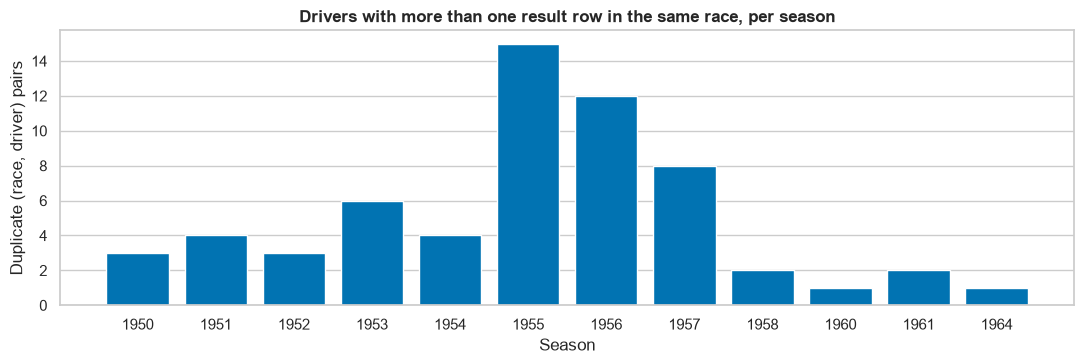

In [34]:
# ── 5. Grain · SEE: every driver with more than one result row in the same race ─
GRAIN = ["raceId", "driverId"]


def with_context(df: pd.DataFrame) -> pd.DataFrame:
    """Add season, race, driver, constructor and status names for display."""
    return (df.merge(clean["races"][["raceId", "year", "name"]], on="raceId")
              .merge(clean["drivers"][["driverId", "surname"]], on="driverId")
              .merge(clean["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"}),
                     on="constructorId")
              .merge(clean["status"], on="statusId"))


def drivers_per_car(base: pd.DataFrame) -> pd.DataFrame:
    """Number of distinct drivers recorded in each car (raceId, car number)."""
    return base.groupby(["raceId", "constructorId", "number"])["driverId"].nunique().rename("drivers_in_car").reset_index()

dups = with_context(clean["results"][clean["results"].duplicated(GRAIN, keep=False)])
dups = dups.merge(drivers_per_car(clean["results"]), on=   ["raceId", "constructorId", "number"], how="left")
assert dups["number"].notna().all(), "a duplicate row has no car number"

COLS = ["year", "name", "surname", "constructor", "resultId", "number", "drivers_in_car", "grid",
        "positionOrder", "laps", "status"]
print(f"Duplicate (raceId, driverId) pairs: {dups.groupby(GRAIN).ngroups}, rows: {len(dups)}, "
      f"races: {dups['raceId'].nunique()}, seasons {dups['year'].min()}–{dups['year'].max()}")
with pd.option_context("display.max_rows", 200, "display.max_colwidth", 26):
    display(dups.sort_values(["year", "raceId", "driverId", "resultId"])[COLS].reset_index(drop=True))

pairs_per_season = dups.drop_duplicates(GRAIN).groupby("year").size()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(pairs_per_season.index.astype(str), pairs_per_season.values, color=sns.color_palette("colorblind")[0])
ax.set_xlabel("Season")
ax.set_ylabel("Duplicate (race, driver) pairs")
ax.set_title("Drivers with more than one result row in the same race, per season")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Finding:** after Section 4b, 61 drivers still have more than one row in a race (125 rows), all in 1950–1964. The 3 pairs where neither row started (Flockhart 1958, Greene 1962, Ertl 1978) disappeared with Section 4b. Typically a driver has one row for the car he started in and one for a teammate's car he took over. `drivers_in_car` shows how many different drivers were recorded in each car.

**Why it matters:** the driver who started a car is always among its recorded drivers. A car with only one recorded driver therefore tells us who started it, without looking at the result.

In [35]:
# ── 5. Grain · SEE: the 4 races where the typing order does not follow the race ─
# For each of these drivers, show every row of both cars he appears in, in the order they were recorded.
ORDER_CASES = [(1951, "French Grand Prix", "Ascari"), (1954, "Belgian Grand Prix", "González"),
               (1956, "French Grand Prix", "da Silva Ramos"), (1961, "British Grand Prix", "Moss")]
all_rows = with_context(clean["results"]).merge(drivers_per_car(clean["results"]), on=   ["raceId", "constructorId", "number"])
for year, race, driver in ORDER_CASES:
    mine = all_rows.query("year == @year and name == @race and surname == @driver")
    cars = all_rows[(all_rows["raceId"] == mine["raceId"].iloc[0]) & all_rows["number"].isin(mine["number"])]
    print(f"\n{year} {race}: {driver} appears in cars {sorted(int(n) for n in mine['number'])}")
    display(cars.sort_values(["number", "resultId"])[["surname", "resultId", "number", "drivers_in_car", "grid",
                                                      "positionOrder", "laps", "status"]])


1951 French Grand Prix: Ascari appears in cars [12, 14]


,surname,resultId,number,drivers_in_car,grid,positionOrder,laps,status
18053,Ascari,19935,12,1,3,18,10,Gearbox
18037,Ascari,19919,14,2,6,2,77,Finished
18269,González,20187,14,2,6,2,77,Finished



1954 Belgian Grand Prix: González appears in cars [6, 10]


,surname,resultId,number,drivers_in_car,grid,positionOrder,laps,status
17509,González,19276,6,1,2,12,1,Engine
17501,González,19268,10,2,5,4,35,+1 Lap
18284,Hawthorn,20238,10,2,5,4,35,+1 Lap



1956 French Grand Prix: da Silva Ramos appears in cars [8, 32]


,surname,resultId,number,drivers_in_car,grid,positionOrder,laps,status
17284,da Silva Ramos,18974,8,1,16,13,40,Engine
17279,da Silva Ramos,18969,32,1,14,8,57,+4 Laps



1961 British Grand Prix: Moss appears in cars [26, 28]


,surname,resultId,number,drivers_in_car,grid,positionOrder,laps,status
16509,Moss,17962,26,2,20,19,56,Disqualified
18340,Fairman,20299,26,2,20,19,56,Disqualified
16511,Moss,17964,28,1,5,21,44,Brakes


**Finding:** in these 4 races the first-recorded row is not the car the driver started in. Ascari's row in González's car #14 (resultId 19919) was recorded before González's own #14 row (20187), while Ascari's own car #12 has only him recorded. The same pattern holds for González 1954 (own car #6) and Moss 1961 (own car #28, takeover of Fairman's #26). da Silva Ramos 1956 is the exception: both of his cars have only him recorded.

**Why it matters:** lowest `resultId` alone would keep the takeover car in 3 of these pairs. The "single recorded driver" test picks the car each driver actually started in.

In [36]:
# ── 5. Grain · SEE: the started-car rule vs plain lowest resultId ─────────────
def started_car_rule(results: pd.DataFrame, count_base: pd.DataFrame) -> pd.DataFrame:
    """One row per duplicate (raceId, driverId), chosen without any outcome column.
    Step 1: if exactly one of the driver's rows is in a car where he is the only recorded driver, keep it.
    Step 2: otherwise keep the lowest resultId (first-recorded entry)."""
    d = results[results.duplicated(GRAIN, keep=False)].merge(drivers_per_car(count_base), on=   ["raceId", "constructorId", "number"],
                                                             how="left")
    d["solo_car"] = d["drivers_in_car"].eq(1)
    n_solo = d.groupby(GRAIN)["solo_car"].transform("sum")
    d["decided_by"] = np.where(n_solo == 1, "step 1: only solo car", "step 2: lowest resultId")
    step1 = d[(n_solo == 1) & d["solo_car"]]
    step2 = d[n_solo != 1].sort_values("resultId").drop_duplicates(GRAIN)
    return pd.concat([step1, step2]).sort_values(GRAIN)


pre_4b_results = pd.concat([clean["results"], non_starters], ignore_index=True)
kept_rule = started_car_rule(clean["results"], clean["results"])
kept_rule_pre = started_car_rule(clean["results"], pre_4b_results)          # count drivers per car before Section 4b
kept_lowest = dups.sort_values("resultId").drop_duplicates(GRAIN)
differ = set(kept_rule["resultId"]) ^ set(kept_lowest["resultId"])

comparison = pd.DataFrame([
    {"rule": "lowest resultId", "rows_removed": len(dups) - len(kept_lowest),
     "podiums_kept": int((kept_lowest["positionOrder"] <= 3).sum())},
    {"rule": "started car, then lowest resultId", "rows_removed": len(dups) - len(kept_rule),
     "podiums_kept": int((kept_rule["positionOrder"] <= 3).sum())},
]).set_index("rule")
comparison["pairs_differing"] = len(differ) // 2
display(comparison)
print("Pairs where the two rules differ (row kept by the started-car rule):")
display(with_context(kept_rule[kept_rule["resultId"].isin(differ)])[["year", "name", "surname", "resultId", "number",
                                                                       "grid", "positionOrder"]])
display(kept_rule["decided_by"].value_counts().rename("pairs"))
step2 = kept_rule[kept_rule["decided_by"].str.startswith("step 2")]
solo_counts = dups.assign(solo=dups["drivers_in_car"].eq(1)).groupby(GRAIN)["solo"].sum()   # solo cars per pair
print(f"Step 2 pairs: {len(step2)} = {int((solo_counts.loc[step2.set_index(GRAIN).index] == 0).sum())} where both cars "
      f"are shared + {int((solo_counts.loc[step2.set_index(GRAIN).index] >= 2).sum())} where both cars have only him.")
dsr = dups.query("surname == 'da Silva Ramos'")[["year", "name", "resultId", "number", "drivers_in_car", "positionOrder"]]
print("da Silva Ramos 1956 (undecidable): podium label is 0 in both rows")
display(dsr.assign(podium=dsr["positionOrder"] <= 3))
print(f"Order check: counting drivers per car before vs after Section 4b changes "
      f"{len(set(kept_rule['resultId']) ^ set(kept_rule_pre['resultId']))} kept rows.")

,rows_removed,podiums_kept,pairs_differing
rule,,,
lowest resultId,64,6,3
"started car, then lowest resultId",64,5,3


Pairs where the two rules differ (row kept by the started-car rule):


,year,name,surname,resultId,number,grid,positionOrder
0,1961,British Grand Prix,Moss,17964,28,5,21
1,1954,Belgian Grand Prix,González,19276,6,2,12
2,1951,French Grand Prix,Ascari,19935,12,3,18


decided_by
step 1: only solo car      43
step 2: lowest resultId    18
Name: pairs, dtype: int64

Step 2 pairs: 18 = 17 where both cars are shared + 1 where both cars have only him.
da Silva Ramos 1956 (undecidable): podium label is 0 in both rows


,year,name,resultId,number,drivers_in_car,positionOrder,podium
19,1956,French Grand Prix,18969,32,1,8,False
20,1956,French Grand Prix,18974,8,1,13,False


Order check: counting drivers per car before vs after Section 4b changes 0 kept rows.


**Finding:** both rules remove 64 rows. They differ in exactly 3 pairs: the started-car rule keeps Ascari #12, González #6 and Moss #28, the cars they started in. That leaves 5 podium rows kept instead of 6, because Ascari's 2nd place was in González's car. Step 1 decides 43 pairs. Step 2 decides 18: 17 car swaps where both cars are shared, plus da Silva Ramos 1956, whose two rows (8th and 13th) both have podium = 0. Counting drivers per car before or after Section 4b keeps exactly the same rows.

**Why it matters:** the rule picks the car the driver started in where the data can tell, and its one undecidable pair cannot change a label.

### Decision: keep the car each driver started in

1. If exactly one of the driver's rows is in a car where he is the only recorded driver, keep that row: that car must have been started by him.
2. Otherwise keep the lowest `resultId` (the first-recorded entry).

The race structure (one starter per car) comes first, and typing order is only the fallback. Neither step reads `positionOrder`, `position`, `laps`, `status` or `points`, so the choice of rows does not depend on the result: no selection leakage. Choosing the best finish instead would have kept 21 podium rows instead of 5.

**Flag:** `is_shared_drive` marks every kept row that took part in a shared drive (the driver had more than one row, or his car has more than one recorded driver). It is derived from what happened during the race, so it is used only to document the data and select rows, **never as a feature**.

**Car identity:** a car is `raceId + constructorId + number`, not `raceId + number`. In 3 early races (1951 French, 1953 German and 1953 Italian GP) two different teams used the same number, which would count two cars as one. This keeps exactly the same rows; it only stops 5 rows from being wrongly flagged as shared drives (143 → 138).

**Limitation:** 1 pair (da Silva Ramos 1956) cannot be decided, but its label is 0 either way. All affected pairs are from 1950–1964, outside any likely training window.

In [37]:
# ── 5. Grain · ACT: keep the started car, flag shared drives, log the removed rows ─
rows_before_5 = len(clean["results"])
cars = drivers_per_car(clean["results"])                     # counted before removing anything
dup_rows = clean["results"][clean["results"].duplicated(GRAIN, keep=False)]
kept_ids = set(started_car_rule(clean["results"], clean["results"])["resultId"])
removed_dup_ids = sorted(int(i) for i in set(dup_rows["resultId"]) - kept_ids)

clean["results"] = clean["results"][~clean["results"]["resultId"].isin(removed_dup_ids)].reset_index(drop=True)
in_dup_pair = clean["results"]["resultId"].isin(kept_ids)
in_shared_car = clean["results"].merge(cars, on=   ["raceId", "constructorId", "number"], how="left")["drivers_in_car"].gt(1).to_numpy()
clean["results"]["is_shared_drive"] = in_dup_pair | in_shared_car

log_step("results", "Section 5: one row per (raceId, driverId), started car kept", len(removed_dup_ids), "rows",
         f"shared drives: removed resultIds {removed_dup_ids}")
log_step("results", "Section 5: is_shared_drive flag added", int(clean["results"]["is_shared_drive"].sum()), "rows",
         "documents shared drives; derived from in-race events, never a feature")
print(f"Removed {len(removed_dup_ids)} rows; results {rows_before_5:,} -> {len(clean['results']):,}. "
      f"is_shared_drive = True on {int(clean['results']['is_shared_drive'].sum())} rows.")

Removed 64 rows; results 24,794 -> 24,730. is_shared_drive = True on 138 rows.


**Done:** 64 duplicate rows removed (24,794 → 24,730), with their resultIds logged in `CLEANING_LOG`. `is_shared_drive` marks the kept rows that took part in a shared drive.

**Why it matters:** `results` now has the grain the brief requires, chosen without looking at the outcome.

In [38]:
# ── 5. Grain · VERIFY: one row per driver per race, exact counts, flag coverage ─
cr = clean["results"]
assert not cr.duplicated(GRAIN).any(), "(raceId, driverId) is still not unique"
assert len(removed_dup_ids) == rows_before_5 - len(cr) == 64, "expected 64 rows removed"
kept_pair_rows = cr[cr["resultId"].isin(kept_ids)]
assert int((kept_pair_rows["positionOrder"] <= 3).sum()) == 5, "expected 5 podium rows among the kept pair rows"
print(f"(raceId, driverId) unique in all {len(cr):,} rows; {len(removed_dup_ids)} rows removed "
      f"({rows_before_5:,} -> {len(cr):,}); podium rows among the {len(kept_pair_rows)} kept pair rows: "
      f"{int((kept_pair_rows['positionOrder'] <= 3).sum())}.")

# Races that still have more than 3 podium rows: co-drivers of one car, credited with the same finish.
podium_rows = with_context(cr[cr["positionOrder"] <= 3])
crowded = podium_rows.groupby("raceId").filter(lambda g: len(g) > 3)
display(crowded[["year", "name", "surname", "resultId", "number", "positionOrder", "is_shared_drive"]])
assert crowded["raceId"].nunique() == 1, "expected exactly 1 race with more than 3 podium rows"
ties = crowded[crowded.duplicated(["raceId", "positionOrder"], keep=False)]
assert ties["is_shared_drive"].all(), "a co-driver tie is not flagged"
print(f"{crowded['raceId'].nunique()} race keeps more than 3 podium rows: a tie at P{int(ties['positionOrder'].iloc[0])} "
      f"between co-drivers of car #{int(ties['number'].iloc[0])}; all {len(ties)} tied rows have is_shared_drive = True.")

(raceId, driverId) unique in all 24,730 rows; 64 rows removed (24,794 -> 24,730); podium rows among the 61 kept pair rows: 5.


,year,name,surname,resultId,number,positionOrder,is_shared_drive
2298,1955,Argentine Grand Prix,Fangio,19057,2,1,False
2299,1955,Argentine Grand Prix,González,19058,12,2,True
2300,1955,Argentine Grand Prix,Farina,19059,10,3,True
2424,1955,Argentine Grand Prix,Maglioli,20247,10,3,True


1 race keeps more than 3 podium rows: a tie at P3 between co-drivers of car #10; all 2 tied rows have is_shared_drive = True.


**Verified:** `(raceId, driverId)` is unique in all 24,730 rows. Exactly 64 rows were removed, and 5 podium rows remain among the 61 kept pair rows. One race still has more than 3 podium rows: the 1955 Argentine GP, where Farina and Maglioli are both credited with 3rd in car #10. Maglioli's only row is his takeover, so he was never a duplicate. Both rows are flagged `is_shared_drive`.

**Why it matters:** the grain requirement is met. The one remaining co-driver tie is real history (both drivers were credited) and is flagged, so the modeling step can decide how to treat it.

## 6. Name consistency and status values

Question 2 (home advantage) joins driver nationality to circuit country, so each country and nationality must have one spelling. Question 3 (mechanical retirements) needs the full list of status values.

In [39]:
# ── 6. Name consistency · SEE: country and nationality spellings ──────────────
def spelling_report(table: str, column: str) -> pd.DataFrame:
    """Distinct values that look like variants of each other: extra spaces, or the same first 6 letters
    spelled differently (e.g. 'USA' / 'United States' is checked separately, as it shares no prefix)."""
    s = clean[table][column].dropna()
    counts = s.value_counts().rename("rows").rename_axis("value").reset_index()
    counts["has_extra_spaces"] = counts["value"] != counts["value"].str.strip()
    counts["stem"] = counts["value"].str.strip().str.lower().str[:6]
    variants = counts[counts.groupby("stem")["value"].transform("nunique") > 1]
    return counts[counts["has_extra_spaces"]].pipe(lambda x: pd.concat([x, variants])).drop_duplicates("value")


print("circuits.country, all values:")
display(clean["circuits"]["country"].value_counts().sort_index().to_frame("circuits").T)
us = clean["circuits"][clean["circuits"]["country"].isin(["USA", "United States"])]
us_races = clean["races"].merge(us[["circuitId", "name", "country"]].rename(columns={"name": "circuit"}), on="circuitId")
print("Circuits spelled 'USA' vs 'United States', with the races held there:")
display(us_races.groupby(["country", "circuit"])["year"].agg(["min", "max", "count"]).rename(columns={"count": "races"}))

for table, column in [("circuits", "country"), ("circuits", "location"), ("drivers", "nationality"),
                      ("constructors", "nationality")]:
    rep = spelling_report(table, column)
    print(f"{table}.{column}: {clean[table][column].nunique()} distinct values; possible variants: "
          f"{'none' if rep.empty else ''}")
    if not rep.empty:
        display(rep[["value", "rows", "has_extra_spaces"]])

circuits.country, all values:


country,Argentina,Australia,Austria,Azerbaijan,Bahrain,Belgium,Brazil,Canada,China,France,Germany,Hungary,India,Italy,Japan,Korea,Malaysia,Mexico,Monaco,Morocco,Netherlands,Portugal,Qatar,Russia,Saudi Arabia,Singapore,South Africa,Spain,Sweden,Switzerland,Turkey,UAE,UK,USA,United States
circuits,1,2,2,1,1,3,2,3,1,7,3,1,1,4,3,1,1,1,1,1,1,4,1,1,1,1,2,6,1,1,1,1,4,11,1


Circuits spelled 'USA' vs 'United States', with the races held there:


min   max  races
country       circuit                                           
USA           Circuit of the Americas          2012  2024     12
              Detroit Street Circuit           1982  1988      7
              Fair Park                        1984  1984      1
              Indianapolis Motor Speedway      2000  2007      8
              Las Vegas Street Circuit         1981  1982      2
              Long Beach                       1976  1983      8
              Miami International Autodrome    2022  2024      3
              Phoenix street circuit           1989  1991      3
              Riverside International Raceway  1960  1960      1
              Sebring International Raceway    1959  1959      1
              Watkins Glen                     1961  1980     20
United States Las Vegas Strip Street Circuit   2023  2024      2

circuits.country: 35 distinct values; possible variants: none
circuits.location: 75 distinct values; possible variants: none
drivers.nationality: 43 distinct values; possible variants: 


,value,rows,has_extra_spaces
42,Argentinian,1,True
1,American,158,False
6,Argentine,24,False
38,American-Italian,1,False
39,Argentine-Italian,1,False


constructors.nationality: 24 distinct values; possible variants: none


**Finding:** circuit countries have one inconsistency. 11 US circuits are `USA`, but the Las Vegas Strip circuit (2023–2024) is `United States`. Driver nationality has `Argentinian ` (1 driver, with a trailing space) next to `Argentine` (24 drivers). `American-Italian` and `Argentine-Italian` are genuine dual nationalities, not typos. Locations and constructor nationalities have no variants.

**Why it matters:** without one spelling per country, Question 2 would treat Las Vegas 2023–2024 as a different country from every other US race, and split Argentine drivers into two groups.

### Decision: one spelling per country and nationality

- `circuits.country`: `United States` → `USA` (the spelling used by the other 11 US circuits). `UK`, `UAE` and `Korea` already have a single spelling each, so they stay.
- `drivers.nationality`: strip spaces and map `Argentinian` → `Argentine` (the majority spelling). Dual nationalities stay as they are.
- **Later, for Question 2:** nationality is an adjective (`British`) and country a noun (`UK`), so a nationality → country table is still needed. Dual nationalities must be handled there too.

In [40]:
# ── 6. Name consistency · ACT: one spelling per country and nationality ─────────
NAME_FIXES = {("circuits", "country"): {"United States": "USA"},
              ("drivers", "nationality"): {"Argentinian": "Argentine"}}
name_changes = []
for (table, column), mapping in NAME_FIXES.items():
    before = clean[table][column].copy()
    clean[table][column] = before.str.strip().replace(mapping)
    changed = before.ne(clean[table][column]) & before.notna()
    name_changes += [{"table": table, "column": column, "before": repr(b), "after": a, "rows": n}
                     for (b, a), n in pd.DataFrame({"b": before[changed], "a": clean[table][column][changed]})
                     .value_counts().items()]
    if changed.any():
        log_step(table, f"Section 6: {column} spelling unified", int(changed.sum()), "values",
                 "one spelling per country/nationality for the home-race question")
display(pd.DataFrame(name_changes))

,table,column,before,after,rows
0,circuits,country,'United States',USA,1
1,drivers,nationality,'Argentinian ',Argentine,1


**Done:** the Las Vegas Strip circuit's country is now `USA`, and the one `Argentinian ` driver is now `Argentine`. Both changes are logged.

**Why it matters:** each country and nationality now has exactly one spelling for the Question 2 join.

In [41]:
# ── 6. Name consistency · VERIFY: no variant spellings left ─────────────────────
assert not clean["circuits"]["country"].eq("United States").any()
assert not clean["drivers"]["nationality"].isin(["Argentinian", "Argentinian "]).any()
for table, column in [("circuits", "country"), ("drivers", "nationality")]:
    s = clean[table][column].dropna()
    assert (s == s.str.strip()).all(), f"{table}.{column} still has extra spaces"
    assert spelling_report(table, column)["has_extra_spaces"].sum() == 0
print(f"circuits.country: {clean['circuits']['country'].nunique()} countries (was 35); USA now covers "
      f"{int(clean['circuits']['country'].eq('USA').sum())} circuits. drivers.nationality: "
      f"{clean['drivers']['nationality'].nunique()} values (was 43); Argentine now covers "
      f"{int(clean['drivers']['nationality'].eq('Argentine').sum())} drivers.")

circuits.country: 34 countries (was 35); USA now covers 12 circuits. drivers.nationality: 42 values (was 43); Argentine now covers 25 drivers.


**Verified:** no `United States` or `Argentinian` values and no extra spaces remain. Circuit countries go from 35 to 34 (USA now covers 12 circuits), and driver nationalities from 43 to 42 (Argentine now covers 25 drivers).

**Why it matters:** the home-race join in Question 2 will not split one country into two.

132 status values are used (31 mean the driver reached the flag: 'Finished' or '+n Lap(s)'); 7 status codes are unused.


source,statusId,status,results,sprint_results,total
0,1,Finished,7538,340,7878
1,11,+1 Lap,4020,0,4020
2,5,Engine,1986,0,1986
3,12,+2 Laps,1603,0,1603
4,3,Accident,997,3,1000
5,4,Collision,854,0,854
6,6,Gearbox,809,0,809
7,20,Spun off,780,0,780
8,13,+3 Laps,720,0,720
9,22,Suspension,426,0,426


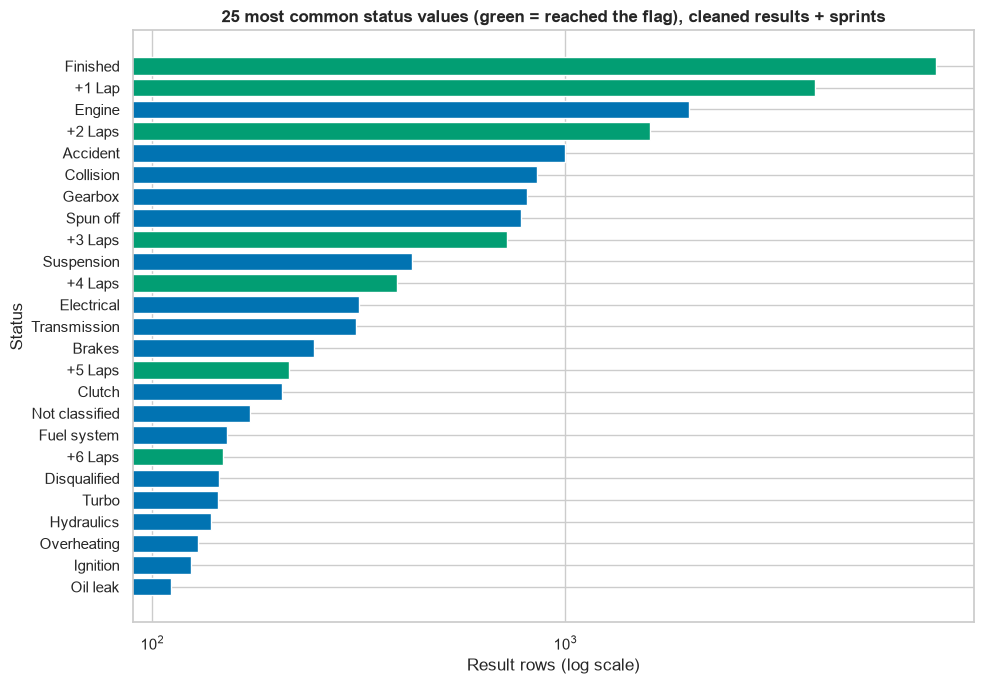

In [42]:
# ── 6. Status values · SEE: every reason a race ended, with counts (input for Question 3) ─
status_counts = (pd.concat([clean["results"][["statusId"]].assign(source="results"),
                            clean["sprint_results"][["statusId"]].assign(source="sprint_results")])
                 .merge(clean["status"], on="statusId")
                 .pivot_table(index=["statusId", "status"], columns="source", aggfunc="size", fill_value=0)
                 .reset_index())
status_counts["total"] = status_counts[["results", "sprint_results"]].sum(axis=1)
status_counts = status_counts.sort_values("total", ascending=False, ignore_index=True)
is_finish = status_counts["status"].str.fullmatch(r"Finished|\+\d+ Laps?")
print(f"{len(status_counts)} status values are used ({int(is_finish.sum())} mean the driver reached the flag: "
      f"'Finished' or '+n Lap(s)'); {len(clean['status']) - len(status_counts)} status codes are unused.")
with pd.option_context("display.max_rows", 200):
    display(status_counts)

top = status_counts.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top["status"], top["total"], color=[sns.color_palette("colorblind")[2] if f else sns.color_palette("colorblind")[0]
                                            for f in is_finish.head(25).iloc[::-1]])
ax.set_xscale("log")
ax.set_xlabel("Result rows (log scale)")
ax.set_ylabel("Status")
ax.set_title("25 most common status values (green = reached the flag), cleaned results + sprints")
plt.tight_layout()
plt.show()

**Finding:** the cleaned results and sprints use 132 status values. 31 of them mean the driver reached the flag ("Finished", "+1 Lap", "+2 Laps", …); the other 101 are reasons for stopping, from mechanical (Engine 1,986 rows, Gearbox 809, Suspension 426, …) to accidents (Accident 1,000, Collision 854, Spun off 780) and decisions (Disqualified, Not classified). 7 status codes are no longer used, including the 3 DNQ / DNPQ / 107% codes whose rows were removed in 4b.

**Why it matters:** Question 3 needs a documented mapping of these values into mechanical vs non-mechanical retirements. It is built when answering that question, not here. `status` is post-race information and is never a model feature.

## 6b. Standings rewritten after the fact

Some standings rows hold a letter instead of a number in `positionText`. We find every such row, compare it with the points stored in the same row, and flag it. Values are not changed here; feature engineering recomputes positions from points.

In [43]:
# ── 6b. Retroactive exclusions · SEE: standings positions that are letters, and what the points say ─
cs = (clean["constructor_standings"]
      .merge(clean["races"][["raceId", "year", "round"]], on="raceId")
      .merge(clean["constructors"][["constructorId", "name"]], on="constructorId"))
cs["rank_by_points"] = cs.groupby("raceId")["points"].rank(method="min", ascending=False).astype(int)
ds = (clean["driver_standings"]
      .merge(clean["races"][["raceId", "year", "round"]], on="raceId")
      .merge(clean["drivers"][["driverId", "surname"]], on="driverId"))
ds["rank_by_points"] = ds.groupby("raceId")["points"].rank(method="min", ascending=False).astype(int)

cs_odd = cs[~cs["positionText"].str.fullmatch(r"\d+")]
ds_odd = ds[~ds["positionText"].str.fullmatch(r"\d+")]
print(f"constructor_standings rows with a letter position: {len(cs_odd)}")
display(cs_odd.sort_values("round")[["year", "round", "name", "points", "position", "positionText", "rank_by_points"]])
print(f"driver_standings rows with a letter position: {len(ds_odd)}")
display(ds_odd[["year", "round", "surname", "points", "position", "positionText", "rank_by_points"]])

# A related case in results: a constructor-season where almost every row is "Disqualified".
res = (clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId")
       .merge(clean["status"], on="statusId"))
season = (res.groupby(["year", "constructorId"])
             .agg(rows=("status", "size"), disqualified=("status", lambda s: int(s.eq("Disqualified").sum())),
                  points=("points", "sum"))
             .reset_index()
             .merge(clean["constructors"][["constructorId", "name"]], on="constructorId"))
print("Constructor-seasons with 5 or more disqualified rows:")
display(season[season["disqualified"] >= 5])

constructor_standings rows with a letter position: 17


,year,round,name,points,position,positionText,rank_by_points
3685,2007,1,McLaren,14.0,11,E,1
3686,2007,2,McLaren,32.0,11,E,1
217,2007,3,McLaren,44.0,11,E,1
227,2007,4,McLaren,58.0,11,E,1
236,2007,5,McLaren,76.0,11,E,1
245,2007,6,McLaren,88.0,11,E,1
254,2007,7,McLaren,106.0,11,E,1
263,2007,8,McLaren,114.0,11,E,1
272,2007,9,McLaren,128.0,11,E,1
281,2007,10,McLaren,138.0,11,E,1


driver_standings rows with a letter position: 1


,year,round,surname,points,position,positionText,rank_by_points
4375,1997,17,Schumacher,78.0,26,D,2


Constructor-seasons with 5 or more disqualified rows:


,year,constructorId,rows,disqualified,points,name
478,1984,25,22,21,0.0,Tyrrell


### Decision: flag these rows, change nothing, recompute positions later

**Finding:** 17 `constructor_standings` rows (McLaren, every round of 2007) have `positionText` "E" and position 11, yet their points rise normally from 14 to 218, which ranks them near the top on points. 1 `driver_standings` row (final round of 1997) has "D". In `results`, Tyrrell 1984 has almost every row "Disqualified" with 0 points.

- **Why not use the stored position:** the letter is applied to every round of the season, including rounds held before the decision could have been made. A "constructor position before this race" feature would show a race-winning team as last, which is leakage and also wrong as a strength signal.
- **What we do here:** add `standings_excluded` to both standings tables. Values are kept as recorded, so the clean data stays faithful to the source.
- **Later, in feature engineering:** positions are recomputed by ranking points within each round, which fixes McLaren 2007 automatically. The 1997 row only affects a season's final round, which no "before this race" feature uses. Tyrrell 1984 cannot be repaired (points were set to 0); it falls outside a 2003+ training window and is noted as a limitation.

In [44]:
# ── 6b. Retroactive exclusions · ACT + VERIFY: flag the rows, change no values ─
for t, expected in [("constructor_standings", 17), ("driver_standings", 1)]:
    before = clean[t].drop(columns="standings_excluded", errors="ignore").copy()
    flag = (~clean[t]["positionText"].str.fullmatch(r"\d+")).astype(bool)
    clean[t]["standings_excluded"] = flag
    log_step(t, "Section 6b: standings_excluded flag added", int(flag.sum()), "rows",
             "positionText is a letter (E/D) while points are kept; documented, never a feature")
    assert int(flag.sum()) == expected, f"{t}: expected {expected} flagged rows, got {int(flag.sum())}"
    pd.testing.assert_frame_equal(clean[t].drop(columns="standings_excluded"), before)   # no value changed
print("Flagged 17 constructor_standings rows and 1 driver_standings row; no values changed.")

Flagged 17 constructor_standings rows and 1 driver_standings row; no values changed.


In [45]:
# ── 6c. Constructor IDs · SEE + VERIFY: does qualifying name the same team as results? ─
m = (clean["results"][["raceId", "driverId", "constructorId"]]
     .merge(clean["qualifying"][["raceId", "driverId", "constructorId"]],
            on=["raceId", "driverId"], suffixes=("_results", "_qualifying")))
team = clean["constructors"].set_index("constructorId")["name"]
diff = (m[m["constructorId_results"] != m["constructorId_qualifying"]]
        .merge(clean["races"][["raceId", "year", "name"]], on="raceId")
        .assign(team_in_results=lambda d: d["constructorId_results"].map(team),
                team_in_qualifying=lambda d: d["constructorId_qualifying"].map(team)))
print(f"Driver-races in both tables: {len(m):,}; constructor differs in {len(diff)}.")
display(diff[["year", "name", "driverId", "constructorId_results", "team_in_results",
              "constructorId_qualifying", "team_in_qualifying"]])

# results uses one constructorId per driver per season for this team; qualifying switches mid-season
season_ids = (clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId")
              .query("year == 2015 and constructorId in [206, 209]")["constructorId"].unique())
print(f"constructorIds used in results for this team in 2015: {sorted(int(i) for i in season_ids)}")
assert len(diff) == 10 and diff["year"].eq(2015).all(), "unexpected constructor mismatches"

Driver-races in both tables: 10,488; constructor differs in 10.


,year,name,driverId,constructorId_results,team_in_results,constructorId_qualifying,team_in_qualifying
0,2015,Belgian Grand Prix,833,209,Manor Marussia,206,Marussia
1,2015,Belgian Grand Prix,829,209,Manor Marussia,206,Marussia
2,2015,Russian Grand Prix,833,209,Manor Marussia,206,Marussia
3,2015,Russian Grand Prix,829,209,Manor Marussia,206,Marussia
4,2015,United States Grand Prix,834,209,Manor Marussia,206,Marussia
5,2015,United States Grand Prix,829,209,Manor Marussia,206,Marussia
6,2015,Mexican Grand Prix,834,209,Manor Marussia,206,Marussia
7,2015,Mexican Grand Prix,829,209,Manor Marussia,206,Marussia
8,2015,Brazilian Grand Prix,829,209,Manor Marussia,206,Marussia
9,2015,Brazilian Grand Prix,834,209,Manor Marussia,206,Marussia


constructorIds used in results for this team in 2015: [209]


**Finding:** 10 driver-races (all in 2015) name a different constructor in `qualifying` (206, "Marussia") than in `results` (209, "Manor Marussia"). `results` uses 209 for the whole 2015 season; `qualifying` switches between the two IDs within the season.

**Decision:** no values are changed. Whenever a feature needs the constructor, it is taken from `results`, which is consistent within the season; `qualifying.constructorId` is not used. This keeps one team from being split into two IDs halfway through 2015.

## 7. After cleaning: the "after" snapshot

The same diagnostics as Section 1, now on `clean`, shown next to the "before" numbers so the effect of every cleaning step is visible.

,rows_before,rows_after,rows_removed,placeholders_before,NA_after,dtypes_before,dtypes_after
circuits,77,77,0,0,0,str,"str×5, Int64×2, float64×2"
constructors,212,212,0,0,0,str,"str×4, Int64×1"
constructor_results,12625,12604,21,12608,12587,str,"Int64×3, float64×1, str×1"
constructor_standings,13391,13365,26,0,0,str,"Int64×5, float64×1, str×1, bool×1"
drivers,861,861,0,1559,1559,str,"str×6, Int64×2, datetime64[us]×1"
driver_standings,34863,34194,669,0,0,str,"Int64×5, float64×1, str×1, bool×1"
races,1125,1114,11,11349,11228,str,"datetime64[us]×6, timedelta64[us]×6, Int64×4, str×2"
results,26759,24730,2029,122887,109223,str,"Int64×13, float64×3, str×2, boolean×2"
qualifying,10494,10494,0,11668,11668,str,"Int64×6, float64×3"
lap_times,589081,589081,0,0,0,str,"Int64×5, float64×1"


results rows sharing a (raceId, driverId): before 176, after 0.


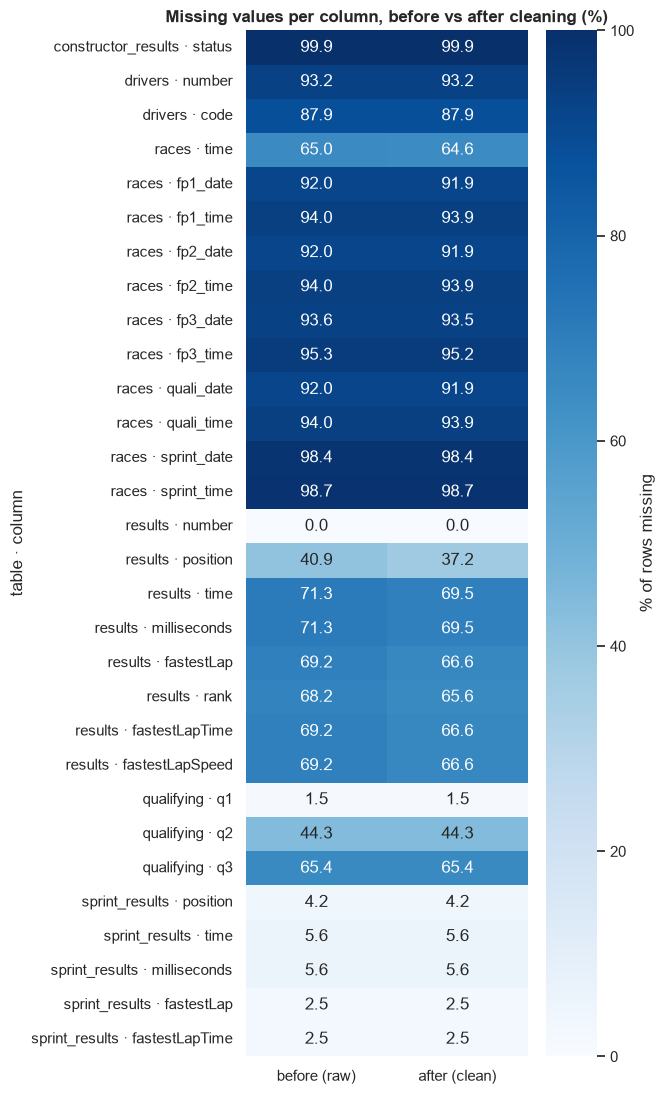

In [46]:
# ── 7. After cleaning · tables side by side: rows, missing values, types, duplicates ─
AFTER = {"missing": missing_report(clean)}
miss_before = BEFORE["missing"].groupby("table")["missing"].sum()
miss_after = AFTER["missing"].groupby("table")["missing"].sum()
summary = pd.DataFrame({
    "rows_before": {t: len(raw[t]) for t in TABLES},
    "rows_after": {t: len(clean[t]) for t in TABLES},
    "placeholders_before": miss_before,
    "NA_after": miss_after,
    "dtypes_before": dtype_summary["before"],
    "dtypes_after": {t: ", ".join(f"{d}×{n}" for d, n in clean[t].dtypes.astype(str).value_counts().items())
                     for t in TABLES},
}).loc[TABLES]
summary["rows_removed"] = summary["rows_before"] - summary["rows_after"]
display(summary[["rows_before", "rows_after", "rows_removed", "placeholders_before", "NA_after",
                 "dtypes_before", "dtypes_after"]])
dup_before = int(raw["results"].duplicated(["raceId", "driverId"], keep=False).sum())
dup_after = int(clean["results"].duplicated(["raceId", "driverId"], keep=False).sum())
print(f"results rows sharing a (raceId, driverId): before {dup_before}, after {dup_after}.")

# Missingness heatmap: % missing per affected column, before vs after (rows removed change the shares).
m = (BEFORE["missing"].query("missing > 0")[["table", "column", "pct_missing"]]
     .merge(AFTER["missing"][["table", "column", "pct_missing"]], on=["table", "column"], suffixes=("_before", "_after")))
heat = m.assign(label=m["table"] + " · " + m["column"]).set_index("label")[["pct_missing_before", "pct_missing_after"]]
heat.columns = ["before (raw)", "after (clean)"]
fig, ax = plt.subplots(figsize=(6.5, 0.32 * len(heat) + 1.5))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100, cbar_kws={"label": "% of rows missing"}, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("table · column")
ax.set_title("Missing values per column, before vs after cleaning (%)")
plt.tight_layout()
plt.show()

**Finding:** rows were removed only where a cleaning step decided it: `results` 26,759 → 24,730 (2,029 rows: 405 Indy 500, 1,560 never on the grid, 64 shared-drive duplicates), plus the Indy rows in `races` and the standings and constructor tables. Rows sharing a `(raceId, driverId)` went from 176 to 0. Every placeholder became NA, and every table now has real types. Missing shares barely move, except in `results`: `position` falls from 40.9% to 37.2% and the time and fastest-lap columns by about 2–3 points, because the removed non-starters had none of these values.

**Why it matters:** the after snapshot shows the cleaning changed what it was meant to change and nothing else. The remaining missing values are structural (not classified, knocked out in qualifying, not recorded in that era).

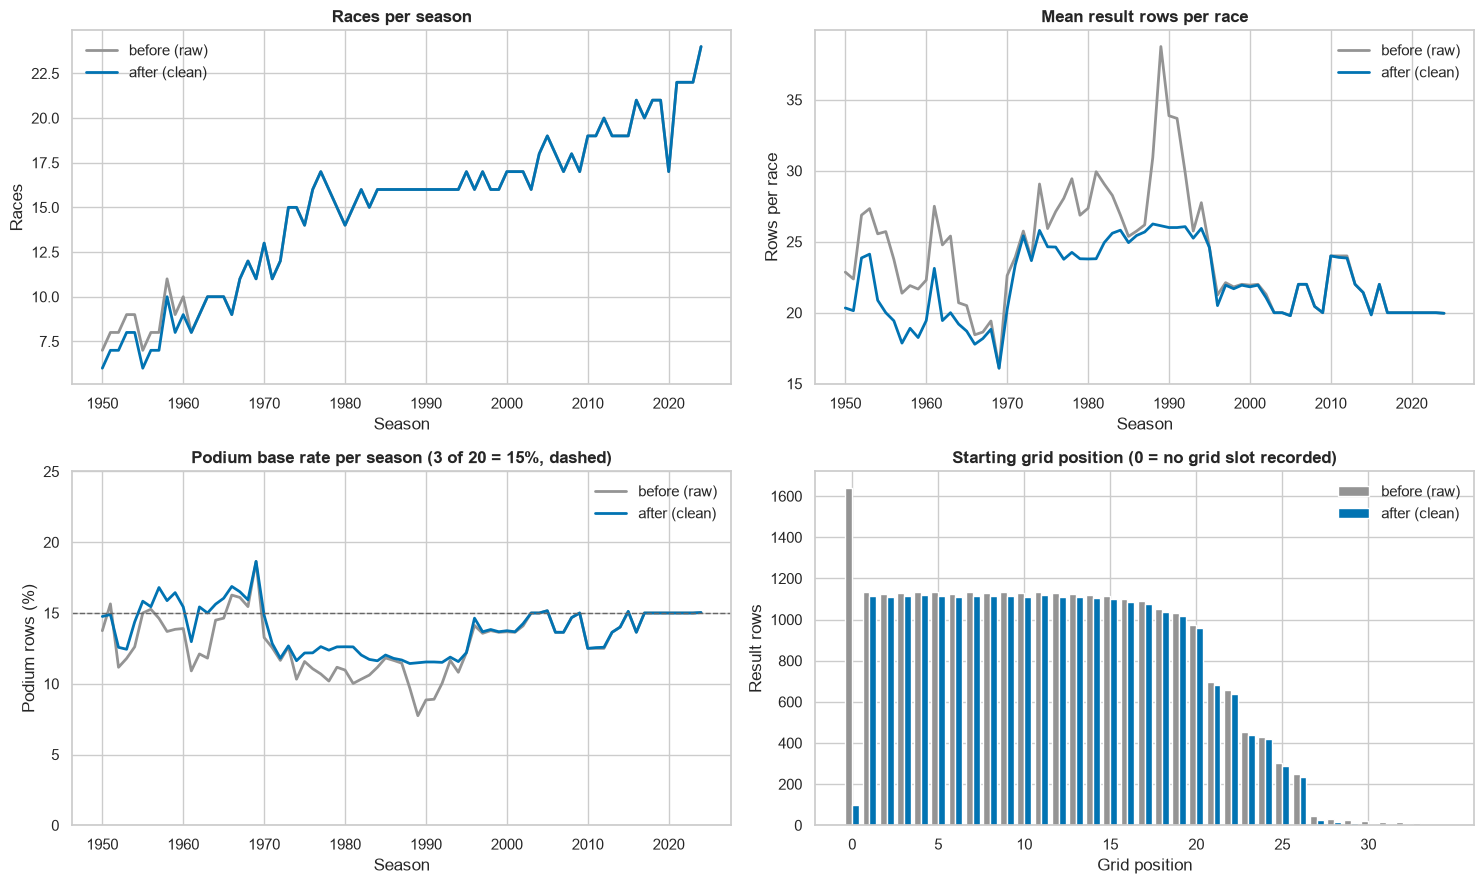

grid = 0: 1,638 rows before, 97 after = 72 pit-lane starters + 11 qualified but did not start + 14 did not start, no qualifying row (kept, podium = 0).


,before,after
"podium rate, all seasons (%)",12.7,13.5
"podium rate, 1950–1979 (%)",12.7,13.9
"podium rate, 1980–1995 (%)",10.3,11.8
"podium rate, 1996–2013 (%)",13.8,13.9
"podium rate, 2014–2024 (%)",14.8,14.8


In [47]:
# ── 7. After cleaning · distributions before vs after ───────────────────────────
res_clean = clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId")
AFTER["races_per_season"] = clean["races"]["year"].value_counts().sort_index()
per_race_after = res_clean.groupby("raceId").agg(year=("year", "first"), entrants=("raceId", "size"))
AFTER["entrants_per_season"] = per_race_after.groupby("year")["entrants"].mean()
AFTER["podium_rate"] = res_clean.groupby("year")["positionOrder"].apply(lambda s: 100 * (s <= 3).mean())
AFTER["grid_counts"] = res_clean["grid"].value_counts().sort_index()

palette = sns.color_palette("colorblind")
before_style = dict(color=palette[7], linewidth=2, label="before (raw)")
after_style = dict(color=palette[0], linewidth=2, label="after (clean)")
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

ax = axes[0, 0]
ax.plot(BEFORE["races_per_season"].index, BEFORE["races_per_season"].values, **before_style)
ax.plot(AFTER["races_per_season"].index, AFTER["races_per_season"].values, **after_style)
ax.set(title="Races per season", xlabel="Season", ylabel="Races")

ax = axes[0, 1]
ax.plot(BEFORE["entrants_per_season"].index, BEFORE["entrants_per_season"]["mean_entrants"], **before_style)
ax.plot(AFTER["entrants_per_season"].index, AFTER["entrants_per_season"].values, **after_style)
ax.set(title="Mean result rows per race", xlabel="Season", ylabel="Rows per race")

ax = axes[1, 0]
ax.plot(BEFORE["entrants_per_season"].index, BEFORE["entrants_per_season"]["podium_rate_%"], **before_style)
ax.plot(AFTER["podium_rate"].index, AFTER["podium_rate"].values, **after_style)
ax.axhline(15, color="0.4", linestyle="--", linewidth=1)
ax.set(title="Podium base rate per season (3 of 20 = 15%, dashed)", xlabel="Season", ylabel="Podium rows (%)",
       ylim=(0, 25))

ax = axes[1, 1]
grid_both = pd.DataFrame({"before (raw)": BEFORE["grid_counts"], "after (clean)": AFTER["grid_counts"]}).fillna(0)
x = np.arange(len(grid_both))
ax.bar(x - 0.2, grid_both["before (raw)"], width=0.4, color=palette[7], label="before (raw)")
ax.bar(x + 0.2, grid_both["after (clean)"], width=0.4, color=palette[0], label="after (clean)")
ax.set_xticks(x[::5], grid_both.index[::5])
ax.set(title="Starting grid position (0 = no grid slot recorded)", xlabel="Grid position", ylabel="Result rows")
for a in axes.flat:
    a.legend(frameon=False)
plt.tight_layout()
plt.show()

g0 = res_clean[res_clean["grid"] == 0]
g0_has_q = pd.MultiIndex.from_frame(g0[["raceId", "driverId"]]).isin(q_keys)
print(f"grid = 0: {int(BEFORE['grid_counts'].get(0, 0)):,} rows before, {len(g0)} after = "
      f"{int((g0['laps'] > 0).sum())} pit-lane starters + "
      f"{int(((g0['laps'] == 0) & g0_has_q).sum())} qualified but did not start + "
      f"{int(((g0['laps'] == 0) & ~g0_has_q).sum())} did not start, no qualifying row (kept, podium = 0).")
raw_rows = pd.DataFrame({
    "year": raw["results"]["raceId"].map(raw["races"].set_index("raceId")["year"]).astype(int),
    "podium": raw["results"]["positionOrder"].astype(int) <= 3})
clean_rows = pd.DataFrame({"year": res_clean["year"], "podium": res_clean["positionOrder"] <= 3})
periods = {"all seasons": (1950, 2024), "1950–1979": (1950, 1979), "1980–1995": (1980, 1995),
           "1996–2013": (1996, 2013), "2014–2024": (2014, 2024)}
rates = pd.DataFrame({
    name: [round(100 * df.loc[df["year"].between(a, b), "podium"].mean(), 1) for a, b in periods.values()]
    for name, df in [("before", raw_rows), ("after", clean_rows)]}, index=[f"podium rate, {p} (%)" for p in periods])
display(rates)

**Finding:** races per season change only in 1950–1960 (one Indy 500 fewer). Rows per race lose their big-field peaks, such as 39 in 1989, which were non-qualifiers. After cleaning, fields are 20–26 from the 1980s on. The podium rate becomes more even across eras: 12.7% → 13.5% overall and 10.3% → 11.8% in 1980–1995, while 2014–2024 stays at 14.8%. `grid = 0` falls from 1,638 to 97 rows: 72 pit-lane starters, 11 drivers who qualified but did not start, and 14 who did not start and have no qualifying row (13 disqualified, excluded or underweight, 1 retired; 1981–1997).

**Why it matters:** the remaining `grid = 0` rows are real race candidates, not missing grid slots. The 14 without a qualifying row are kept on purpose: the data cannot show whether their exclusion came before the cutoff, so removing them would be a guess. Their label is 0 either way, and they fall outside any likely training window. For features, `grid = 0` must not be read as "better than pole" (open question for feature engineering).

In [48]:
# ── 7. After cleaning · the cleaning log: every change, in order ────────────────
cleaning_log = pd.DataFrame(CLEANING_LOG)
cleaning_log["removes_rows"] = cleaning_log["step"].str.contains("removed|one row per", regex=True)
with pd.option_context("display.max_rows", 100, "display.max_colwidth", 70):
    display(cleaning_log)

# Cross-check: rows removed according to the log = rows removed according to the before/after table.
removed_by_log = cleaning_log[cleaning_log["removes_rows"]].groupby("table")["affected"].sum()
check = pd.DataFrame({"removed_per_log": removed_by_log, "removed_per_counts": summary["rows_removed"]}).fillna(0).astype(int)
check = check[(check != 0).any(axis=1)]
display(check)
assert (check["removed_per_log"] == check["removed_per_counts"]).all(), "the log does not explain every removed row"
print(f"{len(cleaning_log)} logged changes. Every removed row is explained by a logged step "
      f"({int(check['removed_per_log'].sum()):,} rows across {len(check)} tables).")

,table,step,affected,unit,reason,removes_rows
0,constructor_results,Section 2: sentinels to NA,12608,cells,'\N' and '' are text placeholders for missing values,False
1,drivers,Section 2: sentinels to NA,1559,cells,'\N' and '' are text placeholders for missing values,False
2,races,Section 2: sentinels to NA,11349,cells,'\N' and '' are text placeholders for missing values,False
3,results,Section 2: sentinels to NA,122887,cells,'\N' and '' are text placeholders for missing values,False
4,qualifying,Section 2: sentinels to NA,11668,cells,'\N' and '' are text placeholders for missing values,False
5,sprint_results,Section 2: sentinels to NA,73,cells,'\N' and '' are text placeholders for missing values,False
6,circuits,Section 3: semantic typing,4,columns,"text converted to float, int",False
7,constructors,Section 3: semantic typing,1,columns,text converted to int,False
8,constructor_results,Section 3: semantic typing,4,columns,"text converted to float, int",False
9,constructor_standings,Section 3: semantic typing,6,columns,"text converted to float, int",False


,removed_per_log,removed_per_counts
constructor_results,21,21
constructor_standings,26,26
driver_standings,669,669
races,11,11
results,2029,2029


35 logged changes. Every removed row is explained by a logged step (2,756 rows across 5 tables).


**Finding:** 35 logged changes. Section 2 set 160,144 cells to NA, Section 3 typed 94 columns and decoded 1 name, Section 3b removed the Indianapolis 500 (11 races and their rows), Section 4 filled 2 positions, Section 4b removed 1,560 non-candidates, Section 4c flagged the 20 rows of the 2005 US GP (`exclude_from_model`), Section 5 removed 64 shared-drive duplicates (resultIds listed) and flagged 138 shared-drive rows, Section 6 unified 2 spellings, and Section 6b flagged 17 constructor-standings rows and 1 driver-standings row (`standings_excluded`). The rows removed according to the log match the before/after counts exactly: 2,756 rows across 5 tables, including 2,029 in `results`. Flags add columns but remove no rows.

**Why it matters:** every row that left the data is explained by a named, logged step, and nothing disappeared without a record. This log is saved as `cleaning_log.csv` in Section 8.

## 8. Save outputs and final checks

Before saving, the final checks required by the brief: every primary key is unique and non-null, `(raceId, driverId)` is unique in `results`, and the raw tables are unchanged. Then every clean table is saved as parquet and read back to prove it saved correctly.

In [49]:
# ── 8. Save outputs · final checks, then write every clean table and the cleaning log ─
# (1) Final integrity checks on the data we are about to save.
final_keys = pd.DataFrame([key_check(t, k, "id") for t, k in PRIMARY_KEYS.items()]
                          + [key_check(t, k, "natural") for t, k in NATURAL_KEYS.items()])
assert final_keys["ok"].all(), f"key check failed: {final_keys.loc[~final_keys['ok'], ['table', 'key']].to_dict('records')}"
assert not clean["results"].duplicated(["raceId", "driverId"]).any(), "(raceId, driverId) not unique in results"
assert all(fingerprint(raw[t]) == RAW_FINGERPRINT[t] for t in TABLES), "raw was modified"
print(f"All {len(final_keys)} keys unique and non-null (14 ID keys + {len(NATURAL_KEYS)} natural keys, "
      f"incl. results raceId + driverId); raw tables unchanged.")

# (2) Save, then read every file back and compare it with what is in memory.
saved = []
for t in TABLES:
    path = OUT_DIR / f"{t}.parquet"
    clean[t].to_parquet(path, index=False)
    back = pd.read_parquet(path)
    pd.testing.assert_frame_equal(back, clean[t], check_dtype=True)
    saved.append({"file": path.name, "rows": len(back), "columns": back.shape[1],
                  "size_MB": round(path.stat().st_size / 1e6, 2)})
cleaning_log.drop(columns="removes_rows").to_csv(OUT_DIR / "cleaning_log.csv", index=False)
assert len(pd.read_csv(OUT_DIR / "cleaning_log.csv")) == len(cleaning_log)
saved += [{"file": "cleaning_log.csv", "rows": len(cleaning_log), "columns": cleaning_log.shape[1] - 1,
           "size_MB": round((OUT_DIR / "cleaning_log.csv").stat().st_size / 1e6, 3)},
          {"file": "non_starters.parquet", "rows": len(pd.read_parquet(OUT_DIR / "non_starters.parquet")),
           "columns": non_starters.shape[1], "size_MB": round((OUT_DIR / "non_starters.parquet").stat().st_size / 1e6, 2)}]
display(pd.DataFrame(saved))
print(f"Saved {len(saved)} files to {OUT_DIR}; every parquet file reads back identical (values and dtypes).")

All 21 keys unique and non-null (14 ID keys + 7 natural keys, incl. results raceId + driverId); raw tables unchanged.


,file,rows,columns,size_MB
0,circuits.parquet,77,9,0.010
1,constructors.parquet,212,5,0.010
2,constructor_results.parquet,12604,5,0.100
3,constructor_standings.parquet,13365,8,0.140
4,drivers.parquet,861,9,0.050
5,driver_standings.parquet,34194,8,0.330
6,races.parquet,1114,18,0.040
7,results.parquet,24730,20,0.550
8,qualifying.parquet,10494,9,0.220
9,lap_times.parquet,589081,6,3.440


Saved 16 files to C:\Users\omaro\F1\outputs\clean; every parquet file reads back identical (values and dtypes).


**Verified and saved:** all 21 keys (14 ID keys and 7 natural keys, including `results` on `raceId + driverId`) are unique and non-null, and the raw tables still match their fingerprints. The 14 clean tables are saved as parquet (`results`: 24,730 rows, 20 columns), together with `cleaning_log.csv` (35 changes) and `non_starters.parquet` (1,560 rows). Every parquet file reads back identical to the data in memory, values and dtypes included.

**Why it matters:** the next notebook (feature engineering) can start from these files without re-running the cleaning, and get exactly the same typed data.

## Summary: decisions and open questions

### What the cleaning did
| Step | Decision | Key number |
|---|---|---|
| Load | All CSVs read as text; `raw` never changes (fingerprints checked at the end) | 14 tables, 701,433 rows |
| 2 · Sentinels | `\N` and `""` → NA, no rows dropped; each remaining NA has a documented meaning | 160,144 cells |
| 3 · Typing | Dates, seconds (tested parser), clock times, integers; HTML names decoded | 94 columns, 0 parse failures |
| 3b · Scope | Indianapolis 500 removed (a separate competition) | 11 races |
| 4 · Keys | All keys and links checked; 2 empty positions filled (2005 Australia) | 26 links, 0 orphans |
| 4b · Scope | Entrants ruled out by the end of qualifying removed, by reason; retirements and disqualifications kept | 1,560 rows |
| 4c · Flag | 2005 US GP flagged `exclude_from_model` (14 of 20 drivers withdrew) | 20 rows, 0 removed |
| 5 · Grain | One row per driver per race: the car he started in; a car is race + constructor + number | 64 rows; `results` = 24,730 |
| 6 · Names | `United States` → `USA`, `Argentinian` → `Argentine` | 2 values |
| 6b · Flag | Standings with a letter position flagged `standings_excluded`; values unchanged | 17 + 1 rows |
| 6c · Check | `qualifying` and `results` disagree on the constructor for 10 rows (2015); `results` is used | 10 rows, 0 changed |

**Kept as recorded, documented:** the 1995 `q1` outlier (1,002.6 s), the pit-stop numbering gaps (2024 Monaco), 14 grid-0 non-starters with no qualifying row, the 1955 co-driver tie at P3, 6 qualifying rows of non-qualifiers with no result, McLaren 2007 / 1997 standings letters, and Tyrrell 1984's disqualified season.

### Open questions for feature engineering
1. **Training window.** Qualifying covers every race only from 2003. Compare 2003+, 1950+ with a `grid` fallback, and all years with a `has_qualifying` flag, on the 2020–2021 validation seasons only. Validation is small (about 780 rows), so small gaps should not be over-read.
2. **Qualifying features** must be relative (position, top-10 flag, Q1 gap to pole %): formats changed in 2006, and a missing Q2/Q3 time means "knocked out" or "no such session". Raw Q2/Q3 columns are not used.
3. **`grid = 0`** (97 rows) must not read as "better than pole": encode pit-lane starts as the back of the grid, plus a flag.
4. **Sprint results** (18 races, 2021–2024) happen before the race, so they are technically pre-race information. Whether to use them is a judgement call to document.
5. **Standings** must be shifted to "before this race", reset each season, missing rows filled with 0 points, and positions recomputed from points (never the stored `position`). 1950–1960 standings still include Indy 500 points.
6. **Constructor** is always taken from `results`, never from `qualifying`.
7. **Data-engineering questions:** Q1's qualifying-vs-grid split only works from 2003; Q2 needs a nationality → country table (including dual nationalities); Q3 needs a documented status → mechanical mapping.
8. **Class imbalance:** podiums are 13.5% of rows (14.8% in 2014–2024), so use PR-AUC and F1, not accuracy.
9. **Never features:** `is_shared_drive`, `exclude_from_model`, `standings_excluded`, and anything from this race's result, status, laps, pit stops or post-race standings. Rows with `exclude_from_model` are dropped from training.

### Leakage audit of the cleaning steps

Leakage in cleaning means a row being kept, dropped or changed because of the race outcome. The only cells that write to `clean` are listed here, with the condition each one uses.

| Step | Changes | Condition used | Outcome column used? | Verdict |
|---|---|---|---|---|
| 2 · sentinels → NA | 160,144 values, 0 rows | value is `\N` or `""` | no | clean |
| 3 · semantic typing | types of 94 columns, 1 name decoded | the value's own text format | no | clean |
| 3b · Indy 500 removed | 11 races, 1,121 child rows | `races.name == "Indianapolis 500"` | no (race name, known before the race) | clean |
| 4 · `position` filled | 2 values (2005 Australia) | `positionText` = `positionOrder`, `position` empty | yes, but it only makes outcome columns consistent; `positionOrder` is untouched and `position` is never a feature | clean |
| 4b · never on the grid removed | 1,560 rows | status DNQ / DNPQ / 107% Rule, or grid 0 with F/W and no qualifying row | `status`/`positionText` here record an exclusion **settled when qualifying ended**; `laps` is not used; candidates who withdrew after qualifying stay with podium = 0 | clean |
| 4c · 2005 US GP flagged | 0 rows removed, 20 rows flagged | race identified by name + year; 14 of 20 drivers "Withdrew" | flag only; rows stay in the clean table and are dropped from training later | clean |
| 5 · one row per driver per race | 64 rows | car with a single recorded driver, else lowest `resultId` (entry order) | no (`positionOrder`, laps, status and points are never read) | clean |
| 5 · car identity | flag corrected on 5 rows (143 → 138) | race + constructor + number | no | clean |
| 6 · spellings unified | 2 values (`United States` → `USA`, `Argentinian ` → `Argentine`) | the text value itself | no | clean |
| 6b · standings flagged | 0 values changed, 18 rows flagged | `positionText` is a letter | no; the flag documents a retroactive rewrite so features avoid it | clean |

**Flags built from post-race columns** (`is_shared_drive`, `exclude_from_model`, `standings_excluded`) only document the data. Non-starters are not flagged but removed in 4b, by their pre-race reason. No flag derived from the race is ever a model feature.

# 9. Data-engineering questions

## 9.0 Base table: every table joined once

All three questions (and later the feature engineering) start from one table with **one row per driver per race**, built by joining the cleaned tables once: `results` → `races` → `circuits`, `drivers`, `constructors`, `status`, and `qualifying` (left join, since qualifying only exists from 1994).

The table mixes two kinds of columns, so they are listed explicitly:
- **`PRE_RACE_COLS`:** known before the start (who, where, when, grid, qualifying). Only these may ever feed a model.
- **`POST_RACE_COLS`:** the race outcome (finishing order, points, laps, status, `podium`). Used for the questions and as the target, **never as features**.
- **Documentation flags** (`exclude_from_model`, `is_shared_drive`) are never features.

Every join is checked: the grain stays one row per `(raceId, driverId)` and no join leaves a gap.

In [50]:
# ── 9.0 Base table: one row per driver per race, every table joined once ─
base = (clean["results"][["resultId", "raceId", "driverId", "constructorId", "grid", "positionOrder", "points",
                          "laps", "statusId", "exclude_from_model", "is_shared_drive"]]
        .merge(clean["races"][["raceId", "year", "round", "date", "name", "circuitId"]]
               .rename(columns={"name": "race"}), on="raceId", how="left", validate="many_to_one")
        .merge(clean["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuit"}),
               on="circuitId", how="left", validate="many_to_one")
        .merge(clean["drivers"][["driverId", "forename", "surname", "nationality", "dob"]],
               on="driverId", how="left", validate="many_to_one")
        .merge(clean["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"}),
               on="constructorId", how="left", validate="many_to_one")
        .merge(clean["status"], on="statusId", how="left", validate="many_to_one")
        .merge(clean["qualifying"][["raceId", "driverId", "position", "q1", "q2", "q3"]]
               .rename(columns={"position": "quali_pos"}), on=["raceId", "driverId"], how="left", validate="one_to_one"))
base["podium"] = base["positionOrder"] <= 3                       # the target

# Which columns may a model see? Known before the start vs only known after the race.
PRE_RACE_COLS = ["raceId", "driverId", "constructorId", "year", "round", "date", "race", "circuitId", "circuit",
                 "country", "forename", "surname", "nationality", "dob", "constructor", "grid",
                 "quali_pos", "q1", "q2", "q3"]
POST_RACE_COLS = ["positionOrder", "points", "laps", "statusId", "status", "podium"]
DOC_FLAGS = ["resultId", "exclude_from_model", "is_shared_drive"]   # documentation only, never features
assert set(PRE_RACE_COLS) | set(POST_RACE_COLS) | set(DOC_FLAGS) == set(base.columns), "unclassified column"
assert len(base) == len(clean["results"]) and not base.duplicated(["raceId", "driverId"]).any(), "grain broken"
assert base[["year", "circuit", "nationality", "constructor", "status"]].notna().all().all(), "a join found no match"
print(f"base: {len(base):,} rows × {base.shape[1]} columns, one per (raceId, driverId); "
      f"{len(PRE_RACE_COLS)} pre-race, {len(POST_RACE_COLS)} post-race, {len(DOC_FLAGS)} documentation columns.")
print(f"Rows without a qualifying row: {int(base['quali_pos'].isna().sum()):,} "
      f"({int(base.loc[base['year'] >= 2003, 'quali_pos'].isna().sum())} of them from 2003 on).")
display(base.head(3))

base: 24,730 rows × 29 columns, one per (raceId, driverId); 20 pre-race, 6 post-race, 3 documentation columns.
Rows without a qualifying row: 14,242 (22 of them from 2003 on).


,resultId,raceId,driverId,constructorId,grid,positionOrder,points,laps,statusId,exclude_from_model,is_shared_drive,year,round,date,race,circuitId,circuit,country,forename,surname,nationality,dob,constructor,status,quali_pos,q1,q2,q3,podium
0,1,18,1,1,1,1,10.0,58,1,False,False,2008,1,2008-03-16,Australian Grand Prix,1,Albert Park Grand Prix Circuit,Australia,Lewis,Hamilton,British,1985-01-07,McLaren,Finished,1,86.572,85.187,86.714,True
1,2,18,2,2,5,2,8.0,58,1,False,False,2008,1,2008-03-16,Australian Grand Prix,1,Albert Park Grand Prix Circuit,Australia,Nick,Heidfeld,German,1977-05-10,BMW Sauber,Finished,5,85.960,85.518,87.236,True
2,3,18,3,3,7,3,6.0,58,1,False,False,2008,1,2008-03-16,Australian Grand Prix,1,Albert Park Grand Prix Circuit,Australia,Nico,Rosberg,German,1985-06-27,Williams,Finished,7,86.295,86.059,88.687,True


## Q1. Which circuits convert a front-row start into a podium most often, and does that change from the 2014 hybrid era?

- **Grain:** one row per driver per race, taken from the base table (joins used: `results` + `qualifying` + `races` + `circuits`).
- **Window:** 2003–2024, the seasons where every race has qualifying data (Section 1). "Before" = 2003–2013, "hybrid era and after" = 2014–2024. The 2005 US GP is left out (`exclude_from_model`, Section 4c).
- **Front row** is measured two ways, because they differ: qualifying position 1–2, and grid position 1–2 (the actual start, after penalties).
- **Cutoff:** qualifying position and grid are both known before the start; the podium is the outcome.

In [51]:
# ── 9. Q1 · data: front-row flags from the base table, 2003–2024 ─
Q1_FROM, HYBRID_FROM, MIN_STARTS = 2003, 2014, 10
q1 = base.loc[(base["year"] >= Q1_FROM) & ~base["exclude_from_model"],
              ["raceId", "driverId", "year", "circuit", "grid", "quali_pos", "podium"]].copy()
q1["era"] = np.where(q1["year"] >= HYBRID_FROM, f"{HYBRID_FROM}–2024", f"{Q1_FROM}–{HYBRID_FROM - 1}")
q1["front_row_quali"] = q1["quali_pos"].isin([1, 2])
q1["front_row_grid"] = q1["grid"].isin([1, 2])
print(f"{len(q1):,} driver-races, {q1['raceId'].nunique()} races, {Q1_FROM}–2024 (2005 US GP excluded); "
      f"{int(q1['quali_pos'].isna().sum())} rows have no qualifying row.")

# Qualifying front row vs grid front row: how often do they differ, and what happens to those drivers?
both_defs = pd.DataFrame({
    "front-row starters": [int(q1["front_row_quali"].sum()), int(q1["front_row_grid"].sum())],
    "podium rate": [q1.loc[q1["front_row_quali"], "podium"].mean(), q1.loc[q1["front_row_grid"], "podium"].mean()],
}, index=["qualified P1–P2", "started P1–P2 (grid)"]).round(3)
display(both_defs)
moved = pd.DataFrame({
    "drivers": [int((q1["front_row_quali"] & ~q1["front_row_grid"]).sum()),
                int((q1["front_row_grid"] & ~q1["front_row_quali"]).sum())],
    "podium rate": [q1.loc[q1["front_row_quali"] & ~q1["front_row_grid"], "podium"].mean(),
                    q1.loc[q1["front_row_grid"] & ~q1["front_row_quali"], "podium"].mean()],
}, index=["qualified front row, did NOT start there", "started front row, did NOT qualify there"]).round(3)
display(moved)

8,944 driver-races, 427 races, 2003–2024 (2005 US GP excluded); 22 rows have no qualifying row.


,front-row starters,podium rate
qualified P1–P2,854,0.708
started P1–P2 (grid),852,0.724


,drivers,podium rate
"qualified front row, did NOT start there",38,0.289
"started front row, did NOT qualify there",36,0.639


In [52]:
# ── 9. Q1 · conversion rate per circuit and era, for both definitions, plus rank stability ─
def conversion(flag: str) -> pd.DataFrame:
    """Podium share of front-row starters per circuit and era (wide table)."""
    t = q1[q1[flag]].groupby(["circuit", "era"])["podium"].agg(starts="size", podiums="sum").reset_index()
    t["rate"] = t["podiums"] / t["starts"]
    w = t.pivot(index="circuit", columns="era", values=["starts", "rate"])
    w.columns = [f"{a} {e}" for a, e in w.columns]
    return w


ERAS = [f"{Q1_FROM}–{HYBRID_FROM - 1}", f"{HYBRID_FROM}–2024"]
conv = {"qualifying": conversion("front_row_quali"), "grid": conversion("front_row_grid")}
stable = {}
for k, w in conv.items():
    ok = w[(w[f"starts {ERAS[0]}"] >= MIN_STARTS) & (w[f"starts {ERAS[1]}"] >= MIN_STARTS)].copy()
    stable[k] = ok
    rho = ok[f"rate {ERAS[0]}"].astype(float).corr(ok[f"rate {ERAS[1]}"].astype(float), method="spearman")
    rates = q1[q1[f"front_row_{'quali' if k == 'qualifying' else 'grid'}"]].groupby("era")["podium"].mean()
    print(f"Front row by {k}: overall conversion {rates[ERAS[0]]:.1%} -> {rates[ERAS[1]]:.1%}; "
          f"{len(ok)} circuits with >= {MIN_STARTS} front-row starts in both eras; "
          f"Spearman rank correlation between eras = {rho:.2f}")

table = stable["qualifying"].sort_values(f"rate {ERAS[1]}", ascending=False)
table["change"] = table[f"rate {ERAS[1]}"] - table[f"rate {ERAS[0]}"]
table["rank " + ERAS[0]] = table[f"rate {ERAS[0]}"].rank(ascending=False, method="min").astype(int)
table["rank " + ERAS[1]] = table[f"rate {ERAS[1]}"].rank(ascending=False, method="min").astype(int)
display(table.round(2))

Front row by qualifying: overall conversion 67.6% -> 73.7%; 14 circuits with >= 10 front-row starts in both eras; Spearman rank correlation between eras = 0.57
Front row by grid: overall conversion 68.3% -> 76.0%; 14 circuits with >= 10 front-row starts in both eras; Spearman rank correlation between eras = 0.30


,starts 2003–2013,starts 2014–2024,rate 2003–2013,rate 2014–2024,change,rank 2003–2013,rank 2014–2024
circuit,,,,,,,
Suzuka Circuit,18,18,0.722222,0.888889,0.166667,3,1
Circuit de Monaco,22,20,0.681818,0.85,0.168182,6,2
Circuit de Barcelona-Catalunya,22,22,0.636364,0.818182,0.181818,8,3
Circuit de Spa-Francorchamps,18,22,0.722222,0.818182,0.09596,3,3
Yas Marina Circuit,10,22,0.6,0.818182,0.218182,9,3
Shanghai International Circuit,20,14,0.7,0.785714,0.085714,5,6
Silverstone Circuit,22,24,0.772727,0.75,-0.022727,1,7
Autodromo Nazionale di Monza,22,22,0.727273,0.727273,0.0,2,8
Albert Park Grand Prix Circuit,22,18,0.590909,0.722222,0.131313,11,9


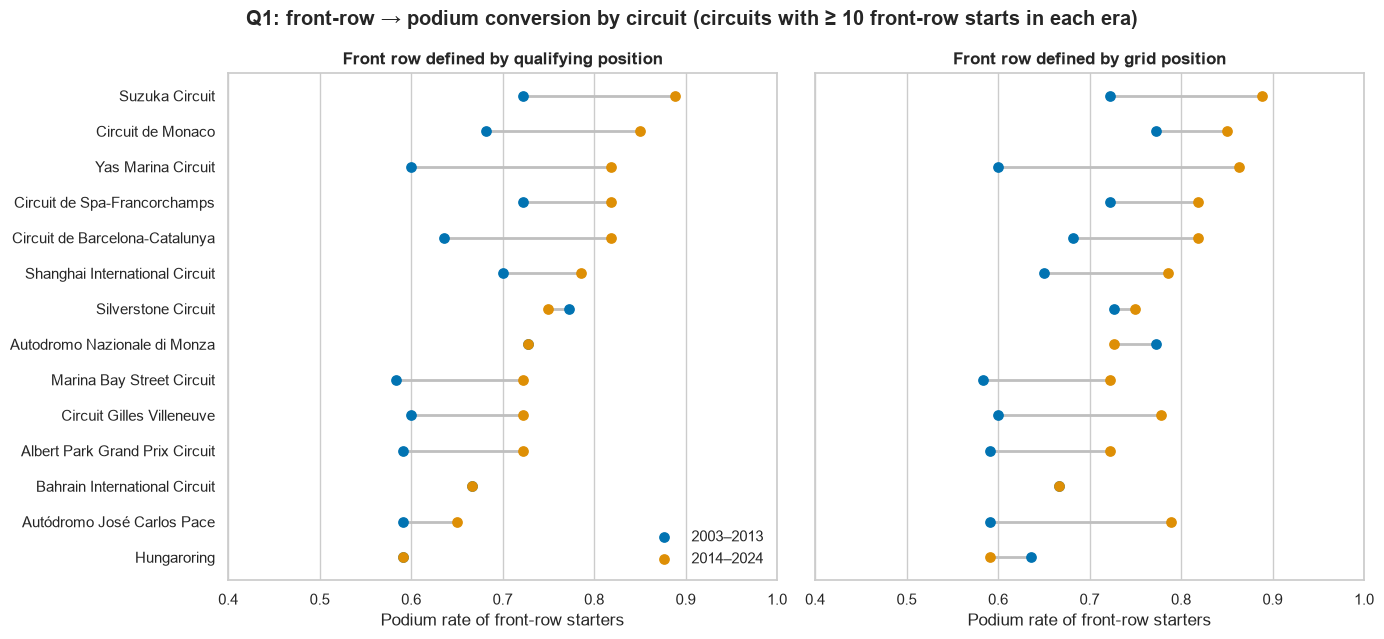

In [53]:
# ── 9. Q1 · plot: conversion rate per circuit, before vs from 2014, qualifying and grid side by side ─
order = stable["qualifying"].sort_values(f"rate {ERAS[1]}").index
pal = sns.color_palette("colorblind")
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True)
for ax, k in zip(axes, ["qualifying", "grid"]):
    w = stable[k].reindex(order)
    y = np.arange(len(w))
    a, b = w[f"rate {ERAS[0]}"].astype(float), w[f"rate {ERAS[1]}"].astype(float)
    ax.hlines(y, np.minimum(a, b), np.maximum(a, b), color="0.75", linewidth=2)
    ax.scatter(a, y, color=pal[0], s=45, label=ERAS[0], zorder=3)
    ax.scatter(b, y, color=pal[1], s=45, label=ERAS[1], zorder=3)
    ax.set_yticks(y, w.index)
    ax.set_xlim(0.4, 1.0)
    ax.set_xlabel("Podium rate of front-row starters")
    ax.set_title(f"Front row defined by {k} position")
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="lower right", frameon=False)
fig.suptitle(f"Q1: front-row → podium conversion by circuit (circuits with ≥ {MIN_STARTS} front-row starts in each era)",
             fontweight="bold")
plt.tight_layout()
plt.show()

### Q1 answer

**Which circuits convert best?** Using qualifying position, the top circuits in 2014–2024 are **Suzuka (89%)**, **Monaco (85%)**, then **Barcelona, Spa and Yas Marina (82% each)**. In 2003–2013 the top three were **Silverstone (77%)**, **Monza (73%)**, and Suzuka and Spa (72%). **Hungaroring** is last in both eras (59%).

**Does the ranking change from 2014?** Partly. The rank correlation between the two eras is **0.57** (qualifying definition) and **0.30** (grid definition), so the order is only loosely kept. Silverstone falls from 1st to 7th, while Yas Marina (+22 points), Barcelona (+18), Suzuka and Monaco (+17 each) rise. Overall, a front-row start became **more decisive**: conversion rose from **67.6% to 73.7%** (qualifying) and from **68.3% to 76.0%** (grid). 10 of the 14 circuits went up, 3 stayed the same (Monza, Bahrain, Hungaroring), and only Silverstone dropped (−2.3 points).

**Qualifying position vs grid:** they differ for 74 drivers. **38 qualified on the front row but started elsewhere** (e.g. after a grid penalty) and only **28.9%** of them reached the podium; **36 started on the front row without qualifying there** and **63.9%** did. Grid therefore converts slightly better (72.4% vs 70.8% overall) because it already includes penalties; both are known before the start, so both are leakage-safe.

**Grain, missingness, limitations:** one row per driver per race. 22 rows (2003+) have no qualifying row and count as "not front row" under the qualifying definition. Only circuits with at least 10 front-row starts in **each** era are compared (14 circuits); with 10–24 starts per cell, one podium moves a rate by 4–10 points, so neighbouring ranks are not meaningfully different. These are associations, not causes: the circuit is one factor among car pace, reliability and era.

## Q2. Do drivers podium more often at a circuit in their home country, after controlling for starting position?

- **Grain:** one row per driver per race, taken from the base table (joins used: `results` + `drivers` + `races` + `circuits`).
- **Home:** the driver's nationality matches the circuit's country. Nationality is an adjective ("British") and country a noun ("UK"), so a mapping table is built by hand below. Dual nationalities count as home in either country; "East German" maps to Germany.
- **Who is compared:** only drivers whose nationality has a home circuit in the data, so every driver in the comparison *could* race at home. Rows with `grid = 0` are left out (no comparable starting slot), as is the 2005 US GP.
- **Controlling for starting position:** home and away podium rates are compared **inside the same grid group** (P1, P2, P3, P4–5, P6–10, P11–15, P16+). The overall effect is the average of these within-group differences, weighted by how many home starts fall in each group.
- **Cutoff:** nationality, circuit and grid are all known before the start.

In [54]:
# ── 9. Q2 · nationality → country mapping (only nationalities whose country hosts a race in the data) ─
NATIONALITY_TO_COUNTRY = {
    "British": ["UK"], "Italian": ["Italy"], "French": ["France"], "German": ["Germany"], "East German": ["Germany"],
    "Brazilian": ["Brazil"], "Spanish": ["Spain"], "Australian": ["Australia"], "American": ["USA"],
    "Austrian": ["Austria"], "Japanese": ["Japan"], "Belgian": ["Belgium"], "Dutch": ["Netherlands"],
    "Canadian": ["Canada"], "Swedish": ["Sweden"], "Mexican": ["Mexico"], "Swiss": ["Switzerland"],
    "Argentine": ["Argentina"], "South African": ["South Africa"], "Monegasque": ["Monaco"], "Russian": ["Russia"],
    "Chinese": ["China"], "Indian": ["India"], "Hungarian": ["Hungary"], "Malaysian": ["Malaysia"],
    "Portuguese": ["Portugal"],
    "Argentine-Italian": ["Argentina", "Italy"], "American-Italian": ["USA", "Italy"],   # dual: home in either
}
mapped_countries = {c for cs in NATIONALITY_TO_COUNTRY.values() for c in cs}
assert mapped_countries <= set(clean["circuits"]["country"]), "a mapped country has no circuit"
unmapped = sorted(set(clean["drivers"]["nationality"].dropna()) - set(NATIONALITY_TO_COUNTRY))
print(f"{len(NATIONALITY_TO_COUNTRY)} nationalities mapped to {len(mapped_countries)} circuit countries.")
print(f"Not mapped (their country never hosts a race in the data): {unmapped}")

28 nationalities mapped to 25 circuit countries.
Not mapped (their country never hosts a race in the data): ['Chilean', 'Colombian', 'Czech', 'Danish', 'Finnish', 'Indonesian', 'Irish', 'Liechtensteiner', 'New Zealander', 'Polish', 'Rhodesian', 'Thai', 'Uruguayan', 'Venezuelan']


In [55]:
# ── 9. Q2 · data: home flag per driver-race from the base table, grid groups ─
q2 = base.loc[~base["exclude_from_model"], ["raceId", "driverId", "year", "nationality", "country", "grid", "podium"]].copy()
q2["home"] = [c in NATIONALITY_TO_COUNTRY.get(n, []) for n, c in zip(q2["nationality"], q2["country"])]
# Compare like with like: drivers who CAN have a home race, with a real grid slot (grid 0 has no comparable start).
q2 = q2[q2["nationality"].isin(NATIONALITY_TO_COUNTRY) & (q2["grid"] > 0)].copy()
GRID_BINS, GRID_LABELS = [0, 1, 2, 3, 5, 10, 15, 100], ["P1", "P2", "P3", "P4–5", "P6–10", "P11–15", "P16+"]
q2["grid_group"] = pd.cut(q2["grid"], bins=GRID_BINS, labels=GRID_LABELS)
print(f"{len(q2):,} driver-races ({int(q2['home'].sum()):,} at home), {q2['year'].min()}–{q2['year'].max()}.")
print("Where home and away drivers start (share of each group's starts):")
display(q2.groupby("home")["grid_group"].value_counts(normalize=True).unstack(0).round(3)
          .rename(columns={False: "away", True: "home"}))


def grid_adjusted(d: pd.DataFrame) -> tuple[pd.DataFrame, float, float]:
    """Podium rate home vs away inside each grid group, the raw difference, and the grid-adjusted difference
    (within-group differences weighted by how many HOME starts fall in each group)."""
    t = d.groupby(["grid_group", "home"], observed=True)["podium"].agg(["mean", "size"]).unstack("home")
    t.columns = [f"{'podium_rate' if a == 'mean' else 'starts'}_{'home' if h else 'away'}" for a, h in t.columns]
    t = t.dropna()
    t["difference"] = t["podium_rate_home"] - t["podium_rate_away"]
    adjusted = float((t["starts_home"] / t["starts_home"].sum() * t["difference"]).sum())
    raw = float(d.loc[d["home"], "podium"].mean() - d.loc[~d["home"], "podium"].mean())
    return t, raw, adjusted

22,276 driver-races (1,941 at home), 1950–2024.
Where home and away drivers start (share of each group's starts):


home,away,home
grid_group,,
P1,0.046,0.042
P2,0.045,0.040
P3,0.044,0.037
P4–5,0.089,0.075
P6–10,0.225,0.215
P11–15,0.228,0.214
P16+,0.322,0.377


In [56]:
# ── 9. Q2 · result: raw vs grid-adjusted home effect, per period, with a bootstrap interval ─
by_group, raw_all, adj_all = grid_adjusted(q2)
display(by_group.round(3))

rng = np.random.default_rng(SEED)
race_groups = dict(tuple(q2.groupby("raceId")))
race_ids = np.array(list(race_groups))
boot = [grid_adjusted(pd.concat([race_groups[i] for i in rng.choice(race_ids, len(race_ids))]))[2]
        for _ in range(300)]                                   # resample whole races, 300 times
lo, hi = np.percentile(boot, [2.5, 97.5])

periods = {"all seasons": q2, "1980–2024": q2[q2["year"] >= 1980], "2003–2024": q2[q2["year"] >= 2003]}
summary = pd.DataFrame([{"period": k, "home starts": int(d["home"].sum()),
                         "podium rate home": d.loc[d["home"], "podium"].mean(),
                         "podium rate away": d.loc[~d["home"], "podium"].mean(),
                         "raw difference": grid_adjusted(d)[1], "grid-adjusted difference": grid_adjusted(d)[2]}
                        for k, d in periods.items()]).set_index("period")
display(summary.round(3))
print(f"All seasons: raw {raw_all:+.1%}, grid-adjusted {adj_all:+.1%} "
      f"(95% bootstrap interval {lo:+.1%} to {hi:+.1%}, resampling races).")

,podium_rate_away,podium_rate_home,starts_away,starts_home,difference
grid_group,,,,,
P1,0.651,0.598,942,82,-0.053
P2,0.571,0.538,917,78,-0.033
P3,0.453,0.535,903,71,0.082
P4–5,0.295,0.342,1819,146,0.047
P6–10,0.107,0.081,4569,418,-0.026
P11–15,0.028,0.024,4639,415,-0.004
P16+,0.007,0.003,6546,731,-0.004


,home starts,podium rate home,podium rate away,raw difference,grid-adjusted difference
period,,,,,
all seasons,1941,0.116,0.135,-0.019,-0.005
1980–2024,1044,0.128,0.132,-0.004,-0.006
2003–2024,364,0.143,0.142,0.001,-0.019


All seasons: raw -1.9%, grid-adjusted -0.5% (95% bootstrap interval -1.6% to +0.8%, resampling races).


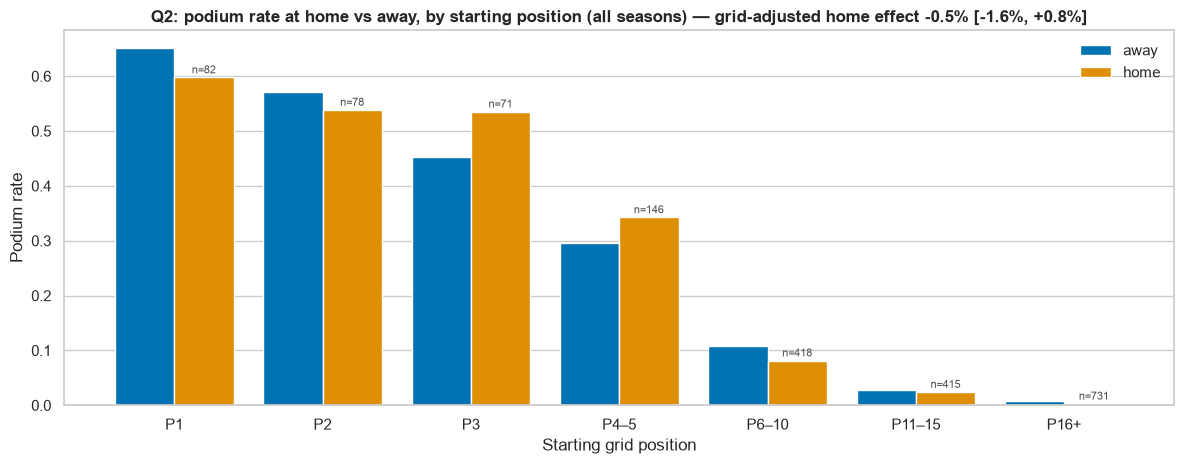

In [57]:
# ── 9. Q2 · plot: podium rate by starting position, home vs away ─
pal = sns.color_palette("colorblind")
x = np.arange(len(by_group))
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.bar(x - 0.2, by_group["podium_rate_away"], width=0.4, color=pal[0], label="away")
ax.bar(x + 0.2, by_group["podium_rate_home"], width=0.4, color=pal[1], label="home")
for i, n_h in enumerate(by_group["starts_home"]):
    ax.annotate(f"n={int(n_h)}", (i + 0.2, by_group["podium_rate_home"].iloc[i]), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=8, color="0.3")
ax.set_xticks(x, by_group.index)
ax.set_xlabel("Starting grid position")
ax.set_ylabel("Podium rate")
ax.set_title(f"Q2: podium rate at home vs away, by starting position (all seasons) — "
             f"grid-adjusted home effect {adj_all:+.1%} [{lo:+.1%}, {hi:+.1%}]")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

### Q2 answer

**No: once starting position is taken into account, drivers do not podium more often at home.**

- **Raw comparison (misleading):** home drivers podium *less* often, 11.6% vs 13.5% (−1.9 points). The reason is where they start: 37.7% of home starts are from P16 or lower, against 32.2% away, because many one-off local drivers entered only their home race.
- **Controlled for starting position:** within each grid group the differences go both ways (e.g. P1: 59.8% home vs 65.1% away; P3: 53.5% vs 45.3%), and the weighted average is **−0.5 points**, with a 95% bootstrap interval of about **−1.6 to +0.8 points**. The interval contains zero, so there is no detectable home effect.
- **Robust across periods:** grid-adjusted difference −0.6 points for 1980–2024 and −1.9 points for 2003–2024 (only 364 home starts there, so less precise). No period shows a positive home effect.

**Grain, missingness, limitations:** one row per driver per race; 22,276 driver-races, 1,941 at home. 14 nationalities have no home circuit in the data and are excluded from the comparison. Nationality is the recorded one, which can differ from where a driver grew up. Some groups are small (71–82 home starts in P1–P3), so single-group differences are noisy; the weighted average is the reliable number. This is an association, not a causal effect.

## Q3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

- **Grain:** one row per driver per race (a car's race), taken from the base table (joins used: `results` + `status` + `constructors` + `races`).
- **Race start:** every entry except those withdrawn before the start (`positionText` = "W"); a car that retires on lap 1 still started. Withdrawn entries are not counted even when their status is mechanical (e.g. Power Unit, Gearbox or ERS failing before the start), because the brief defines a mechanical retirement as "a race start that ended early because a component of the car failed".
- **Mechanical retirement** (brief's definition): the race ended early because a **component of the car failed**, not because of a crash, the driver, or a regulation decision. The status values are grouped by hand below into *mechanical*, *not mechanical* and *unclear* (status could mean a failure or contact/team error, e.g. "Wheel", "Puncture", "Retired"). Every status in 2014–2024 must land in exactly one group (checked).
- **Rate** = mechanical retirements ÷ race starts, per constructor and era, with a 95% Wilson interval. Only constructors with ≥ 40 starts in the era (about one season with two cars) are ranked.
- **Constructor** = `constructorId`, so a renamed team counts as a new constructor (as the brief notes, renames reset history).
- **Cutoff:** status is post-race information. It is used here to answer the question only, never as a model feature.

In [58]:
# ── 9. Q3 · status → reason group (documented mapping) and race starts 2014–2024 ─
MECHANICAL = [  # a component of the car failed
    "Engine", "Power Unit", "Gearbox", "Transmission", "Clutch", "Driveshaft", "Drivetrain", "Differential",
    "Brakes", "Brake duct", "Hydraulics", "Electrical", "Electronics", "Battery", "ERS", "Power loss", "Turbo",
    "Exhaust", "Oil leak", "Oil pressure", "Water pressure", "Water leak", "Water pump", "Radiator",
    "Cooling system", "Overheating", "Fuel pressure", "Fuel leak", "Fuel pump", "Throttle", "Spark plugs",
    "Steering", "Suspension", "Vibrations", "Mechanical", "Technical"]
UNCLEAR = [     # could be a failure OR contact / team error / unknown: reported separately, used in a sensitivity check
    "Retired", "Wheel", "Wheel nut", "Tyre", "Puncture", "Undertray", "Front wing", "Rear wing", "Seat",
    "Out of fuel", "Withdrew"]
NOT_MECHANICAL = [  # crash, driver, health or a regulation decision
    "Collision", "Accident", "Collision damage", "Spun off", "Damage", "Debris", "Disqualified", "Excluded", "Illness"]
assert not (set(MECHANICAL) & set(UNCLEAR) | set(MECHANICAL) & set(NOT_MECHANICAL) | set(UNCLEAR) & set(NOT_MECHANICAL))

Q3_FROM, Q3_SPLIT, Q3_TO, MIN_STARTS_Q3 = 2014, 2022, 2024, 40
q3 = (base.loc[base["year"].between(Q3_FROM, Q3_TO), ["raceId", "driverId", "year", "constructorId", "constructor",
                                                      "laps", "status", "resultId"]]
      .merge(clean["results"][["resultId", "positionText"]], on="resultId"))
started = q3["positionText"] != "W"                     # W = withdrawn: never took the start, so not a race start
print(f"{Q3_FROM}–{Q3_TO}: {len(q3):,} entries, {int((~started).sum())} withdrawn before the start (not counted).")
q3 = q3[started].copy()
finished = q3["status"].str.fullmatch(r"Finished|\+\d+ Laps?")
q3["reason"] = np.select([finished, q3["status"].isin(MECHANICAL), q3["status"].isin(UNCLEAR),
                          q3["status"].isin(NOT_MECHANICAL)],
                         ["finished", "mechanical", "unclear", "not mechanical"], default="UNMAPPED")
unmapped = sorted(q3.loc[q3["reason"] == "UNMAPPED", "status"].unique())
assert not unmapped, f"status values without a group: {unmapped}"
q3["era"] = np.where(q3["year"] >= Q3_SPLIT, f"{Q3_SPLIT}–{Q3_TO}", f"{Q3_FROM}–{Q3_SPLIT - 1}")
display(q3.groupby(["era", "reason"]).size().unstack(0))
print("Most common statuses in each group:")
display(q3.loc[q3["reason"] != "finished"].groupby(["reason", "status"]).size().rename("race starts")
          .sort_values(ascending=False).groupby(level=0).head(5))

2014–2024: 4,625 entries, 27 withdrawn before the start (not counted).


era,2014–2021,2022–2024
reason,,
finished,2660,1165
mechanical,288,74
not mechanical,228,94
unclear,70,19


Most common statuses in each group:


reason          status          
not mechanical  Collision           150
                Accident             85
mechanical      Engine               79
not mechanical  Collision damage     59
unclear         Retired              49
mechanical      Brakes               48
                Gearbox              40
                Power Unit           39
                Suspension           25
unclear         Wheel                11
not mechanical  Disqualified         11
                Spun off             11
unclear         Puncture              7
                Undertray             4
                Tyre                  4
Name: race starts, dtype: int64

In [59]:
# ── 9. Q3 · mechanical-retirement rate per constructor and era (with a 95% interval) ─
def wilson(k, n, z=1.96):
    """95% Wilson interval for a proportion k/n (stable for small n and rates near 0)."""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


rates = (q3.groupby(["era", "constructorId", "constructor"])
           .agg(starts=("reason", "size"),
                mechanical=("reason", lambda s: int((s == "mechanical").sum())),
                unclear=("reason", lambda s: int((s == "unclear").sum())))
           .reset_index())
rates["mech_rate"] = rates["mechanical"] / rates["starts"]
rates["mech_or_unclear_rate"] = (rates["mechanical"] + rates["unclear"]) / rates["starts"]
rates["ci_low"], rates["ci_high"] = wilson(rates["mechanical"], rates["starts"])
rates = rates[rates["starts"] >= MIN_STARTS_Q3]
for era, grp in rates.groupby("era"):
    overall = q3[q3["era"] == era]
    print(f"\n{era}: {len(grp)} constructors with >= {MIN_STARTS_Q3} race starts; overall mechanical rate "
          f"{(overall['reason'] == 'mechanical').mean():.1%} of {len(overall):,} starts")
    display(grp.sort_values("mech_rate", ascending=False)
               [["constructor", "starts", "mechanical", "mech_rate", "ci_low", "ci_high", "mech_or_unclear_rate"]]
               .round(3).reset_index(drop=True))
# Sensitivity: does counting the "unclear" statuses as mechanical change the ranking?
for era, grp in rates.groupby("era"):
    r1, r2 = grp["mech_rate"].rank(ascending=False), grp["mech_or_unclear_rate"].rank(ascending=False)
    print(f"{era}: Spearman between 'mechanical' and 'mechanical + unclear' rankings = {r1.corr(r2, method='spearman'):.2f}")


2014–2021: 17 constructors with >= 40 race starts; overall mechanical rate 8.9% of 3,246 starts


,constructor,starts,mechanical,mech_rate,ci_low,ci_high,mech_or_unclear_rate
0,Lotus F1,75,13,0.173,0.104,0.274,0.240
1,Toro Rosso,242,39,0.161,0.120,0.213,0.182
2,Renault,199,26,0.131,0.091,0.185,0.156
3,McLaren,316,41,0.130,0.097,0.171,0.155
4,Red Bull,318,34,0.107,0.078,0.146,0.116
5,Sauber,199,21,0.106,0.070,0.156,0.131
6,AlphaTauri,77,7,0.091,0.045,0.176,0.104
7,Racing Point,75,6,0.080,0.037,0.164,0.093
8,Haas F1 Team,241,18,0.075,0.048,0.115,0.124
9,Williams,319,23,0.072,0.049,0.106,0.094



2022–2024: 12 constructors with >= 40 race starts; overall mechanical rate 5.5% of 1,352 starts


,constructor,starts,mechanical,mech_rate,ci_low,ci_high,mech_or_unclear_rate
0,Alfa Romeo,88,11,0.125,0.071,0.210,0.125
1,Alpine F1 Team,135,14,0.104,0.063,0.167,0.104
2,AlphaTauri,88,6,0.068,0.032,0.141,0.080
3,Williams,134,7,0.052,0.026,0.104,0.082
4,Ferrari,134,6,0.045,0.021,0.094,0.067
5,Haas F1 Team,135,6,0.044,0.021,0.094,0.052
6,Mercedes,136,6,0.044,0.020,0.093,0.044
7,RB F1 Team,48,2,0.042,0.012,0.140,0.104
8,Aston Martin,134,5,0.037,0.016,0.084,0.067
9,McLaren,136,5,0.037,0.016,0.083,0.037


2014–2021: Spearman between 'mechanical' and 'mechanical + unclear' rankings = 0.97
2022–2024: Spearman between 'mechanical' and 'mechanical + unclear' rankings = 0.69


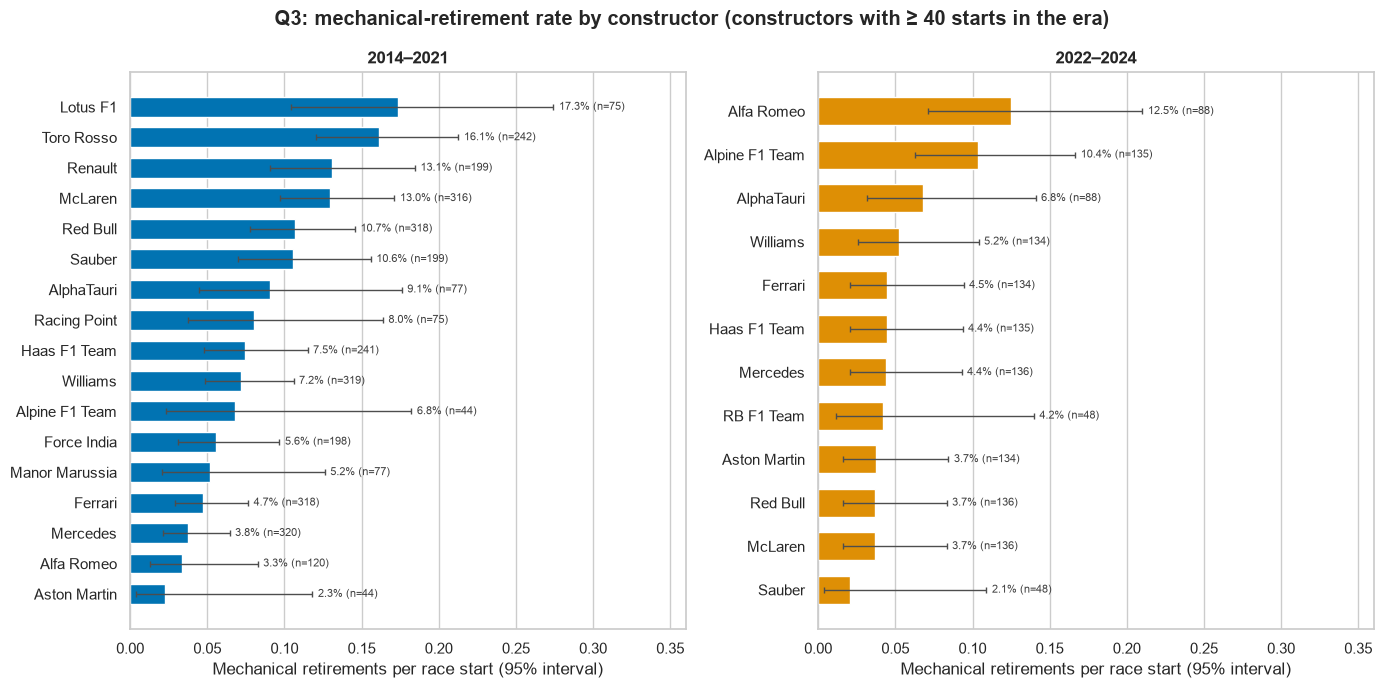

In [60]:
# ── 9. Q3 · plot: mechanical-retirement rate per constructor, one panel per era ─
pal = sns.color_palette("colorblind")
eras = sorted(rates["era"].unique())
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True)
for ax, era, colour in zip(axes, eras, [pal[0], pal[1]]):
    g = rates[rates["era"] == era].sort_values("mech_rate")
    y = np.arange(len(g))
    ax.barh(y, g["mech_rate"], color=colour, height=0.65)
    ax.errorbar(g["mech_rate"], y, xerr=[g["mech_rate"] - g["ci_low"], g["ci_high"] - g["mech_rate"]],
                fmt="none", ecolor="0.3", elinewidth=1, capsize=2)
    for yi, (r, n, hi_) in enumerate(zip(g["mech_rate"], g["starts"], g["ci_high"])):
        ax.annotate(f"{r:.1%} (n={n})", (hi_, yi), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=8, color="0.25")
    ax.set_yticks(y, g["constructor"])
    ax.set_title(f"{era}")
    ax.set_xlim(0, 0.36)
    ax.set_xlabel("Mechanical retirements per race start (95% interval)")
    ax.grid(axis="y", visible=False)
fig.suptitle(f"Q3: mechanical-retirement rate by constructor (constructors with ≥ {MIN_STARTS_Q3} starts in the era)",
             fontweight="bold")
plt.tight_layout()
plt.show()

### Q3 answer

**2014–2021 (hybrid era):** the highest mechanical-retirement rates are **Lotus F1 (17.3%, 13 of 75 starts)**, **Toro Rosso (16.1%, 39 of 242)**, **Renault (13.1%)** and **McLaren (13.0%, 41 of 316)**. The lowest among teams with many starts are **Mercedes (3.8%)** and **Ferrari (4.7%)**. Overall: **8.9%** of 3,246 race starts ended with a mechanical failure.

**2022–2024 (ground-effect era):** the highest are **Alfa Romeo (12.5%, 11 of 88)** and **Alpine F1 Team (10.4%, 14 of 135)**, then AlphaTauri (6.8%). Most teams sit between 3.7% and 5.2%; the lowest is Sauber (2.1%, only 48 starts). Overall: **5.5%** of 1,352 race starts.

**What changed:** cars became more reliable. The overall rate fell from 8.9% to 5.5%, and the leaders changed completely. McLaren fell from 13.0% to 3.7% and Red Bull from 10.7% to 3.7%; none of the four worst teams of 2014–2021 appears under the same `constructorId` in the top two of 2022–2024.

**Robustness:** counting the *unclear* statuses (e.g. "Retired", "Wheel", "Puncture") as mechanical gives almost the same ranking in 2014–2021 (rank correlation 0.97) and a similar one in 2022–2024 (0.69); the top two in each era do not change.

**Grain, missingness, limitations:** one row per car per race; 27 entries withdrawn before the start are not race starts. The status grouping is our own documented judgement. Intervals are wide for teams with fewer starts (e.g. Lotus F1: 10.4–27.4%), so teams with overlapping intervals are not clearly different. Renamed teams have a new `constructorId`, so their history restarts.

## 10. Feature selection & engineering

**Goal:** turn `base` (Section 9.0, one row per driver per race) into one leakage-safe modelling table. Each row holds the target `podium` and only information known on race morning. We build every feature on `fe`, a copy of `base`, so `base` and the Section 9 answers stay exactly reproducible. Only cleaned tables from `clean` are joined, the grain is checked after every join, and only columns in `FEATURE_COLS` can reach a model.

**The race-morning rule:** a feature is allowed only if it could have been written down after qualifying and before the lights go out. That means `PRE_RACE_COLS`, or anything computed from **earlier** races. This race's result, points, laps or status, current-race lap times and pit stops, post-race standings, and the flags `exclude_from_model`, `is_shared_drive` and `standings_excluded` are never features.

**Split, by season:** train 2003–2019 (fits the model and every fill value or scaler), validation 2020–2021 (used in Section 11 to choose the threshold and settings; never used for a decision in this section), test 2022–2024 (used once, at the end, never in this section). Seasons before 2003 serve only as history for form and standings.

**Feature groups** (reused for the ablation in Section 11):

| Group | Features |
|---|---|
| Qualifying | `quali_pos`, `quali_top10`, `q1_gap_pct`, `q1_missing`, `has_qualifying` |
| Grid | `pit_lane_start`, `grid_minus_quali` |
| Driver standings | `drv_pos_before`, `drv_points_share_before`, `is_season_opener` |
| Team standings | `team_pos_before`, `team_points_share_before` |
| Driver form | `drv_podium_rate_last5`, `drv_avg_finish_last5`, `drv_races_in_history` |
| Team form | `team_podium_rate_last5`, `team_avg_best_finish_last5` |
| Context (optional) | `year`, `circuitId`, `driver_age` |
| Extra (10.12) | only candidates that pass all four fixed rules |

Built but moved out of the features in 10.9: `grid_clean`, raw `drv_points_before` / `team_points_before`, and the re-scored shares (see the 10.9 decision).

**Where each brief requirement is met in this section:**

| Brief requirement | Cell |
|---|---|
| Feature choices justified with evidence (plots, correlations, experiments) | 10.2–10.8 evidence cells, 10.9 redundancy check, 10.12 tests |
| "Design room": our own feature choices, with documented reasoning | 10.12 (candidates tested on fixed rules) |
| Plotting the effect of the features | one evidence plot per feature group (train seasons) |
| Leakage-safe form feature (past races only) | 10.6, 10.7, with spot checks |
| Standings shifted to "before this race" | 10.4, 10.5 |
| Leakage-safe grid and qualifying features | 10.2, 10.3 |
| Unique driver–race modelling table | 10.10 |
| Appropriate, justified split | 10.1 |
| Effect of each pre-processing step on the values | before/after plots wherever a value is filled or transformed |
| At least 2 preprocessing-order experiments | designed in 10.11, run in Section 11 |
| Thresholds and settings chosen on train/validation only, never test | 10.1, 10.11, 10.12 |
| Pipeline that accepts partially-missing records (for the inference function) | 10.11 |
| Known limitations | 10.13 |

### 10.1 The split: train, validation and test by season

Every row gets a `split` label from its season: `history` (before 2003, used only as the past for form and standings), `train` (2003–2019), `validation` (2020–2021) or `test` (2022–2024). We count the rows, races and podium rate of each part, and how many training rows the 2005 US GP flag removes.

[grain ok] fe = base.copy() + split: 24,730 rows, one per (raceId, driverId)


,seasons,races,rows,podium_rows,podium_rate,excluded_from_training
split,,,,,,
history,1950–2002,686,15766,2059,13.1,0
train,2003–2019,321,6825,963,14.1,20
validation,2020–2021,39,780,117,15.0,0
test,2022–2024,68,1359,204,15.0,0


exclude_from_model drops 20 train rows (the 2005 US GP); train rows used for fitting: 6,805.


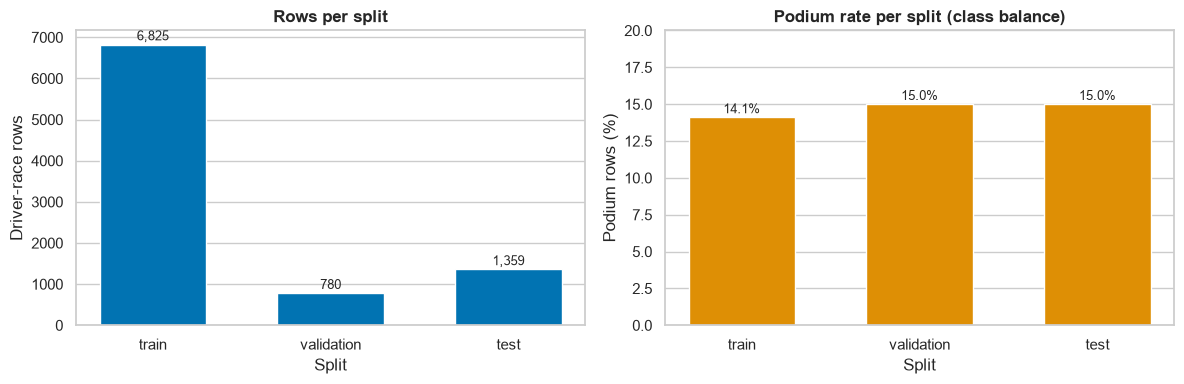

In [61]:
# ── 10.1 Split by season · features are built on `fe`, a copy; `base` is never modified ─
fe = base.copy()
BASE_SHAPE, BASE_COLUMNS, BASE_FINGERPRINT = base.shape, list(base.columns), fingerprint(base)
N_ROWS = len(base)

FEATURE_COLS = []                    # the only columns a model may see (filled in as each group is built)
HELPER_COLS = ["split"]              # added to fe but never a feature


def check_grain(df: pd.DataFrame, label: str, unmatched: int | None = None) -> None:
    """After every join: still one row per (raceId, driverId) and still N_ROWS rows."""
    assert len(df) == N_ROWS, f"{label}: row count changed to {len(df)}"
    assert not df.duplicated(["raceId", "driverId"]).any(), f"{label}: grain broken"
    extra = "" if unmatched is None else f"; rows without a match: {unmatched:,}"
    print(f"[grain ok] {label}: {len(df):,} rows, one per (raceId, driverId){extra}")


SPLIT_ORDER = ["history", "train", "validation", "test"]
fe["split"] = np.select([fe["year"] < 2003, fe["year"] <= 2019, fe["year"] <= 2021],
                        ["history", "train", "validation"], default="test")
check_grain(fe, "fe = base.copy() + split")

split_table = (fe.groupby("split")
               .agg(seasons=("year", lambda y: f"{y.min()}–{y.max()}"), races=("raceId", "nunique"),
                    rows=("raceId", "size"), podium_rows=("podium", "sum"), podium_rate=("podium", "mean"))
               .loc[SPLIT_ORDER])
split_table["podium_rate"] = (100 * split_table["podium_rate"]).round(1)
split_table["excluded_from_training"] = fe.groupby("split")["exclude_from_model"].sum().loc[SPLIT_ORDER]
display(split_table)

n_excluded_train = int((fe["exclude_from_model"] & fe["split"].eq("train")).sum())
assert n_excluded_train == int(fe["exclude_from_model"].sum()), "an excluded row lies outside train"
print(f"exclude_from_model drops {n_excluded_train} train rows (the 2005 US GP); "
      f"train rows used for fitting: {int(split_table.loc['train', 'rows']) - n_excluded_train:,}.")

parts = split_table.loc[["train", "validation", "test"]]
pal = sns.color_palette("colorblind")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.bar(parts.index, parts["rows"], color=pal[0], width=0.6)
for x, v in enumerate(parts["rows"]):
    ax1.annotate(f"{v:,}", (x, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax1.set(title="Rows per split", xlabel="Split", ylabel="Driver-race rows")
ax2.bar(parts.index, parts["podium_rate"], color=pal[1], width=0.6)
for x, v in enumerate(parts["podium_rate"]):
    ax2.annotate(f"{v:.1f}%", (x, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax2.set(title="Podium rate per split (class balance)", xlabel="Split", ylabel="Podium rows (%)", ylim=(0, 20))
for a in (ax1, ax2):
    a.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**What we found**
- **Train** (2003–2019): 321 races, 6,825 rows. **Validation** (2020–2021): 39 races, 780 rows. **Test** (2022–2024): 68 races, 1,359 rows.
- About **14–15%** of rows are podiums in every part (3 podium places per race, about 20 cars).
- The 2005 US GP removes **20 rows** from train, leaving **6,805** to learn from.

**Why split by season**
- The model learns from older seasons and is tested on newer ones, like predicting next Sunday from the past.
- A random split would let it learn from 2023 and then be tested on 2019. It could also see one driver's result and be tested on his teammate in the same race.
- **Train starts in 2003** because that is the first season where every race has qualifying data (Section 1).
- **Validation is small** (2020 had only 17 races), so tiny score differences there don't mean much.
- **Test is the newest era**, so it shows how the model would do today.

### 10.2 Qualifying features

**SEE first:** how strongly does qualifying position relate to a podium (train seasons only)? Does qualifying position already contain the Q2/Q3 lap times, so the raw times are not needed? And how many qualifying values are missing?

quali_pos,1,2,3,4,5,6,7,8,9,10
rows,320,320,320,320,320,320,320,320,320,320
podium_rate,79.1,61.9,50.6,32.8,24.4,15.9,9.1,4.4,4.1,3.8


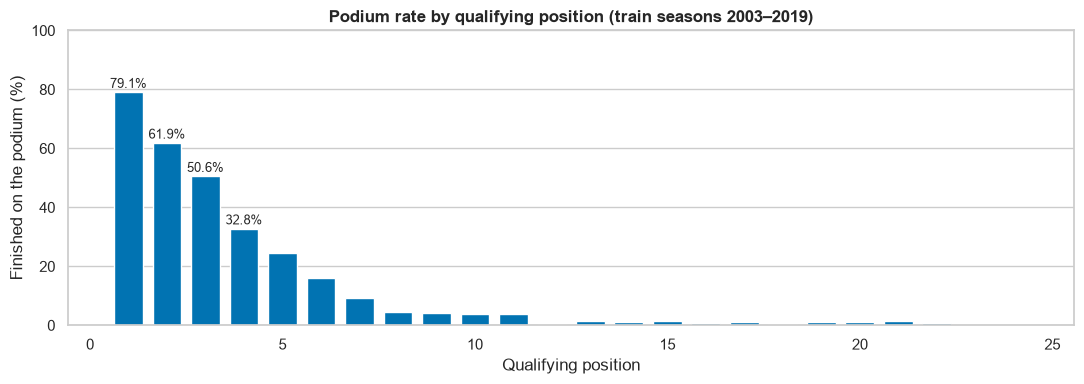

Train races from 2006: 268. Drivers with a Q3 time are ordered by Q3 in 99.3% of races, and are all ahead of drivers without one in 99.3%.
From 2003: rows without a qualifying row: 22; rows with a qualifying row but no Q1 time: 124.


In [62]:
# ── 10.2 Qualifying · SEE: podium rate by qualifying position, Q2/Q3 check, missing values (train only) ─
train_rows = fe[fe["split"].eq("train") & ~fe["exclude_from_model"]]          # the 6,805 rows a model learns from

# (1) Podium rate by qualifying position.
by_qpos = (train_rows.dropna(subset=["quali_pos"]).groupby("quali_pos")["podium"]
           .agg(rows="size", podium_rate="mean"))
by_qpos["podium_rate"] = (100 * by_qpos["podium_rate"]).round(1)
display(by_qpos.head(10).T)

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(by_qpos.index.astype(int), by_qpos["podium_rate"], color=sns.color_palette("colorblind")[0], width=0.75)
for q in [1, 2, 3, 4]:
    ax.annotate(f"{by_qpos.loc[q, 'podium_rate']:.1f}%", (q, by_qpos.loc[q, "podium_rate"]), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=9)
ax.set(title="Podium rate by qualifying position (train seasons 2003–2019)", xlabel="Qualifying position",
       ylabel="Finished on the podium (%)", ylim=(0, 100))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

# (2) Does qualifying position already contain Q2/Q3? From 2006 (knockout format), within each race:
#     drivers with a Q3 time should be ordered by Q3, and should all be ahead of drivers without one.
ko = train_rows[train_rows["year"] >= 2006].sort_values(["raceId", "quali_pos"])
with_q3 = ko.dropna(subset=["q3"])
q3_order_ok = (with_q3.groupby("raceId")["q3"].diff().fillna(0) >= 0).groupby(with_q3["raceId"]).all()
last_q3_pos = ko.loc[ko["q3"].notna()].groupby("raceId")["quali_pos"].max()
first_other_pos = ko.loc[ko["q3"].isna()].groupby("raceId")["quali_pos"].min()
q3_ahead_ok = (last_q3_pos < first_other_pos.reindex(last_q3_pos.index)).dropna()
print(f"Train races from 2006: {ko['raceId'].nunique()}. Drivers with a Q3 time are ordered by Q3 in "
      f"{100 * q3_order_ok.mean():.1f}% of races, and are all ahead of drivers without one in {100 * q3_ahead_ok.mean():.1f}%.")

# (3) Missing qualifying values from 2003 (all parts; counting gaps uses no outcome).
from_2003 = fe[fe["year"] >= 2003]
print(f"From 2003: rows without a qualifying row: {int(from_2003['quali_pos'].isna().sum())}; "
      f"rows with a qualifying row but no Q1 time: {int((from_2003['quali_pos'].notna() & from_2003['q1'].isna()).sum())}.")

**What we found**
- Qualifying position matters a lot. On pole, **79%** of drivers finished on the podium, from P2 **62%**, P3 **51%**, P4 **33%**. From P8 on, it is under 5%.
- Qualifying position already includes Q2 and Q3: the Q3 drivers are lined up by their Q3 time in **99%** of races. So we don't need the raw Q2/Q3 times.
- From 2003, **22** drivers have no qualifying record, and **124** were in qualifying but set no Q1 time. Both get filled in the next cell.

**Why it's allowed:** qualifying is over before the race. The podium numbers are only evidence from the training seasons.

**ACT:** build the qualifying features on `fe`.
- `quali_pos`: qualifying position. With no qualifying row, the driver is placed at the back: the number of cars in that race.
- `quali_top10`: qualified in the top 10.
- `q1_gap_pct`: how much slower the driver's Q1 lap was than the fastest Q1 lap of that race, in %. With no Q1 time, the slowest gap of that race is used.
- `q1_missing`: the driver has no Q1 time, either because he set no lap or because he has no qualifying row at all.
- `has_qualifying`: the driver has a qualifying row.

The original qualifying position is kept as the helper column `quali_pos_raw`. The cars per race (`n_cars`) are counted after the non-qualifiers were removed in 4b, so they are the cars that lined up for that race.

[grain ok] 10.2 qualifying features (no join): 24,730 rows, one per (raceId, driverId)
From 2003: 22 rows placed at the back by quali_pos; 146 rows with q1_missing = 1; q1_gap_pct still missing in 0 rows.
Train q1_gap_pct: 6,681 values before the fill, 6,805 after; median 1.34% -> 1.36%; 99th percentile 7.59% -> 8.47%; max 33.3%.


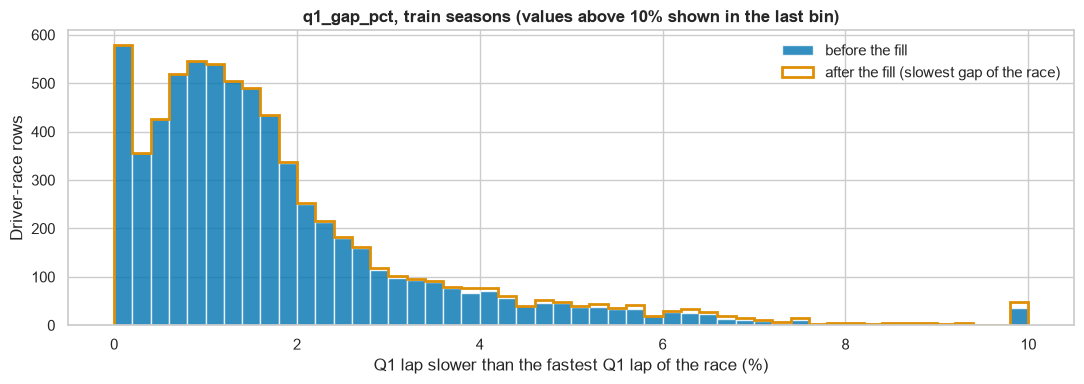

Largest q1_gap_pct values in train:


,year,race,surname,quali_pos,q1,q1_missing,q1_gap_pct
1581,2004,San Marino Grand Prix,Räikkönen,20.0,NaN,1,33.3
1582,2004,San Marino Grand Prix,Fisichella,19.0,NaN,1,33.3
1588,2004,San Marino Grand Prix,Baumgartner,18.0,106.299,0,33.3
1147,2005,Australian Grand Prix,Massa,20.0,NaN,1,26.6
1151,2005,Australian Grand Prix,Sato,19.0,NaN,1,26.6
1155,2005,Australian Grand Prix,Schumacher,18.0,117.931,0,26.6
2141,2003,Italian Grand Prix,Alonso,20.0,100.405,0,24.0
7491,2009,Brazilian Grand Prix,Fisichella,20.0,100.703,0,21.6


In [63]:
# ── 10.2 Qualifying · ACT + VERIFY: build the 5 features, look at q1_gap_pct before and after the fill ─
fe["n_cars"] = fe.groupby("raceId")["driverId"].transform("size")          # cars in this race (known pre-race)
fe["quali_pos_raw"] = fe["quali_pos"]
fe["has_qualifying"] = fe["quali_pos_raw"].notna().astype(int)
fe["quali_pos"] = fe["quali_pos_raw"].fillna(fe["n_cars"]).astype(float)   # no qualifying row -> back of the field
fe["quali_top10"] = (fe["quali_pos"] <= 10).astype(int)

fastest_q1 = fe.groupby("raceId")["q1"].transform("min")
gap_raw = 100 * (fe["q1"] - fastest_q1) / fastest_q1                         # % slower than the fastest Q1 lap
fe["q1_missing"] = fe["q1"].isna().astype(int)
fe["q1_gap_pct"] = gap_raw.fillna(gap_raw.groupby(fe["raceId"]).transform("max"))  # no Q1 time -> slowest gap
HELPER_COLS += ["n_cars", "quali_pos_raw"]
FEATURE_COLS += ["quali_pos", "quali_top10", "q1_gap_pct", "q1_missing", "has_qualifying"]
check_grain(fe, "10.2 qualifying features (no join)")

# VERIFY 1: the fills did what they should, in the rows the model will use (2003 on).
modelled = fe[fe["year"] >= 2003]
print(f"From 2003: {int((modelled['has_qualifying'] == 0).sum())} rows placed at the back by quali_pos; "
      f"{int(modelled['q1_missing'].sum())} rows with q1_missing = 1; q1_gap_pct still missing in "
      f"{int(modelled['q1_gap_pct'].isna().sum())} rows.")
assert modelled[["quali_pos", "q1_gap_pct"]].notna().all().all(), "a qualifying feature is still missing from 2003"
assert (fe.loc[fe["has_qualifying"] == 0, "quali_pos"] == fe.loc[fe["has_qualifying"] == 0, "n_cars"]).all()

# VERIFY 2: distribution of q1_gap_pct before and after the fill (train seasons only), and the largest values.
tr = fe[fe["split"].eq("train") & ~fe["exclude_from_model"]]
before, after = gap_raw[tr.index].dropna(), tr["q1_gap_pct"]
print(f"Train q1_gap_pct: {len(before):,} values before the fill, {after.notna().sum():,} after; "
      f"median {before.median():.2f}% -> {after.median():.2f}%; "
      f"99th percentile {before.quantile(0.99):.2f}% -> {after.quantile(0.99):.2f}%; max {after.max():.1f}%.")
fig, ax = plt.subplots(figsize=(11, 4))
bins = np.linspace(0, 10, 51)
ax.hist(before.clip(upper=10), bins=bins, color=sns.color_palette("colorblind")[0], alpha=0.8, label="before the fill")
ax.hist(after.clip(upper=10), bins=bins, histtype="step", linewidth=2, color=sns.color_palette("colorblind")[1],
        label="after the fill (slowest gap of the race)")
ax.set(title="q1_gap_pct, train seasons (values above 10% shown in the last bin)",
       xlabel="Q1 lap slower than the fastest Q1 lap of the race (%)", ylabel="Driver-race rows")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

largest = (tr.nlargest(8, "q1_gap_pct")[["year", "race", "surname", "quali_pos", "q1", "q1_missing", "q1_gap_pct"]]
           .round({"q1": 3, "q1_gap_pct": 1}))
print("Largest q1_gap_pct values in train:")
display(largest)

**What we found**
- After the fills, **no qualifying value is missing** from 2003 on.
- **146** drivers have no Q1 time: the 124 who set no lap, plus the 22 with no qualifying record at all.
- Most drivers are **0–3% slower** than the fastest Q1 lap. The middle driver is about **1.3%** slower.
- The fills hardly change anything (1.34% → 1.36%).
- The slowest case is **33% slower** (2004 San Marino). That is a real lap, not a mistake.

**Why it's allowed:** every value comes from that weekend's qualifying, which is over before the race.

### Decision: don't cap `q1_gap_pct`

- The very slow laps are **real laps**, not mistakes.
- There are **only a few**, and they all just mean "at the back".
- **Tree models don't care** how big a number is, only its order.
- `quali_pos` already gives the same order, without big numbers.
- Any cap value would be **picked at random**, with no proof it helps.

**For Section 11:** if logistic regression or the neural network struggle with these big values, try a different scaler (`RobustScaler`) or a log of `q1_gap_pct` on validation.

### 10.3 Grid features

The grid is where a driver actually starts, after penalties. It can differ from qualifying.
- `grid_clean`: the starting position. `grid = 0` (no grid slot) becomes the number of cars in the race, so it reads as the back of the grid and never as "better than pole".
- `pit_lane_start`: 1 where the stored grid is 0. It is computed from `grid` only, never from laps or status, which are race results.
- `grid_minus_quali`: grid minus qualifying position. Positive means the driver starts further back than he qualified (e.g. a grid penalty).

[grain ok] 10.3 grid features (no join): 24,730 rows, one per (raceId, driverId)
grid = 0: 97 rows in total, 23 of them in train; grid_clean == 0 now: 0.


,rows,podium_rate,median_quali_pos
grid_minus_quali,,,
starts ahead of quali,1449,5.5,15.0
same as quali,4957,17.4,10.0
1–5 places back,304,3.9,15.0
more than 5 back,95,7.4,10.0


Drivers who qualified in the top 5 (train):


,rows,podium_rate
starts further back,64,20.3
starts where he qualified (or ahead),1536,51.0


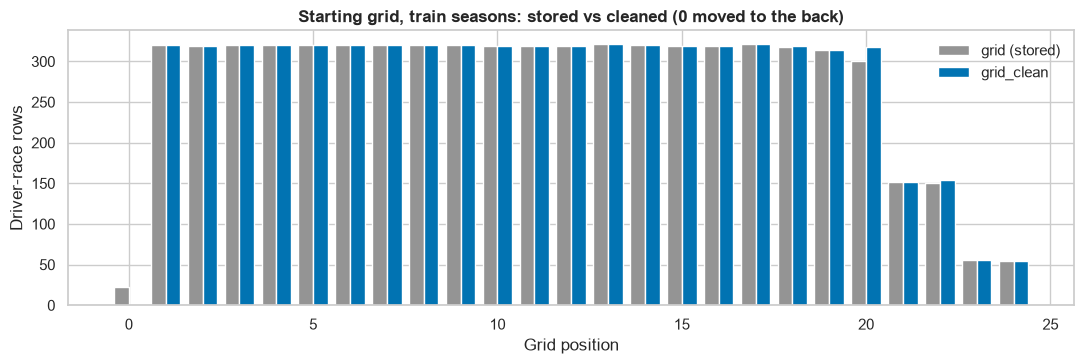

In [64]:
# ── 10.3 Grid · ACT + evidence + VERIFY ──────────────────────────────────────────
fe["pit_lane_start"] = (fe["grid"] == 0).astype(int)
fe["grid_clean"] = fe["grid"].where(fe["grid"] > 0, fe["n_cars"]).astype(float)   # 0 -> back of the grid
fe["grid_minus_quali"] = fe["grid_clean"] - fe["quali_pos"]
FEATURE_COLS += ["grid_clean", "pit_lane_start", "grid_minus_quali"]
check_grain(fe, "10.3 grid features (no join)")

tr = fe[fe["split"].eq("train") & ~fe["exclude_from_model"]]
assert (fe["grid_clean"] > 0).all(), "a grid_clean value is still 0"
print(f"grid = 0: {int((fe['grid'] == 0).sum())} rows in total, {int((tr['grid'] == 0).sum())} of them in train; "
      f"grid_clean == 0 now: {int((fe['grid_clean'] == 0).sum())}.")

# Evidence (train): podium rate when a driver starts ahead of, level with, or behind his qualifying position.
moved = pd.cut(tr["grid_minus_quali"], [-np.inf, -1, 0, 5, np.inf],
               labels=["starts ahead of quali", "same as quali", "1–5 places back", "more than 5 back"])
evidence = tr.groupby(moved, observed=True).agg(rows=("podium", "size"), podium_rate=("podium", "mean"),
                                                 median_quali_pos=("quali_pos", "median"))
evidence["podium_rate"] = (100 * evidence["podium_rate"]).round(1)
display(evidence)
# Same comparison inside the top 5 qualifiers only, so the effect is not just "who qualified well".
top5 = tr[tr["quali_pos"] <= 5]
in_top5 = top5.groupby(np.where(top5["grid_minus_quali"] > 0, "starts further back", "starts where he qualified (or ahead)"))["podium"].agg(["size", "mean"])
in_top5["mean"] = (100 * in_top5["mean"]).round(1)
print("Drivers who qualified in the top 5 (train):")
display(in_top5.rename(columns={"size": "rows", "mean": "podium_rate"}))

# VERIFY: grid before vs after (train).
fig, ax = plt.subplots(figsize=(11, 3.8))
x_before = tr["grid"].value_counts().sort_index()
x_after = tr["grid_clean"].value_counts().sort_index()
ax.bar(x_before.index - 0.2, x_before.values, width=0.4, color=sns.color_palette("colorblind")[7], label="grid (stored)")
ax.bar(x_after.index + 0.2, x_after.values, width=0.4, color=sns.color_palette("colorblind")[0], label="grid_clean")
ax.set(title="Starting grid, train seasons: stored vs cleaned (0 moved to the back)", xlabel="Grid position",
       ylabel="Driver-race rows")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**What we found**
- **97** drivers had grid 0 (23 in train). They are now placed **last**, and no grid value is 0 any more.
- 72 of the 97 really started from the pit lane. The other 25 have no normal grid slot recorded (they qualified and then didn't start, or were excluded). Too few to matter, so we just note it.
- Most drivers start **where they qualified** (4,957 of 6,805).
- **Penalties hurt.** Of drivers who qualified in the top 5, **51%** reached the podium if they started where they qualified, but only **20%** if they started further back.

**Why it's allowed:** the grid, including penalties, is fixed before the start. `pit_lane_start` only looks at grid = 0, never at laps.

### 10.4 Driver standings before the race

The championship table a driver brings into the race: his points and position **after the previous race of the same season**.
- The previous race is found by **date** within the season, from the cleaned races table (never `round − 1`, which breaks at the Indianapolis 500 gaps).
- From the full standings of that previous race, positions are **recomputed by ranking points** (ties share the best position). The stored position is never used.
- First race of a season: there is no championship order yet. Points are 0, the position is left empty (filled in 10.11 with the training median), and a new feature `is_season_opener` = 1 says why.
- A driver with no row in the previous standings: 0 points, placed just behind every ranked driver.

[grain ok] join prev_raceId: 24,730 rows, one per (raceId, driverId); rows without a match: 1,611

Races with no driver_standings rows at all: 0
[grain ok] join previous-race driver standings: 24,730 rows, one per (raceId, driverId); rows without a match: 1,311
Season openers: 1,611 rows, 358 of them in train; drv_points_before = 0 and drv_pos_before empty there (no opener reads as championship leader).


Rows with no previous-standings row (not a season opener): 1,311; of these, drivers who had scored points earlier that season: 0.


drv_pos_before,1st,2nd,3rd,4–5,6–10,11+
rows,312,306,308,606,1567,3348
podium_rate,67.6,56.2,40.9,35.1,9.0,1.4


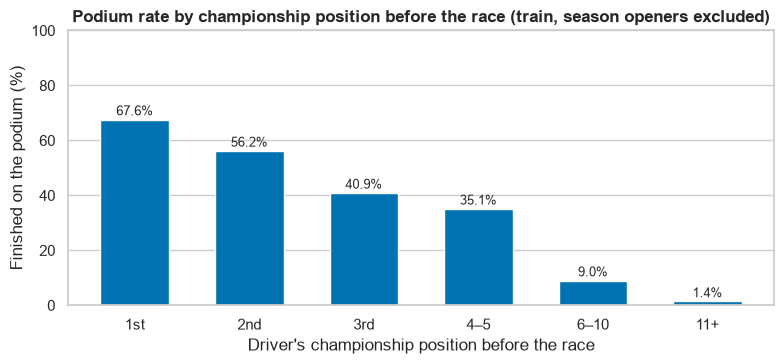

,round,race,prev_raceId,points_in_prev_standings,drv_points_before,drv_pos_before,stored_pos_prev,points_scored_this_race
0,1,Australian Grand Prix,<NA>,NaN,0.0,NaN,<NA>,0.0
1,2,Malaysian Grand Prix,900,0.0,0.0,11.0,19,25.0
2,3,Bahrain Grand Prix,901,25.0,25.0,2.0,2,25.0
3,4,Chinese Grand Prix,902,50.0,50.0,2.0,2,25.0
4,5,Spanish Grand Prix,903,75.0,75.0,2.0,2,25.0


In [65]:
# ── 10.4 Driver standings before the race · ACT + evidence + VERIFY ─────────────
# (1) Previous race of the same season, by date.
race_order = clean["races"][["raceId", "year", "date"]].sort_values(["year", "date", "raceId"])
race_order["prev_raceId"] = race_order.groupby("year")["raceId"].shift(1).astype("Int64")
fe = fe.merge(race_order[["raceId", "prev_raceId"]], on="raceId", how="left", validate="many_to_one")
check_grain(fe, "join prev_raceId", unmatched=int(fe["prev_raceId"].isna().sum()))   # unmatched = first race of a season
HELPER_COLS += ["prev_raceId"]

# Do all races have standings? A previous race with no standings rows at all would turn everyone into 0 points.
ds = clean["driver_standings"][["raceId", "driverId", "points"]].copy()
races_without_ds = sorted(set(clean["races"]["raceId"]) - set(ds["raceId"]))
print(f"Races with no driver_standings rows at all: {len(races_without_ds)}")

# (2) Full standings of each race, positions recomputed from points (ties share the best position).
ds["pos_by_points"] = ds.groupby("raceId")["points"].rank(method="min", ascending=False)
ranked_per_race = ds.groupby("raceId").size().rename("n_ranked")
prev_ds = ds.rename(columns={"raceId": "prev_raceId", "points": "drv_points_before", "pos_by_points": "drv_pos_before"})
fe = fe.merge(prev_ds, on=["prev_raceId", "driverId"], how="left", validate="many_to_one")
no_row = fe["prev_raceId"].notna() & fe["drv_points_before"].isna()
check_grain(fe, "join previous-race driver standings", unmatched=int(no_row.sum()))

n_ranked_prev = fe["prev_raceId"].map(ranked_per_race).fillna(0)
fe["drv_points_before"] = fe["drv_points_before"].fillna(0.0)               # first race / no row -> 0 points
fe["drv_pos_before"] = fe["drv_pos_before"].fillna(n_ranked_prev + 1)        # behind every ranked driver
# Season opener: no previous race, so no championship order exists yet. The position stays empty (the
# train-median imputer fills it in 10.11) instead of "1st for everyone"; the flag tells the model why.
fe["is_season_opener"] = fe["prev_raceId"].isna().astype(int)
fe.loc[fe["is_season_opener"] == 1, "drv_pos_before"] = np.nan
FEATURE_COLS += ["drv_points_before", "drv_pos_before", "is_season_opener"]
opener_train = fe["split"].eq("train") & ~fe["exclude_from_model"] & fe["is_season_opener"].eq(1)
assert not (fe.loc[fe["is_season_opener"] == 1, "drv_pos_before"] == 1).any(), "an opener still reads as leader"
assert fe.loc[fe["is_season_opener"] == 1, "drv_points_before"].eq(0).all()
print(f"Season openers: {int(fe['is_season_opener'].sum()):,} rows, {int(opener_train.sum())} of them in train; "
      f"drv_points_before = 0 and drv_pos_before empty there (no opener reads as championship leader).")

# Check the "missing row = 0 points" rule: did any driver without a previous-standings row score earlier that season?
season_points = (fe.sort_values(["year", "date"]).groupby(["year", "driverId"])["points"]
                 .transform(lambda p: p.shift(1).fillna(0).cumsum()))
earlier_pts = season_points.reindex(fe.index)
print(f"Rows with no previous-standings row (not a season opener): {int(no_row.sum()):,}; "
      f"of these, drivers who had scored points earlier that season: {int((earlier_pts[no_row] > 0).sum())}.")

# Evidence (train): podium rate by championship position before the race.
tr = fe[fe["split"].eq("train") & ~fe["exclude_from_model"] & fe["prev_raceId"].notna()]
bucket = pd.cut(tr["drv_pos_before"], [0, 1, 2, 3, 5, 10, np.inf], labels=["1st", "2nd", "3rd", "4–5", "6–10", "11+"])
ev = tr.groupby(bucket, observed=True)["podium"].agg(rows="size", podium_rate="mean")
ev["podium_rate"] = (100 * ev["podium_rate"]).round(1)
display(ev.T)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(ev.index.astype(str), ev["podium_rate"], color=sns.color_palette("colorblind")[0], width=0.6)
for x, v in enumerate(ev["podium_rate"]):
    ax.annotate(f"{v:.1f}%", (x, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.set(title="Podium rate by championship position before the race (train, season openers excluded)",
       xlabel="Driver's championship position before the race", ylabel="Finished on the podium (%)", ylim=(0, 100))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

# VERIFY: spot check. Hamilton, first 5 races of 2014: features vs the standings of the race BEFORE.
ham = fe.query("year == 2014 and surname == 'Hamilton'").sort_values("date").head(5)
stored = clean["driver_standings"][["raceId", "driverId", "points", "position"]].rename(
    columns={"raceId": "prev_raceId", "points": "points_in_prev_standings", "position": "stored_pos_prev"})
spot = ham.merge(stored, on=["prev_raceId", "driverId"], how="left")[
    ["round", "race", "prev_raceId", "points_in_prev_standings", "drv_points_before", "drv_pos_before",
     "stored_pos_prev", "points"]].rename(columns={"points": "points_scored_this_race"})
display(spot)
assert (spot["drv_points_before"].iloc[1:] == spot["points_in_prev_standings"].iloc[1:]).all()
assert spot["drv_points_before"].iloc[0] == 0

**What we found**
- The championship leader before a race reached the podium **68%** of the time, 2nd **56%**, 3rd **41%**, and 11th or lower only **1%**.
- **1,311** drivers had no row in the previous standings, usually their first race of the season. None of them had scored points before, so **0 points is true**.
- **Hamilton 2014 check:** his points before rounds 1–5 are **0, 0, 25, 50, 75**, always his points from the race before. ✅
- **Season openers (1,611 rows, 358 in train):** before round 1 nobody has a position, so it is left empty instead of making every driver "1st". `is_season_opener` marks these rows.
- Drivers with the same points share the same position (Hamilton is 11th before round 2, tied with everyone on 0).

**Why it's allowed:** the standings after the previous race are known before this race. This race's points are never used.

**Points as a share, so they mean the same in every season**

Raw points are hard to compare between rows:
- **Different eras:** a win was worth 10 points before 2010 and 25 after.
- **Season progress:** 25 points makes you leader before round 2, but a backmarker before round 20.

A **share** fixes both. Instead of "how many points", it asks "how close to the leader?" (1.0 = the leader, 0.5 = half the leader's points). We build two versions:
- `drv_points_share_before`: **official** points ÷ the leader's points, from the previous race's standings.
- `drv_points_share_rescored`: every earlier result of the season **re-scored with today's table** (25-18-15-12-10-8-6-4-2-1 for 1st–10th), then ÷ the best such total among the drivers in this race. This also fixes the table's *shape*: 2nd place was 0.80 of a win before 2010 but 0.72 after.
- The cost of the re-scored version: bonus points (fastest lap, sprints, double points) are ignored, so it measures **finishing strength**, not the official championship.

Both are empty at a season opener. The raw points and positions stay for now; 10.9 and the Section 11 ablation decide which versions to keep.

[grain ok] 10.4 driver points shares (no join): 24,730 rows, one per (raceId, driverId)


,round,race,positionOrder,rescored_pts,drv_rescored_before,drv_points_before,drv_points_share_before,drv_points_share_rescored,by_hand_rescored_before,best_rescored_in_race
18302,1,Bahrain Grand Prix,4,12.0,0.0,0.0,NaN,NaN,0.0,0.0
18339,2,Australian Grand Prix,17,0.0,12.0,12.0,0.480,0.480,12.0,25.0
18347,3,Malaysian Grand Prix,1,25.0,12.0,12.0,0.324,0.324,12.0,37.0
18376,4,Chinese Grand Prix,6,8.0,37.0,37.0,0.949,0.949,37.0,39.0
18397,5,Spanish Grand Prix,3,15.0,45.0,45.0,0.750,0.750,45.0,60.0
18420,6,Monaco Grand Prix,2,18.0,60.0,60.0,0.857,0.857,60.0,70.0


,median points for a win,median points for 2nd,median leader points before the race,2nd as a share of a win
era,,,,
2003–2009,10.0,8.0,64.0,0.80
2010–2019,25.0,18.0,174.5,0.72


Correlation between the official and the re-scored share (train): 0.999


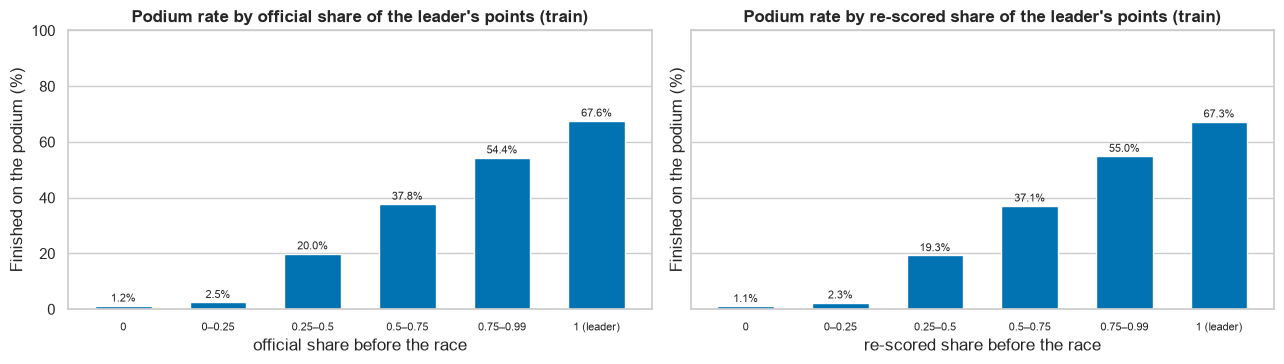

In [66]:
# ── 10.4 Driver points as a share · ACT + evidence + VERIFY ─────────────────────
# (a) Official share: points before the race ÷ the leader's points in the previous race's standings.
leader_pts = ds.groupby("raceId")["points"].max()
prev_leader = fe["prev_raceId"].map(leader_pts)
fe["drv_points_share_before"] = (fe["drv_points_before"] / prev_leader.where(prev_leader > 0)).astype(float)

# (b) Re-scored share: one points table (2010+) for every era, over EARLIER races of the same season only.
RESCORE = {1: 25, 2: 18, 3: 15, 4: 12, 5: 10, 6: 8, 7: 6, 8: 4, 9: 2, 10: 1}
fe["rescored_pts"] = fe["positionOrder"].map(RESCORE).fillna(0).astype(float)      # helper: a race RESULT
season = fe.sort_values(["year", "driverId", "date"])
fe["drv_rescored_before"] = (season.groupby(["year", "driverId"])["rescored_pts"].cumsum()
                             - season["rescored_pts"]).reindex(fe.index)          # strictly before this race
best_in_race = fe.groupby("raceId")["drv_rescored_before"].transform("max")
fe["drv_points_share_rescored"] = fe["drv_rescored_before"] / best_in_race.where(best_in_race > 0)
fe.loc[fe["is_season_opener"] == 1, ["drv_points_share_before", "drv_points_share_rescored"]] = np.nan
HELPER_COLS += ["rescored_pts", "drv_rescored_before"]
FEATURE_COLS += ["drv_points_share_before", "drv_points_share_rescored"]
check_grain(fe, "10.4 driver points shares (no join)")

# VERIFY 1: the re-scored totals use only earlier races (a second way: self-join on earlier dates).
pairs = fe[["raceId", "driverId", "year", "date"]].merge(
    fe[["driverId", "year", "date", "rescored_pts"]], on=["driverId", "year"], suffixes=("", "_earlier"))
second_way = (pairs[pairs["date_earlier"] < pairs["date"]].groupby(["raceId", "driverId"])["rescored_pts"].sum())
cmp = fe.set_index(["raceId", "driverId"])["drv_rescored_before"]
assert np.allclose(cmp, second_way.reindex(cmp.index).fillna(0)), "re-scored totals include a non-earlier race"
assert not (fe.loc[fe["is_season_opener"] == 1, ["drv_points_share_before", "drv_points_share_rescored"]].notna()).any().any()

# VERIFY 2 (spot check by hand): Vettel 2010, rounds 1–6.
vet = fe.query("year == 2010 and surname == 'Vettel'").sort_values("date").head(6)
vet_check = vet[["round", "race", "positionOrder", "rescored_pts", "drv_rescored_before", "drv_points_before",
                 "drv_points_share_before", "drv_points_share_rescored"]].copy()
vet_check["by_hand_rescored_before"] = vet["rescored_pts"].cumsum().shift(1).fillna(0).to_numpy()
vet_check["best_rescored_in_race"] = best_in_race[vet.index].to_numpy()
display(vet_check.round(3))
assert np.allclose(vet_check["drv_rescored_before"], vet_check["by_hand_rescored_before"])

# Evidence (train, openers excluded): the scale change, podium rate by share, and how similar the two shares are.
tr = fe[fe["split"].eq("train") & ~fe["exclude_from_model"] & fe["is_season_opener"].eq(0)]
tr = tr.assign(era=np.where(tr["year"] < 2010, "2003–2009", "2010–2019"))
scale = pd.DataFrame({
    "median points for a win": tr[tr["positionOrder"].eq(1)].groupby("era")["points"].median(),
    "median points for 2nd": tr[tr["positionOrder"].eq(2)].groupby("era")["points"].median(),
    "median leader points before the race": tr.groupby(["era", "raceId"])["drv_points_before"].max().groupby("era").median(),
})
scale["2nd as a share of a win"] = (scale["median points for 2nd"] / scale["median points for a win"]).round(2)
display(scale)
shares = ["drv_points_share_before", "drv_points_share_rescored"]
print(f"Correlation between the official and the re-scored share (train): "
      f"{tr[shares].corr().iloc[0, 1]:.3f}")
edges = [-0.001, 0, 0.25, 0.5, 0.75, 0.999, 1.0]
labels = ["0", "0–0.25", "0.25–0.5", "0.5–0.75", "0.75–0.99", "1 (leader)"]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, col, title in zip(axes, shares, ["official share", "re-scored share"]):
    b = pd.cut(tr[col], edges, labels=labels)
    ev = tr.groupby(b, observed=True)["podium"].agg(rows="size", podium_rate="mean")
    ax.bar(ev.index.astype(str), 100 * ev["podium_rate"], color=sns.color_palette("colorblind")[0], width=0.6)
    for x, v in enumerate(100 * ev["podium_rate"]):
        ax.annotate(f"{v:.1f}%", (x, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)
    ax.set(title=f"Podium rate by {title} of the leader's points (train)", xlabel=f"{title} before the race",
           ylabel="Finished on the podium (%)", ylim=(0, 100))
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**What we found**
- **The scale really changed:** a win was worth **10** points in 2003–2009 and **25** in 2010–2019, and 2nd place was **0.80** of a win before 2010 but **0.72** after. The leader had a median of **64** points before a race in 2003–2009 against **174.5** in 2010–2019.
- **The share works:** the closer a driver is to the leader, the more often he reaches the podium. Leader **68%**, 75–99% of the leader **54%**, under a quarter of the leader **2.5%**.
- **The two shares are almost the same** in train (correlation **0.999**), so re-scoring changes very little in practice. 10.9 decides whether to keep both.
- **Vettel 2010 check:** his re-scored total before each race matches a by-hand running total of his earlier results (0, 12, 12, 37, 45, 60). ✅
- A second way of computing the totals (only races with an earlier date) gives the same numbers for every row. ✅

**Why it's allowed:** both shares use only races before this one. The leader's points come from the previous race's standings, and the re-scored totals stop just before this race.

### 10.5 Team standings before the race

The same idea for the team: its constructors' championship points and position **after the previous race of the season**, joined on the team the driver races for (`constructorId` from `base`, i.e. from results, never from qualifying). Positions are recomputed by ranking points, so McLaren 2007, stored as 11th all season, gets its real place. Same fills as 10.4: 0 points at a season opener (with the position left empty, since no order exists yet) or with no row (placed behind every ranked team).

Races with no constructor_standings rows: 56 (seasons 1950–1957; the constructors' championship starts in 1958)
[grain ok] join previous-race constructor standings: 24,730 rows, one per (raceId, driverId); rows without a match: 1,314


From 2003: rows with no previous team-standings row: 31; of these, teams that had scored earlier that season: 0.


team_pos_before,1st,2nd,3rd,4–5,6+
rows,608,612,610,1226,3391
podium_rate,58.9,43.3,26.1,7.0,1.2


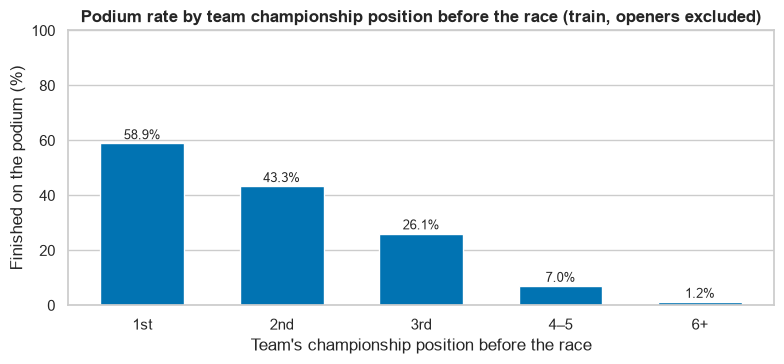

round,1,2,3,4,5,6,7,8
team_points_before,0.0,14.0,32.0,44.0,58.0,76.0,88.0,106.0
team_pos_before,NaN,1.0,1.0,1.0,1.0,1.0,1.0,1.0
stored_pos_prev,<NA>,11,11,11,11,11,11,11


McLaren 2007, rounds 2–17: recomputed position 1–1 (stored: [11]). Teammates always share the same team values.


In [67]:
# ── 10.5 Team standings before the race · ACT + evidence + VERIFY ───────────────
cs = clean["constructor_standings"][["raceId", "constructorId", "points"]].copy()
races_without_cs = clean["races"].loc[~clean["races"]["raceId"].isin(cs["raceId"]), "year"]
print(f"Races with no constructor_standings rows: {len(races_without_cs)} "
      f"(seasons {races_without_cs.min()}–{races_without_cs.max()}; the constructors' championship starts in 1958)")
assert races_without_cs.max() < 2003, "a modelled season has no constructor standings"

cs["pos_by_points"] = cs.groupby("raceId")["points"].rank(method="min", ascending=False)
teams_ranked = cs.groupby("raceId").size().rename("n_ranked")
prev_cs = cs.rename(columns={"raceId": "prev_raceId", "points": "team_points_before", "pos_by_points": "team_pos_before"})
fe = fe.merge(prev_cs, on=["prev_raceId", "constructorId"], how="left", validate="many_to_one")
no_team_row = fe["prev_raceId"].notna() & fe["team_points_before"].isna()
check_grain(fe, "join previous-race constructor standings", unmatched=int(no_team_row.sum()))
fe["team_points_before"] = fe["team_points_before"].fillna(0.0)
fe["team_pos_before"] = fe["team_pos_before"].fillna(fe["prev_raceId"].map(teams_ranked).fillna(0) + 1)
# Season opener: no team order exists yet; leave the position empty (imputed in 10.11), keep 0 points.
fe.loc[fe["is_season_opener"] == 1, "team_pos_before"] = np.nan
assert not (fe.loc[fe["is_season_opener"] == 1, "team_pos_before"] == 1).any(), "an opener still reads as leader"
assert fe.loc[fe["is_season_opener"] == 1, "team_points_before"].eq(0).all()
FEATURE_COLS += ["team_points_before", "team_pos_before"]

# Check the "missing row = 0 points" rule for teams, from 2003 (the modelled seasons).
team_race_pts = fe.groupby(["year", "date", "raceId", "constructorId"], as_index=False)["points"].sum()
team_race_pts["earlier_pts"] = (team_race_pts.sort_values("date").groupby(["year", "constructorId"])["points"]
                                .transform(lambda p: p.shift(1).fillna(0).cumsum()))
chk = fe.merge(team_race_pts[["raceId", "constructorId", "earlier_pts"]], on=["raceId", "constructorId"], how="left")
miss_2003 = no_team_row & fe["year"].ge(2003)
print(f"From 2003: rows with no previous team-standings row: {int(miss_2003.sum())}; "
      f"of these, teams that had scored earlier that season: {int((chk.loc[miss_2003, 'earlier_pts'] > 0).sum())}.")

# Evidence (train): podium rate by team position before the race.
tr = fe[fe["split"].eq("train") & ~fe["exclude_from_model"] & fe["prev_raceId"].notna()]
bucket = pd.cut(tr["team_pos_before"], [0, 1, 2, 3, 5, np.inf], labels=["1st", "2nd", "3rd", "4–5", "6+"])
ev = tr.groupby(bucket, observed=True)["podium"].agg(rows="size", podium_rate="mean")
ev["podium_rate"] = (100 * ev["podium_rate"]).round(1)
display(ev.T)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(ev.index.astype(str), ev["podium_rate"], color=sns.color_palette("colorblind")[0], width=0.6)
for x, v in enumerate(ev["podium_rate"]):
    ax.annotate(f"{v:.1f}%", (x, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.set(title="Podium rate by team championship position before the race (train, openers excluded)",
       xlabel="Team's championship position before the race", ylabel="Finished on the podium (%)", ylim=(0, 100))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

# VERIFY: McLaren 2007 (stored as 11th every round) and teammates sharing one value.
mcl = fe.query("year == 2007 and constructor == 'McLaren'")
stored_cs = clean["constructor_standings"][["raceId", "constructorId", "position"]].rename(
    columns={"raceId": "prev_raceId", "position": "stored_pos_prev"})
mcl_spot = (mcl.merge(stored_cs, on=["prev_raceId", "constructorId"], how="left")
            .groupby("round").agg(team_points_before=("team_points_before", "first"),
                                  team_pos_before=("team_pos_before", "first"), stored_pos_prev=("stored_pos_prev", "first")))
display(mcl_spot.head(8).T)
mates_differ = fe.groupby(["raceId", "constructorId"])[["team_points_before", "team_pos_before"]].nunique().gt(1).any(axis=1)
assert not mates_differ.any(), "teammates in the same race got different team standings"
print(f"McLaren 2007, rounds 2–17: recomputed position {int(mcl_spot['team_pos_before'].iloc[1:].min())}–"
      f"{int(mcl_spot['team_pos_before'].iloc[1:].max())} (stored: {sorted(int(p) for p in mcl_spot['stored_pos_prev'].dropna().unique())}). "
      f"Teammates always share the same team values.")

**What we found**
- Drivers of the **leading team** reached the podium **59%** of the time, the 2nd team **43%**, the 3rd **26%**, and teams 6th or lower only **1%**.
- **McLaren 2007 is fixed:** the stored table says 11th all season, but ranked by points they are **1st** before every round from 2 to 17. ✅
- **Season openers:** the team position is left empty instead of making every team "1st"; points stay 0.
- Both drivers of a team always get **the same team values**. ✅
- From 2003, 31 rows had no team in the previous standings. None of those teams had scored before, so **0 points is true**.
- Before 1958 there was no team championship. That only affects history rows.

**Why it's allowed:** the team standings after the previous race are known before this race. The stored (wrong) position is never used.

**Team points as a share**

The same two shares as in 10.4, for the team:
- `team_points_share_before`: **official** team points ÷ the leading team's points, from the previous race's constructor standings.
- `team_points_share_rescored`: per race, both cars' results are re-scored with today's table and **added up first**. Then the team's total over earlier races of the season is divided by the best such total among the teams in this race.

Both are empty at a season opener, and both drivers of a team always get the same values.

[grain ok] join team re-scored totals: 24,730 rows, one per (raceId, driverId); rows without a match: 0


,date,rescored_pts,by_hand_before,team_rescored_before,team_points_share_rescored,team_points_before,team_points_share_before
0,2008-03-16,4.0,0.0,0.0,NaN,0.0,NaN
1,2008-03-23,25.0,4.0,4.0,0.114,1.0,0.071
2,2008-04-06,43.0,29.0,29.0,0.483,11.0,0.458
3,2008-04-27,43.0,72.0,72.0,0.986,29.0,0.967
4,2008-05-11,40.0,115.0,115.0,1.000,47.0,1.000
5,2008-05-25,17.0,155.0,155.0,1.000,63.0,1.000


Median points of the leading team before the race: {'2003–2009': 106.0, '2010–2019': 311.0}
Correlation between the official and the re-scored team share (train): 0.999


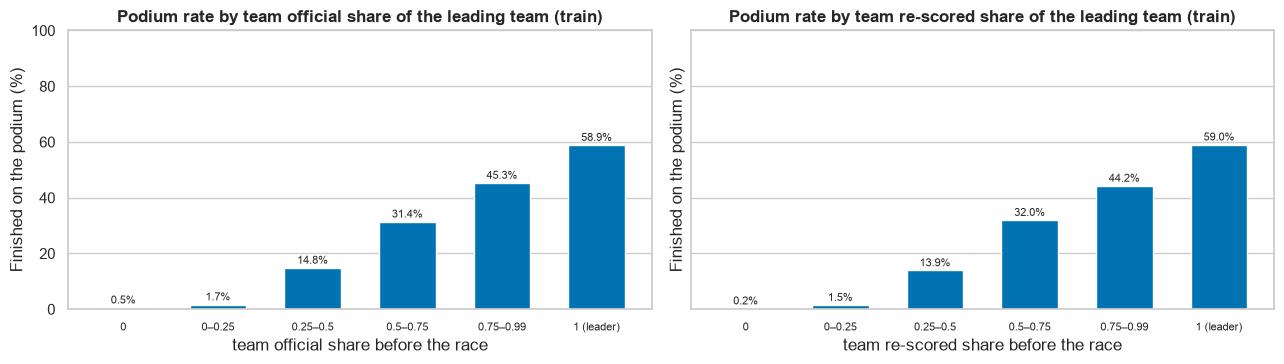

In [68]:
# ── 10.5 Team points as a share · ACT + evidence + VERIFY ───────────────────────
# (a) Official share: team points before the race ÷ the leading team's points in the previous race's standings.
team_leader_pts = cs.groupby("raceId")["points"].max()
prev_team_leader = fe["prev_raceId"].map(team_leader_pts)
fe["team_points_share_before"] = (fe["team_points_before"] / prev_team_leader.where(prev_team_leader > 0)).astype(float)

# (b) Re-scored share: add both cars per team per race FIRST, then sum over earlier races of the season.
team_rescored = (fe.groupby(["year", "constructorId", "raceId", "date"], as_index=False)["rescored_pts"].sum()
                 .sort_values(["year", "constructorId", "date"]))
team_rescored["team_rescored_before"] = (team_rescored.groupby(["year", "constructorId"])["rescored_pts"].cumsum()
                                         - team_rescored["rescored_pts"])          # strictly before this race
team_rescored["best_team_in_race"] = team_rescored.groupby("raceId")["team_rescored_before"].transform("max")
team_rescored["team_points_share_rescored"] = (team_rescored["team_rescored_before"]
                                               / team_rescored["best_team_in_race"].where(team_rescored["best_team_in_race"] > 0))
fe = fe.merge(team_rescored[["raceId", "constructorId", "team_rescored_before", "team_points_share_rescored"]],
              on=["raceId", "constructorId"], how="left", validate="many_to_one")
check_grain(fe, "join team re-scored totals", unmatched=int(fe["team_rescored_before"].isna().sum()))
fe.loc[fe["is_season_opener"] == 1, ["team_points_share_before", "team_points_share_rescored"]] = np.nan
HELPER_COLS += ["team_rescored_before"]
FEATURE_COLS += ["team_points_share_before", "team_points_share_rescored"]

# VERIFY 1: teammates share identical team values.
team_cols = ["team_points_share_before", "team_points_share_rescored", "team_rescored_before"]
assert (fe.groupby(["raceId", "constructorId"])[team_cols].nunique(dropna=False) <= 1).all().all(), "teammates differ"
# VERIFY 2: a second way, adding every earlier car-result of the team that season.
tp = fe[["raceId", "constructorId", "year", "date"]].drop_duplicates().merge(
    fe[["constructorId", "year", "date", "rescored_pts"]], on=["constructorId", "year"], suffixes=("", "_earlier"))
second_way_t = tp[tp["date_earlier"] < tp["date"]].groupby(["raceId", "constructorId"])["rescored_pts"].sum()
cmp_t = team_rescored.set_index(["raceId", "constructorId"])["team_rescored_before"]
assert np.allclose(cmp_t, second_way_t.reindex(cmp_t.index).fillna(0)), "team re-scored totals include a non-earlier race"

# VERIFY 3 (spot check by hand): Ferrari 2008, rounds 1–6 (before 2010, so official and re-scored differ).
fer_id = int(fe.loc[fe["constructor"].eq("Ferrari") & fe["year"].eq(2008), "constructorId"].iloc[0])
fer = team_rescored[team_rescored["constructorId"].eq(fer_id) & team_rescored["year"].eq(2008)].head(6).copy()
fer["by_hand_before"] = fer["rescored_pts"].cumsum().shift(1).fillna(0)
fer = fer.merge(fe.groupby(["raceId", "constructorId"])[["team_points_before", "team_points_share_before"]].first(),
                on=["raceId", "constructorId"])
display(fer.assign(date=fer["date"].dt.strftime("%Y-%m-%d"))[["date", "rescored_pts", "by_hand_before", "team_rescored_before", "team_points_share_rescored",
             "team_points_before", "team_points_share_before"]].round(3))
assert np.allclose(fer["team_rescored_before"], fer["by_hand_before"])

# Evidence (train, openers excluded).
tr = fe[fe["split"].eq("train") & ~fe["exclude_from_model"] & fe["is_season_opener"].eq(0)]
tr = tr.assign(era=np.where(tr["year"] < 2010, "2003–2009", "2010–2019"))
print("Median points of the leading team before the race:",
      tr.groupby(["era", "raceId"])["team_points_before"].max().groupby("era").median().to_dict())
tshares = ["team_points_share_before", "team_points_share_rescored"]
print(f"Correlation between the official and the re-scored team share (train): {tr[tshares].corr().iloc[0, 1]:.3f}")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, col, title in zip(axes, tshares, ["official share", "re-scored share"]):
    b = pd.cut(tr[col], edges, labels=labels)
    ev = tr.groupby(b, observed=True)["podium"].agg(rows="size", podium_rate="mean")
    ax.bar(ev.index.astype(str), 100 * ev["podium_rate"], color=sns.color_palette("colorblind")[0], width=0.6)
    for x, v in enumerate(100 * ev["podium_rate"]):
        ax.annotate(f"{v:.1f}%", (x, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)
    ax.set(title=f"Podium rate by team {title} of the leading team (train)", xlabel=f"team {title} before the race",
           ylabel="Finished on the podium (%)", ylim=(0, 100))
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**What we found**
- **The team scale changed too:** the leading team had a median of **106** points before a race in 2003–2009 against **311** in 2010–2019.
- **The share works:** the closer a team is to the leading team, the more often its drivers reach the podium: leading team **59%**, 75–99% of the leader **45%**, under a quarter of the leader **1.7%**.
- **The two team shares are almost the same** in train (correlation **0.999**). 10.9 decides whether to keep both.
- **Ferrari 2008 check:** the re-scored team total before each race matches a by-hand running total (0, 4, 29, 72, 115, 155). Before 2010 the two shares differ a little, e.g. **0.07** official vs **0.11** re-scored before round 2. ✅
- Both drivers of a team always get **the same values**, and a second way of computing the totals gives the same numbers. ✅

**Why it's allowed:** only the team's earlier races of the season are used. Both cars are added up per race first, so a teammate's result from this race never gets in.

### 10.6 Driver form: his last 5 races

How the driver has been doing lately, using **only races before this one**:
- `drv_podium_rate_last5`: share of his last 5 races that ended on the podium
- `drv_avg_finish_last5`: his average finishing position in his last 5 races
- `drv_races_in_history`: how many earlier races he has (0 = debut)

The 2005 US GP is not counted as history (only 6 cars raced, so it says nothing about pace). A debut has no history, so the two form values stay empty here. The pipeline in 10.11 fills them later with the training median, plus a "was empty" flag. They are never filled with 0, which would look like "perfect average finish" or "never on the podium".

[grain ok] 10.6 driver form (merge_asof on earlier races): 24,730 rows, one per (raceId, driverId); rows without a match: 688
Debut rows (no earlier race): 688 in total, 75 in train; their form values are empty, to be filled in 10.11.


,round,race,positionOrder,podium,drv_avg_finish_last5,drv_podium_rate_last5,manual_avg_of_previous_5
19328,6,Monaco Grand Prix,3,True,4.8,0.4,4.8
19354,7,Canadian Grand Prix,5,False,4.4,0.6,4.4
19374,8,European Grand Prix,1,True,5.2,0.4,5.2
19398,9,British Grand Prix,2,True,3.6,0.6,3.6
19421,10,German Grand Prix,1,True,2.6,0.8,2.6
19449,11,Hungarian Grand Prix,5,False,2.4,0.8,2.4


drv_podium_rate_last5,0%,1–20%,21–40%,41–60%,61–100%
rows,4630,781,503,404,412
podium_rate,2.9,20.4,39.8,47.8,66.0


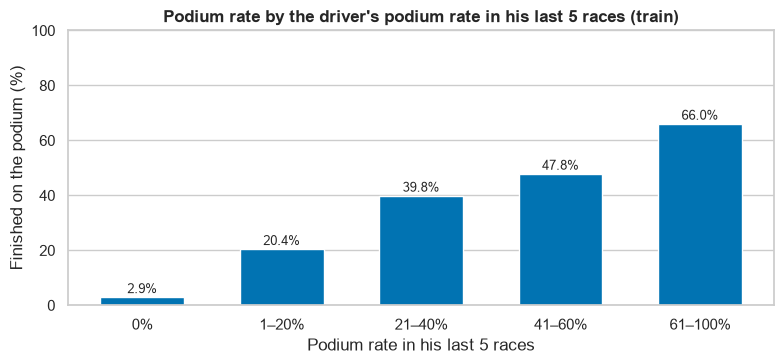

In [69]:
# ── 10.6 Driver form · ACT + evidence + VERIFY ──────────────────────────────────
# History = every earlier race of the driver, except the 2005 US GP.
hist = (fe.loc[~fe["exclude_from_model"], ["driverId", "date", "raceId", "podium", "positionOrder"]]
        .sort_values(["driverId", "date"]).reset_index(drop=True))
g = hist.groupby("driverId")
# Form AFTER each history race (that race included); it becomes the form BEFORE the driver's next race.
hist["rate_after"] = g["podium"].transform(lambda s: s.astype(float).rolling(5, min_periods=1).mean())
hist["finish_after"] = g["positionOrder"].transform(lambda s: s.astype(float).rolling(5, min_periods=1).mean())
hist["count_after"] = g.cumcount() + 1

# For every row, take the form after his most recent race strictly BEFORE this race's date.
order = fe.sort_values("date").index
prior = pd.merge_asof(fe.loc[order, ["driverId", "date"]].reset_index(),
                      hist[["driverId", "date", "rate_after", "finish_after", "count_after"]].sort_values("date"),
                      on="date", by="driverId", direction="backward", allow_exact_matches=False).set_index("index")
fe["drv_podium_rate_last5"] = prior["rate_after"].reindex(fe.index)
fe["drv_avg_finish_last5"] = prior["finish_after"].reindex(fe.index)
fe["drv_races_in_history"] = prior["count_after"].reindex(fe.index).fillna(0).astype(int)
FEATURE_COLS += ["drv_podium_rate_last5", "drv_avg_finish_last5", "drv_races_in_history"]
check_grain(fe, "10.6 driver form (merge_asof on earlier races)", unmatched=int(fe["drv_podium_rate_last5"].isna().sum()))

# VERIFY 1 (all rows): the same values as "shift by one race, then roll over 5", computed a second way.
hist["rate_before_check"] = g["podium"].transform(lambda s: s.astype(float).shift(1).rolling(5, min_periods=1).mean())
check = fe.loc[~fe["exclude_from_model"], ["driverId", "raceId", "drv_podium_rate_last5"]].merge(
    hist[["driverId", "raceId", "rate_before_check"]], on=["driverId", "raceId"])
assert np.allclose(check["drv_podium_rate_last5"].fillna(-1), check["rate_before_check"].fillna(-1)), "form mismatch"
debuts = fe[fe["drv_races_in_history"] == 0]
print(f"Debut rows (no earlier race): {len(debuts):,} in total, {int(debuts['split'].eq('train').sum())} in train; "
      f"their form values are empty, to be filled in 10.11.")

# VERIFY 2 (spot check): Alonso, 6 races in 2012. Each row's form uses only the 5 races before it.
alo = fe.query("year == 2012 and surname == 'Alonso'").sort_values("date").iloc[5:11]
alo_all = fe[fe["driverId"].eq(alo["driverId"].iloc[0]) & ~fe["exclude_from_model"]].sort_values("date")
manual = [alo_all[alo_all["date"] < d].tail(5)["positionOrder"].mean() for d in alo["date"]]
spot = alo[["round", "race", "positionOrder", "podium", "drv_avg_finish_last5", "drv_podium_rate_last5"]].assign(
    manual_avg_of_previous_5=manual)
display(spot)
assert np.allclose(spot["drv_avg_finish_last5"], spot["manual_avg_of_previous_5"])

# Evidence (train): podium rate by recent form.
tr = fe[fe["split"].eq("train") & ~fe["exclude_from_model"] & fe["drv_podium_rate_last5"].notna()]
bucket = pd.cut(tr["drv_podium_rate_last5"], [-0.01, 0, 0.2, 0.4, 0.6, 1],
                labels=["0%", "1–20%", "21–40%", "41–60%", "61–100%"])
ev = tr.groupby(bucket, observed=True)["podium"].agg(rows="size", podium_rate="mean")
ev["podium_rate"] = (100 * ev["podium_rate"]).round(1)
display(ev.T)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(ev.index.astype(str), ev["podium_rate"], color=sns.color_palette("colorblind")[0], width=0.6)
for x, v in enumerate(ev["podium_rate"]):
    ax.annotate(f"{v:.1f}%", (x, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.set(title="Podium rate by the driver's podium rate in his last 5 races (train)", xlabel="Podium rate in his last 5 races",
       ylabel="Finished on the podium (%)", ylim=(0, 100))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**What we found**
- **Recent form matters.** Drivers with no podium in their last 5 races reached the podium only **3%** of the time. With a podium rate of 61–100% in their last 5, it was **66%**.
- **Alonso 2012 check:** before Monaco his average finish was **4.8**, the average of his 5 races before Monaco. Monaco's own result (3rd) only shows up from the **next** race on. ✅
- The values were computed twice, in two different ways, and match for every row. ✅
- **688** rows are a driver's first race (75 in train). Their form stays empty and is filled in 10.11.

**Why it's allowed:** it only uses results of races that already happened. This race is never inside its own window.

### 10.7 Team form: the team's last 5 races

How the team has been doing lately, using **only races before this one**:
- `team_podium_rate_last5`: average share of the team's cars that finished on the podium, over its last 5 races
- `team_avg_best_finish_last5`: average finish of the team's best car, over its last 5 races

A team has two cars in the same race. If we rolled over driver rows, a driver's window could contain his **teammate's result from this same race**. So we first make **one row per team per race**, then look back 5 races, then copy the values back to both drivers. The 2005 US GP is not counted as history, and a new team stays empty here (filled in 10.11).

[grain ok] 10.7 team form (merge_asof on earlier team races): 24,730 rows, one per (raceId, driverId); rows without a match: 264


,round,race,team_podium_rate_last5,podiums_this_race,manual_rate_of_previous_5
5,6,Monaco Grand Prix,0.4,2,0.4
6,7,Canadian Grand Prix,0.5,1,0.5
7,8,British Grand Prix,0.4,1,0.4
8,9,German Grand Prix,0.5,1,0.5
9,10,Hungarian Grand Prix,0.5,1,0.5
10,11,Belgian Grand Prix,0.6,1,0.6


Rows of a team's first race (no team history): 264, 35 in train.


team_podium_rate_last5,0%,1–20%,21–40%,41–60%,61–100%
rows,4102,1068,712,494,394
podium_rate,1.7,15.0,33.0,49.2,63.2


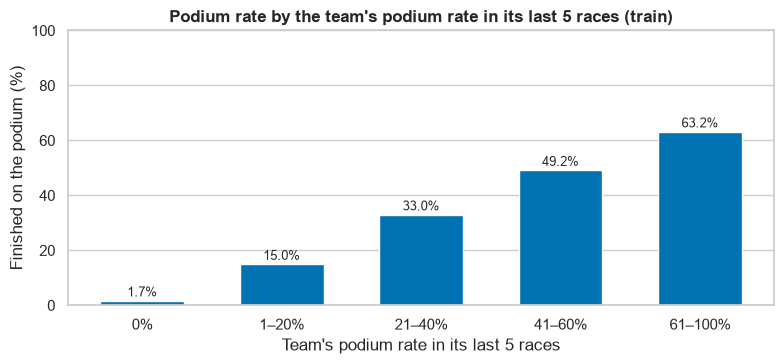

In [70]:
# ── 10.7 Team form · ACT + evidence + VERIFY ────────────────────────────────────
# (1) One row per team per race: share of its cars on the podium, and its best finish.
team_race = (fe.loc[~fe["exclude_from_model"]]
             .groupby(["constructorId", "raceId", "date"], as_index=False)
             .agg(cars=("driverId", "size"), podiums=("podium", "sum"), best_finish=("positionOrder", "min")))
team_race["podium_share"] = team_race["podiums"] / team_race["cars"]
team_race = team_race.sort_values(["constructorId", "date"]).reset_index(drop=True)
gt = team_race.groupby("constructorId")
team_race["rate_after"] = gt["podium_share"].transform(lambda s: s.rolling(5, min_periods=1).mean())
team_race["best_after"] = gt["best_finish"].transform(lambda s: s.astype(float).rolling(5, min_periods=1).mean())

# (2) For every driver row, the team's form after its most recent race strictly BEFORE this one.
order = fe.sort_values("date").index
prior_t = pd.merge_asof(fe.loc[order, ["constructorId", "date"]].reset_index(),
                        team_race[["constructorId", "date", "rate_after", "best_after"]].sort_values("date"),
                        on="date", by="constructorId", direction="backward",
                        allow_exact_matches=False).set_index("index")
fe["team_podium_rate_last5"] = prior_t["rate_after"].reindex(fe.index)
fe["team_avg_best_finish_last5"] = prior_t["best_after"].reindex(fe.index)
FEATURE_COLS += ["team_podium_rate_last5", "team_avg_best_finish_last5"]
check_grain(fe, "10.7 team form (merge_asof on earlier team races)",
            unmatched=int(fe["team_podium_rate_last5"].isna().sum()))

# VERIFY 1: both drivers of a team in the same race get identical values.
differ = fe.groupby(["raceId", "constructorId"])[["team_podium_rate_last5", "team_avg_best_finish_last5"]].nunique(dropna=False)
assert (differ <= 1).all().all(), "teammates got different team-form values"
# VERIFY 2: same values as "shift by one team-race, then roll over 5", computed a second way.
team_race["rate_before_check"] = gt["podium_share"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
chk = fe.loc[~fe["exclude_from_model"], ["constructorId", "raceId", "team_podium_rate_last5"]].merge(
    team_race[["constructorId", "raceId", "rate_before_check"]], on=["constructorId", "raceId"])
assert np.allclose(chk["team_podium_rate_last5"].fillna(-1), chk["rate_before_check"].fillna(-1)), "team form mismatch"

# VERIFY 3 (spot check): Red Bull 2013, rounds 6–11, against the team's 5 races before each.
rbr_id = int(fe.loc[fe["constructor"].eq("Red Bull") & fe["year"].eq(2013), "constructorId"].iloc[0])
rbr = (fe[fe["constructorId"].eq(rbr_id) & fe["year"].eq(2013)].groupby(["round", "race", "date"], as_index=False)
       .agg(team_podium_rate_last5=("team_podium_rate_last5", "first"), podiums_this_race=("podium", "sum"))
       .sort_values("date").iloc[5:11])
rbr_hist = team_race[team_race["constructorId"].eq(rbr_id)]
rbr["manual_rate_of_previous_5"] = [rbr_hist[rbr_hist["date"] < d].tail(5)["podium_share"].mean() for d in rbr["date"]]
display(rbr.drop(columns="date"))
assert np.allclose(rbr["team_podium_rate_last5"], rbr["manual_rate_of_previous_5"])
new_team = fe[fe["team_podium_rate_last5"].isna()]
print(f"Rows of a team's first race (no team history): {len(new_team):,}, {int(new_team['split'].eq('train').sum())} in train.")

# Evidence (train): podium rate by the team's recent form.
tr = fe[fe["split"].eq("train") & ~fe["exclude_from_model"] & fe["team_podium_rate_last5"].notna()]
bucket = pd.cut(tr["team_podium_rate_last5"], [-0.01, 0, 0.2, 0.4, 0.6, 1], labels=["0%", "1–20%", "21–40%", "41–60%", "61–100%"])
ev = tr.groupby(bucket, observed=True)["podium"].agg(rows="size", podium_rate="mean")
ev["podium_rate"] = (100 * ev["podium_rate"]).round(1)
display(ev.T)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(ev.index.astype(str), ev["podium_rate"], color=sns.color_palette("colorblind")[0], width=0.6)
for x, v in enumerate(ev["podium_rate"]):
    ax.annotate(f"{v:.1f}%", (x, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.set(title="Podium rate by the team's podium rate in its last 5 races (train)",
       xlabel="Team's podium rate in its last 5 races", ylabel="Finished on the podium (%)", ylim=(0, 100))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**What we found**
- **Team form matters.** When the team had no podium in its last 5 races, its drivers reached the podium only **2%** of the time. With a team podium rate of 61–100%, it was **63%**.
- **Red Bull 2013 check:** each value equals the team's average over its 5 races **before** that race. Their 2 podiums in Monaco only show up from the next race on. ✅
- Both drivers of a team always get **the same values**, and a second way of computing them gives the same numbers for every row. ✅
- **264** rows are a team's first race (35 in train): a new team, or a renamed team, which gets a new ID. They stay empty and are filled in 10.11.

**Why it's allowed:** only the team's earlier races are used, and both cars are combined per race first, so a teammate's result from this same race can never get in.

### 10.8 Context (optional)

Facts about the race and the driver that are known long before the start:
- `year`: the season, as a number (lets a model notice slow changes over time)
- `circuitId`: the track, as a **category**, not a number (track 14 is not "more" than track 6)
- `driver_age`: the driver's age on race day, from his date of birth and the race date

These are optional. The quick checks below show whether they carry any signal; the ablation in Section 11 measures what they really add.

[grain ok] 10.8 context (no join): 24,730 rows, one per (raceId, driverId)


driver_age,<23,23–26,26–29,29–32,32–35,35+
rows,1013,1555,1554,1207,746,730
podium_rate,8.2,11.6,13.4,21.0,19.6,11.9


Podium rate per train season: min 12.5%, max 15.2% (it only follows the number of cars).
Circuits in train: 31.
Tracks raced in 2016–2019 but never in 2003–2015: 2 ['Baku City Circuit', 'Circuit Paul Ricard']
Podium rate per circuit in train ranges from 12.8% to 15.0% (it follows field size, not the track itself).


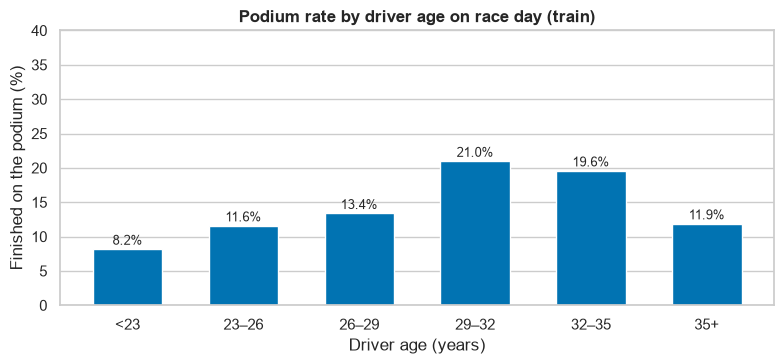

In [71]:
# ── 10.8 Context · ACT + quick evidence ─────────────────────────────────────────
fe["driver_age"] = (fe["date"] - fe["dob"]).dt.days / 365.25
# year and circuitId already exist in fe (from base); circuitId is a category, so it is listed separately.
CATEGORICAL_FEATURES = ["circuitId"]
FEATURE_COLS += ["year", "circuitId", "driver_age"]
check_grain(fe, "10.8 context (no join)")
assert fe.loc[fe["year"] >= 2003, "driver_age"].between(17, 45).all(), "implausible driver age from 2003"

tr = fe[fe["split"].eq("train") & ~fe["exclude_from_model"]]
# Driver age: podium rate by age group (train).
age_group = pd.cut(tr["driver_age"], [0, 23, 26, 29, 32, 35, 50], labels=["<23", "23–26", "26–29", "29–32", "32–35", "35+"])
age_ev = tr.groupby(age_group, observed=True)["podium"].agg(rows="size", podium_rate="mean")
age_ev["podium_rate"] = (100 * age_ev["podium_rate"]).round(1)
display(age_ev.T)
# Year: podium rate per season (train) - expected to be flat, since every race has exactly 3 podium places.
year_ev = (100 * tr.groupby("year")["podium"].mean()).round(1)
print(f"Podium rate per train season: min {year_ev.min()}%, max {year_ev.max()}% (it only follows the number of cars).")
# Circuits: how many tracks the training seasons cover, and whether the track alone relates to a podium.
print(f"Circuits in train: {tr['circuitId'].nunique()}.")
# Evidence for the unknown-track rule, inside train: tracks in 2016–2019 that 2003–2015 never had.
early_tracks = set(tr.loc[tr["year"] < 2016, "circuit"])
new_late = sorted(set(tr.loc[tr["year"] >= 2016, "circuit"]) - early_tracks)
print(f"Tracks raced in 2016–2019 but never in 2003–2015: {len(new_late)} {new_late}")
circ_ev = (tr.groupby("circuit")["podium"].agg(rows="size", podium_rate="mean"))
print(f"Podium rate per circuit in train ranges from {100 * circ_ev['podium_rate'].min():.1f}% to "
      f"{100 * circ_ev['podium_rate'].max():.1f}% (it follows field size, not the track itself).")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(age_ev.index.astype(str), age_ev["podium_rate"], color=sns.color_palette("colorblind")[0], width=0.6)
for x, v in enumerate(age_ev["podium_rate"]):
    ax.annotate(f"{v:.1f}%", (x, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.set(title="Podium rate by driver age on race day (train)", xlabel="Driver age (years)",
       ylabel="Finished on the podium (%)", ylim=(0, 40))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**What we found**
- **Age carries a signal:** drivers aged 29–32 reached the podium **21%** of the time, under 23 only **8%**.
- **Year alone says little:** the podium rate per season only moves between **12.5% and 15.2%**, because it simply follows the number of cars.
- **Circuit alone says nothing either:** every track has 3 podium places, so its podium rate ranges only from **12.8% to 15.0%**. A circuit can only help in combination with other features (Q1 showed that a front-row start converts better at some tracks than others).
- **New tracks keep appearing, even inside training:** of the 31 training tracks, **2** were raced in 2016–2019 but never in 2003–2015 (**Baku City Circuit** and **Circuit Paul Ricard**). So a later race can be held at a track the model never saw, and the pipeline must handle an unknown track.

**Decision:** keep all three as the optional **context** group. `circuitId` is one-hot encoded with "unknown track → all zeros" in 10.11. The ablation in Section 11 shows whether the group earns its place.

**Why it's allowed:** the season, the track and the driver's birthday are known long before the race.

### 10.9 Feature selection check

Two questions, on training seasons only:
1. **Which features say almost the same thing?** Two features that move together nearly perfectly add little to each other. We use a rank correlation (Spearman), which suits positions like 1st, 2nd, 3rd.
2. **How strongly is each feature linked to a podium?** Its correlation with `podium`.

The rule for redundant pairs is fixed before looking: |correlation| ≥ 0.95 → keep only the one more linked to the podium; 0.90–0.95 → keep both and let the Section 11 ablation decide; below 0.90 → keep both.

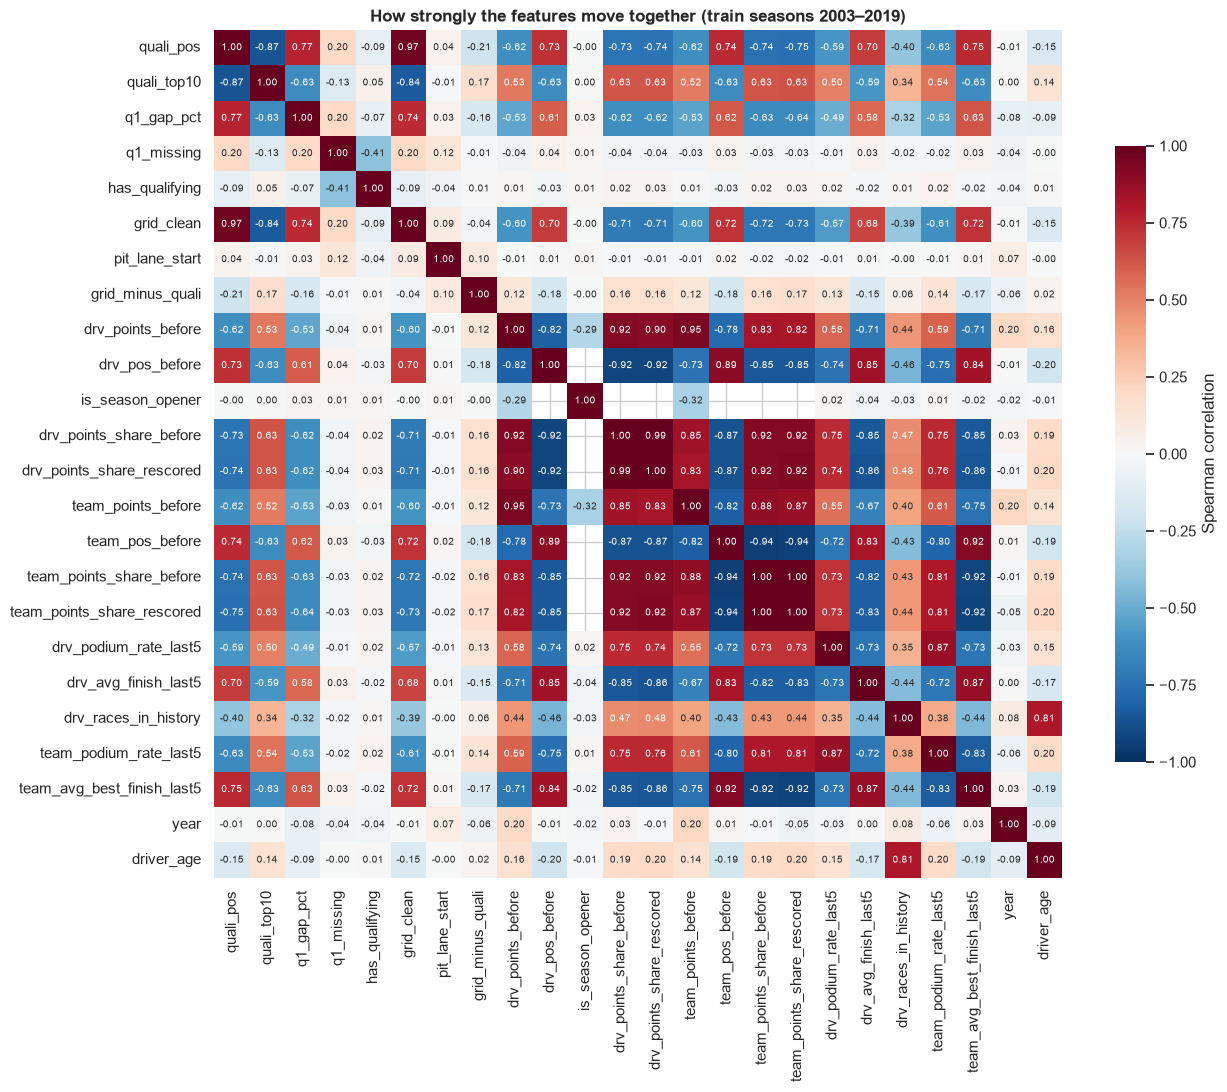

,drv_podium_rate_last5,team_podium_rate_last5,quali_pos,grid_clean,team_points_share_rescored,team_points_share_before,team_pos_before,drv_points_share_rescored,drv_points_share_before,drv_pos_before,team_avg_best_finish_last5,drv_avg_finish_last5,q1_gap_pct,quali_top10,drv_points_before,team_points_before,drv_races_in_history,driver_age,grid_minus_quali,q1_missing,pit_lane_start,has_qualifying,year,is_season_opener
corr_with_podium,0.527,0.515,-0.497,-0.494,0.479,0.478,-0.475,0.474,0.474,-0.473,-0.469,-0.443,-0.398,0.392,0.371,0.363,0.229,0.09,0.085,-0.036,-0.024,0.023,0.002,0.001


Pairs with |Spearman| >= 0.90: 17


,feature_a,feature_b,spearman,podium_corr_a,podium_corr_b,rule
0,team_points_share_before,team_points_share_rescored,0.995,0.478,0.479,drop team_points_share_before (keep team_points_share_re...
1,drv_points_share_before,drv_points_share_rescored,0.993,0.474,0.474,drop drv_points_share_rescored (keep drv_points_share_be...
2,quali_pos,grid_clean,0.969,-0.497,-0.494,drop grid_clean (keep quali_pos)
3,drv_points_before,team_points_before,0.945,0.371,0.363,keep both; ablation decides
4,team_pos_before,team_points_share_before,-0.939,-0.475,0.478,keep both; ablation decides
5,team_pos_before,team_points_share_rescored,-0.937,-0.475,0.479,keep both; ablation decides
6,drv_points_share_rescored,team_points_share_rescored,0.923,0.474,0.479,keep both; ablation decides
7,team_points_share_rescored,team_avg_best_finish_last5,-0.923,0.479,-0.469,keep both; ablation decides
8,drv_points_share_before,team_points_share_before,0.921,0.474,0.478,keep both; ablation decides
9,drv_points_share_rescored,team_points_share_before,0.920,0.474,0.478,keep both; ablation decides


In [72]:
# ── 10.9 Feature selection · SEE: redundancy and link to the podium (train seasons only) ─
tr = fe[fe["split"].eq("train") & ~fe["exclude_from_model"]]
numeric_features = [c for c in FEATURE_COLS if c not in CATEGORICAL_FEATURES]
corr = tr[numeric_features].astype(float).corr(method="spearman")

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 7},
            square=True, cbar_kws={"label": "Spearman correlation", "shrink": 0.7}, ax=ax)
ax.set_title("How strongly the features move together (train seasons 2003–2019)")
plt.tight_layout()
plt.show()

# Link to the podium: Spearman correlation of each feature with the target (train).
link = (tr[numeric_features].astype(float).corrwith(tr["podium"].astype(float), method="spearman")
        .rename("corr_with_podium").to_frame())
link["abs"] = link["corr_with_podium"].abs()
link = link.sort_values("abs", ascending=False).drop(columns="abs").round(3)
display(link.T)

# Redundant pairs and the fixed rule.
pairs = []
for i, a in enumerate(numeric_features):
    for b in numeric_features[i + 1:]:
        r = corr.loc[a, b]
        if abs(r) >= 0.90:
            stronger = a if abs(link.loc[a, "corr_with_podium"]) >= abs(link.loc[b, "corr_with_podium"]) else b
            weaker = b if stronger == a else a
            rule = (f"drop {weaker} (keep {stronger})" if abs(r) >= 0.95 else "keep both; ablation decides")
            pairs.append({"feature_a": a, "feature_b": b, "spearman": round(r, 3),
                          "podium_corr_a": link.loc[a, "corr_with_podium"], "podium_corr_b": link.loc[b, "corr_with_podium"],
                          "rule": rule})
pairs = pd.DataFrame(pairs).sort_values("spearman", key=abs, ascending=False, ignore_index=True)
print(f"Pairs with |Spearman| >= 0.90: {len(pairs)}")
with pd.option_context("display.max_colwidth", 60):
    display(pairs)

**What we found**
- **Strongest links to a podium:** recent driver form (**0.53**), recent team form (**0.52**), qualifying position (**−0.50**: a lower number is better), grid (**−0.49**) and the points shares (about **0.47–0.48**).
- **Weak on their own:** `year`, `is_season_opener`, `has_qualifying`, `pit_lane_start`, `q1_missing` (all under 0.04 in absolute value). Flags like these only matter for a few rows, or in combination with other features.
- **3 pairs are near-copies (≥ 0.95):** the two driver shares (**0.993**), the two team shares (**0.995**), and `quali_pos` vs `grid_clean` (**0.969**).
- **14 more pairs are 0.90–0.95**, all inside the standings group (points, positions and shares of drivers and teams). These are kept, and the ablation decides.
- Blank cells in the heatmap: `is_season_opener` against the standings features, which are empty at season openers, so no correlation can be computed there.

**Why it's allowed:** this only measures features on training seasons. Nothing from validation or test is used.

### Decision: drop three near-copies

- **Tie-break rule (added after seeing that the two share versions are tied):** if two near-copies differ in their link to the podium by less than 0.01, keep the **official** version. It is simpler, and it is the real championship.
- **Drop `drv_points_share_rescored`** (0.993 with the official share, podium link 0.474 vs 0.474) and **`team_points_share_rescored`** (0.995, 0.479 vs 0.478). Re-scoring added nothing.
- **Drop `grid_clean`** (0.969 with `quali_pos`). `quali_pos + grid_minus_quali` rebuilds it exactly, so no grid information is lost, penalties included.
- **Move raw points (`drv_points_before`, `team_points_before`) out of the features.** Their meaning changes with the era, already inside the training seasons: the leader had a median of 64 points before a race in 2003–2009 against 174.5 in 2010–2019 (teams: 106 vs 311). The shares carry the same information without that problem, and are more linked to the podium (0.47 vs 0.37 for drivers, 0.48 vs 0.36 for teams). Decided from training seasons only.
- **Keep both features of every 0.90–0.95 pair.** The Section 11 ablation decides.

The dropped columns stay in `fe` as helper columns; they just never reach a model.

In [73]:
# ── 10.9 Feature selection · ACT: drop the near-copies (they stay in fe as helper columns) ─
DROPPED_REDUNDANT = ["drv_points_share_rescored", "team_points_share_rescored", "grid_clean"]
DROPPED_RAW_POINTS = ["drv_points_before", "team_points_before"]   # era-dependent scale; the shares replace them
assert np.allclose(fe["grid_clean"], fe["quali_pos"] + fe["grid_minus_quali"]), "grid_clean is not rebuilt exactly"
FEATURE_COLS = [c for c in FEATURE_COLS if c not in DROPPED_REDUNDANT + DROPPED_RAW_POINTS]
HELPER_COLS += DROPPED_REDUNDANT + DROPPED_RAW_POINTS
assert not set(FEATURE_COLS) & set(HELPER_COLS), "a column is both a feature and a helper"
check_grain(fe, "10.9 after dropping near-copies (no join)")
print(f"Moved to helper columns: {DROPPED_REDUNDANT + DROPPED_RAW_POINTS}; {len(FEATURE_COLS)} features remain.")
group_of = {"quali_pos": "qualifying", "quali_top10": "qualifying", "q1_gap_pct": "qualifying", "q1_missing": "qualifying",
            "has_qualifying": "qualifying", "pit_lane_start": "grid", "grid_minus_quali": "grid",
            "drv_pos_before": "driver standings", "drv_points_share_before": "driver standings",
            "is_season_opener": "driver standings", "team_pos_before": "team standings",
            "team_points_share_before": "team standings", "drv_podium_rate_last5": "driver form",
            "drv_avg_finish_last5": "driver form", "drv_races_in_history": "driver form",
            "team_podium_rate_last5": "team form", "team_avg_best_finish_last5": "team form",
            "year": "context", "circuitId": "context", "driver_age": "context"}
assert set(group_of) == set(FEATURE_COLS), "a feature has no group"
for grp, cols in pd.Series(group_of).groupby(pd.Series(group_of), sort=False):
    print(f"  {grp:<17} {list(cols.index)}")

[grain ok] 10.9 after dropping near-copies (no join): 24,730 rows, one per (raceId, driverId)
Moved to helper columns: ['drv_points_share_rescored', 'team_points_share_rescored', 'grid_clean', 'drv_points_before', 'team_points_before']; 20 features remain.
  qualifying        ['quali_pos', 'quali_top10', 'q1_gap_pct', 'q1_missing', 'has_qualifying']
  grid              ['pit_lane_start', 'grid_minus_quali']
  driver standings  ['drv_pos_before', 'drv_points_share_before', 'is_season_opener']
  team standings    ['team_pos_before', 'team_points_share_before']
  driver form       ['drv_podium_rate_last5', 'drv_avg_finish_last5', 'drv_races_in_history']
  team form         ['team_podium_rate_last5', 'team_avg_best_finish_last5']
  context           ['year', 'circuitId', 'driver_age']


### 10.10 The modelling table

One table with everything a model needs, and nothing else:
- **keys:** `raceId`, `driverId`, `year`, `split`
- **row filter:** `exclude_from_model` (drops the 2005 US GP from training only; never a feature)
- **target:** `podium`
- **features:** the 20 columns in `FEATURE_COLS`, grouped in `FEATURE_GROUPS` for the ablation in Section 11

We also list every missing value per feature and split, with how it will be filled, and check that no outcome column or flag is among the features.

In [74]:
# ── 10.10 Modelling table · ACT + VERIFY ────────────────────────────────────────
FEATURE_GROUPS = {
    "qualifying": ["quali_pos", "quali_top10", "q1_gap_pct", "q1_missing", "has_qualifying"],
    "grid": ["pit_lane_start", "grid_minus_quali"],
    "driver_standings": ["drv_pos_before", "drv_points_share_before", "is_season_opener"],
    "team_standings": ["team_pos_before", "team_points_share_before"],
    "driver_form": ["drv_podium_rate_last5", "drv_avg_finish_last5", "drv_races_in_history"],
    "team_form": ["team_podium_rate_last5", "team_avg_best_finish_last5"],
    "context": ["year", "circuitId", "driver_age"],
}
KEY_COLS, TARGET = ["raceId", "driverId", "year", "split"], "podium"
model_table = fe[["raceId", "driverId", "split", "exclude_from_model", TARGET]
                 + FEATURE_COLS].copy()            # year is both a key and a context feature
model_table[TARGET] = model_table[TARGET].astype(int)

# VERIFY: grain, groups, and that nothing from the race or the flags is a feature.
grouped = [c for cols in FEATURE_GROUPS.values() for c in cols]
assert sorted(grouped) == sorted(FEATURE_COLS) and len(grouped) == len(set(grouped)), "groups do not match FEATURE_COLS"
FORBIDDEN = set(POST_RACE_COLS) | set(DOC_FLAGS) | {"standings_excluded"} | set(HELPER_COLS)
assert not set(FEATURE_COLS) & FORBIDDEN, f"forbidden column among features: {set(FEATURE_COLS) & FORBIDDEN}"
assert len(model_table) == N_ROWS == 24_730 and not model_table.duplicated(["raceId", "driverId"]).any()
check_grain(model_table, "10.10 model_table")
print(f"model_table: {len(model_table):,} rows × {model_table.shape[1]} columns "
      f"({len(KEY_COLS) - 1} keys + split, 1 row filter, 1 target, {len(FEATURE_COLS)} features in {len(FEATURE_GROUPS)} groups).")

# Missing values per feature and split, with the planned fill.
PLANNED_FILL = {
    "drv_pos_before": "train median + indicator (10.11): season opener",
    "drv_points_share_before": "train median + indicator (10.11): season opener",
    "team_pos_before": "train median + indicator (10.11): season opener",
    "team_points_share_before": "train median + indicator (10.11): season opener",
    "drv_podium_rate_last5": "train median + indicator (10.11): driver's first race",
    "drv_avg_finish_last5": "train median + indicator (10.11): driver's first race",
    "team_podium_rate_last5": "train median + indicator (10.11): team's first race",
    "team_avg_best_finish_last5": "train median + indicator (10.11): team's first race",
}
missing = (model_table.groupby("split")[FEATURE_COLS].apply(lambda d: d.isna().sum()).T[SPLIT_ORDER])
missing = missing[(missing[["train", "validation", "test"]] > 0).any(axis=1)]
missing["train_%"] = (100 * missing["train"] / (model_table["split"] == "train").sum()).round(1)
missing["planned_fill"] = missing.index.map(PLANNED_FILL).fillna("—")
print("Features with missing values in train, validation or test:")
display(missing)
no_gap = [c for c in FEATURE_COLS if c not in missing.index]
print(f"Complete in train, validation and test: {len(no_gap)} features.")

[grain ok] 10.10 model_table: 24,730 rows, one per (raceId, driverId)
model_table: 24,730 rows × 25 columns (3 keys + split, 1 row filter, 1 target, 20 features in 7 groups).
Features with missing values in train, validation or test:


split,history,train,validation,test,train_%,planned_fill
drv_pos_before,1153,358,40,60,5.2,train median + indicator (10.11): season opener
drv_points_share_before,1153,358,40,60,5.2,train median + indicator (10.11): season opener
team_pos_before,1153,358,40,60,5.2,train median + indicator (10.11): season opener
team_points_share_before,2171,358,40,60,5.2,train median + indicator (10.11): season opener
drv_podium_rate_last5,599,75,6,8,1.1,train median + indicator (10.11): driver's first race
drv_avg_finish_last5,599,75,6,8,1.1,train median + indicator (10.11): driver's first race
team_podium_rate_last5,223,35,4,2,0.5,train median + indicator (10.11): team's first race
team_avg_best_finish_last5,223,35,4,2,0.5,train median + indicator (10.11): team's first race


Complete in train, validation and test: 12 features.


**What we found**
- The modelling table has **24,730 rows** (one per driver per race) and **25 columns**: the keys and split, the row filter, the target `podium`, and **20 features** in 7 groups.
- **No forbidden column is a feature:** none of the race results, flags, `standings_excluded` or helper columns. Checked in code. ✅
- **12 features are complete** in train, validation and test.
- **8 features have gaps, all for a known reason:**
  - standings (4 features): **358** train rows (**5.2%**), the season openers
  - driver form (2): **75** train rows (**1.1%**), a driver's first race
  - team form (2): **35** train rows (**0.5%**), a team's first race
- All of these are filled in 10.11 with the training median plus a "was empty" flag.
- History rows (before 2003) have more gaps (e.g. no team championship before 1958), but they are never used for training.

**Why it's allowed:** every feature passed the race-morning test in its own subsection, and this table only collects them.

### 10.11 Pre-processing pipeline

Before a model can learn, every empty value needs a number, numbers need a common scale, and the circuit needs to become yes/no columns. All of this is learned from the **training seasons only** and then applied unchanged to validation and test.

**First, the "was empty" flags.** A filled-in value should be marked, so the model knows it was a guess. We use **one flag per feature group**, not one per feature, because the features of a group are empty in the same rows. A flag is skipped if an existing column already marks exactly those rows. The check below tests this on the training seasons.

In [75]:
# ── 10.11 Pipeline · SEE: which groups need a "was empty" flag? (train seasons) ─
tr = model_table[model_table["split"].eq("train") & ~model_table["exclude_from_model"]]
# For each group with gaps: an existing column that might already mark the same rows.
EXISTING_MARKER = {"driver_standings": ("is_season_opener", tr["is_season_opener"].eq(1)),
                   "team_standings": ("is_season_opener", tr["is_season_opener"].eq(1)),
                   "driver_form": ("drv_races_in_history == 0", tr["drv_races_in_history"].eq(0)),
                   "team_form": (None, None)}
flag_check = []
for group, cols in FEATURE_GROUPS.items():
    gaps = tr[cols].isna()
    if not gaps.any().any():
        continue
    gap_cols = gaps.columns[gaps.any()]
    any_gap = gaps[gap_cols].any(axis=1)
    same_rows_in_group = bool((gaps[gap_cols].all(axis=1) == any_gap).all())   # the features with gaps are empty together?
    marker_name, marker = EXISTING_MARKER[group]
    identical = bool(marker is not None and (marker == any_gap).all())
    flag_check.append({"group": group, "features_with_gaps": ", ".join(gap_cols), "empty_rows": int(any_gap.sum()),
                       "empty_in_same_rows": same_rows_in_group, "existing_marker": marker_name or "—",
                       "marker_rows": int(marker.sum()) if marker is not None else 0, "marker_identical": identical,
                       "flag_needed": not identical})
flag_check = pd.DataFrame(flag_check).set_index("group")
display(flag_check)
GROUP_FLAGS = {g: f"{g}_missing" for g in flag_check.index[flag_check["flag_needed"]]}
print(f"Flags to add (one per group): {list(GROUP_FLAGS.values()) or 'none'}")

,features_with_gaps,empty_rows,empty_in_same_rows,existing_marker,marker_rows,marker_identical,flag_needed
group,,,,,,,
driver_standings,"drv_pos_before, drv_points_share_before",358,True,is_season_opener,358,True,False
team_standings,"team_pos_before, team_points_share_before",358,True,is_season_opener,358,True,False
driver_form,"drv_podium_rate_last5, drv_avg_finish_last5",75,True,drv_races_in_history == 0,75,True,False
team_form,"team_podium_rate_last5, team_avg_best_finish_last5",35,True,—,0,False,True


Flags to add (one per group): ['team_form_missing']


**What we found**
- In every group, the features with gaps are **empty in exactly the same rows**, so one flag per group is enough.
- **Driver and team standings (358 train rows):** the empty rows are exactly the rows with `is_season_opener = 1`. No new flag is needed.
- **Driver form (75 rows):** exactly the rows with `drv_races_in_history = 0` (his first race). No new flag is needed.
- **Team form (35 rows):** no existing column marks a team's first race, so **one new flag, `team_form_missing`**, is added.

**Why it's allowed:** a flag only says "this value was empty before the fill", and every empty value comes from a race-morning fact (season opener, first race of a driver or team).

**ACT: build the pipeline and fit it on the training seasons only**

The pipeline does three things, in this order:
1. **Flag:** add `team_form_missing` (1 if the team-form values are empty).
2. **Numbers:** fill each empty value with the **training median** of that feature, then **scale** every number to mean 0 and spread 1. Scaling is needed for logistic regression and the neural network, which compare features by size.
3. **Circuit:** turn `circuitId` into one yes/no column per training track. A track it has never seen becomes all zeros.

It learns its medians, means and track list from train (2003–2019, without the 2005 US GP), and then applies exactly those to every other row.

Fitted on 6,805 train rows. Output: 51 columns = 20 numeric (incl. 1 flag) + 31 track columns.


,empty_before,median_used_for_fill,range_before,range_after,mean_after,std_after
quali_pos,0,11.000,1.00 to 24.00,-1.63 to 2.05,0.0,1.0
q1_gap_pct,0,1.364,0.00 to 33.29,-0.91 to 15.34,-0.0,1.0
drv_avg_finish_last5,75,11.400,1.00 to 24.00,-2.25 to 2.86,-0.0,1.0


Training medians used for every fill:


,drv_pos_before,drv_points_share_before,team_pos_before,team_points_share_before,drv_podium_rate_last5,drv_avg_finish_last5,team_podium_rate_last5,team_avg_best_finish_last5
train_median,11.0,0.115,6.0,0.144,0.0,11.4,0.0,8.6


Why a 0 median is fine for the podium rates: 68.0% of train rows with a form value have 0 podiums in their last 5 races; drivers in their first race (75 rows) reached the podium 2.7% of the time.


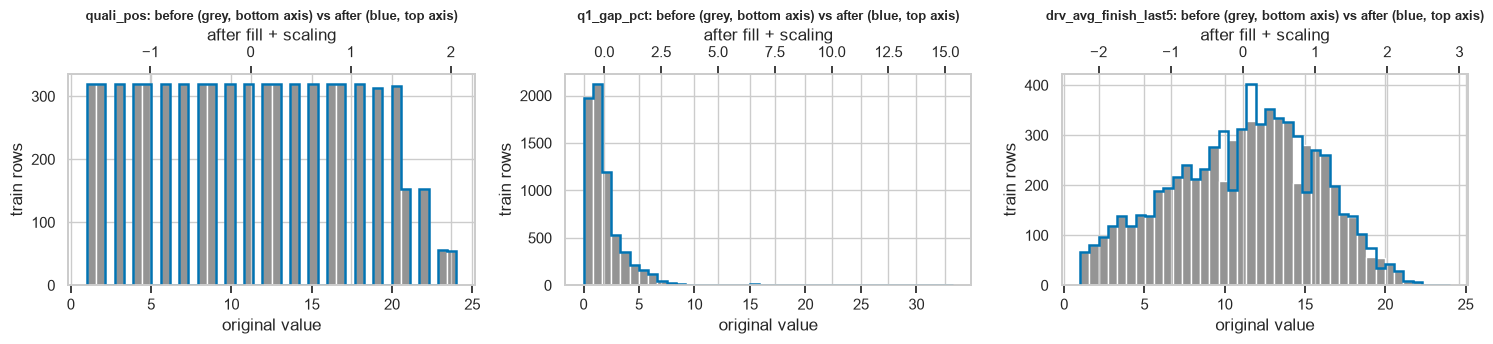

In [76]:
# ── 10.11 Pipeline · ACT: flags → median fill → scale; circuit → one-hot; fit on TRAIN only ─
NUMERIC_FEATURES = [c for c in FEATURE_COLS if c not in CATEGORICAL_FEATURES] + list(GROUP_FLAGS.values())


def add_group_flags(X: pd.DataFrame) -> pd.DataFrame:
    """One "was empty" flag per group that has no existing marker (decided in the check above)."""
    X = X.copy()
    for group, flag in GROUP_FLAGS.items():
        X[flag] = X[FEATURE_GROUPS[group]].isna().any(axis=1).astype(float)
    return X


def make_preprocessor(features: list[str] | None = None) -> Pipeline:
    """A fresh, unfitted pre-processing pipeline for `features` (default: FEATURE_COLS)."""
    features = FEATURE_COLS if features is None else features
    numeric = [c for c in features if c not in CATEGORICAL_FEATURES] + list(GROUP_FLAGS.values())
    categorical = [c for c in features if c in CATEGORICAL_FEATURES]
    flags = FunctionTransformer(add_group_flags, feature_names_out=lambda _, names: list(names) + list(GROUP_FLAGS.values()))
    columns = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value=-1)),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), categorical),
    ], verbose_feature_names_out=False)
    return Pipeline([("flags", flags), ("columns", columns)]).set_output(transform="pandas")


def features_of(df: pd.DataFrame, features: list[str] | None = None) -> pd.DataFrame:
    """The only way rows reach a model: exactly FEATURE_COLS (or `features`), as floats (NA becomes NaN)."""
    return df[FEATURE_COLS if features is None else features].astype(float)


fit_rows = model_table[model_table["split"].eq("train") & ~model_table["exclude_from_model"]]
preprocessor = make_preprocessor().fit(features_of(fit_rows))
X_train = preprocessor.transform(features_of(fit_rows))
n_tracks = len(preprocessor.named_steps["columns"].named_transformers_["cat"].named_steps["onehot"].categories_[0])
print(f"Fitted on {len(fit_rows):,} train rows. Output: {X_train.shape[1]} columns = {len(NUMERIC_FEATURES)} numeric "
      f"(incl. {len(GROUP_FLAGS)} flag) + {n_tracks} track columns.")
assert not X_train.isna().any().any(), "a value is still empty after the pipeline"
num_out = X_train[NUMERIC_FEATURES]
assert np.allclose(num_out.mean(), 0, atol=1e-9) and np.allclose(num_out.std(ddof=0), 1, atol=1e-6), "train not standardised"

# VERIFY: what the fill and the scaling did to 3 features (train).
medians = pd.Series(preprocessor.named_steps["columns"].named_transformers_["num"].named_steps["impute"].statistics_,
                    index=NUMERIC_FEATURES)
show = ["quali_pos", "q1_gap_pct", "drv_avg_finish_last5"]
before_after = pd.DataFrame({
    "empty_before": features_of(fit_rows)[show].isna().sum(),
    "median_used_for_fill": medians[show].round(3),
    "range_before": [f"{features_of(fit_rows)[c].min():.2f} to {features_of(fit_rows)[c].max():.2f}" for c in show],
    "range_after": [f"{X_train[c].min():.2f} to {X_train[c].max():.2f}" for c in show],
    "mean_after": X_train[show].mean().round(3), "std_after": X_train[show].std(ddof=0).round(3),
})
display(before_after)
print("Training medians used for every fill:")
filled = [c for c in FEATURE_COLS if c in medians.index and features_of(fit_rows)[c].isna().any()]
display(medians[filled].round(3).to_frame("train_median").T)
rookies = fit_rows[fit_rows["drv_races_in_history"].eq(0)]
print(f"Why a 0 median is fine for the podium rates: {100 * (features_of(fit_rows)['drv_podium_rate_last5'] == 0).mean():.1f}% "
      f"of train rows with a form value have 0 podiums in their last 5 races; drivers in their first race "
      f"({len(rookies)} rows) reached the podium {100 * rookies['podium'].mean():.1f}% of the time.")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col in zip(axes, show):
    ax.hist(features_of(fit_rows)[col].dropna(), bins=40, color=sns.color_palette("colorblind")[7])
    ax2 = ax.twiny()
    ax2.hist(X_train[col], bins=40, histtype="step", linewidth=1.8, color=sns.color_palette("colorblind")[0])
    ax.set(title=f"{col}: before (grey, bottom axis) vs after (blue, top axis)", xlabel="original value", ylabel="train rows")
    ax2.set_xlabel("after fill + scaling")
    ax.title.set_fontsize(9)
plt.tight_layout()
plt.show()

**What we found**
- The pipeline turns the 20 features into **51 columns**: 19 numbers + 1 flag (`team_form_missing`) + 31 track columns (one per training track).
- After it, **no value is empty**, and every number has mean **0** and spread **1** on train (checked in code). ✅
- **The fills use training medians,** for example average finish **11.4**, driver position **11th**, team position **6th**.
- **Two medians are 0:** the driver and team podium rates. We keep the median, for three reasons:
  - 0 is a real, common value: **68%** of train rows have no podium in their last 5 races.
  - Rookies rarely reach the podium: drivers in their first race did it only **2.7%** of the time (75 rows).
  - The filled rows are already marked: `drv_races_in_history = 0` for a driver's first race, `team_form_missing = 1` for a team's first race.
- **Before vs after** (plots): the shapes stay the same, only the axis changes. `drv_avg_finish_last5` gets a small extra bump at 11.4, the 75 filled rows. `q1_gap_pct` keeps its long tail (up to **15.3** after scaling), as decided in 10.2.

**Why it's allowed:** every median, mean and track list is learned from training seasons only, and the same values are then applied to validation and test.

**VERIFY: a record with missing features**

The inference function (a deliverable) must work on a partially-missing record. We take one real 2019 row (a training season), empty 3 of its features, give it a track the pipeline has never seen, and run both versions through the fitted pipeline.

In [77]:
# ── 10.11 Pipeline · VERIFY: it accepts a record with missing features and an unknown track ─
# One real 2019 row (training season), then a copy with 3 features emptied and a track id the pipeline never saw.
demo_rows = model_table[model_table["year"].eq(2019) & ~model_table["exclude_from_model"]]
complete = demo_rows[features_of(demo_rows).notna().all(axis=1)].iloc[[0]]          # first row with every feature present
partial = complete.copy()
partial[["quali_pos", "team_pos_before", "drv_avg_finish_last5"]] = np.nan
partial["circuitId"] = 9999                                   # a brand-new track
both = pd.concat([complete, partial], ignore_index=True)
out = preprocessor.transform(features_of(both))

show_in = ["quali_pos", "team_pos_before", "drv_avg_finish_last5", "circuitId"]
track_cols = [c for c in out.columns if c.startswith("circuitId_")]
side_by_side = pd.DataFrame({
    "complete: input": features_of(both).iloc[0][show_in], "complete: after": out.iloc[0][show_in[:3]],
    "partial: input": features_of(both).iloc[1][show_in], "partial: after": out.iloc[1][show_in[:3]],
})
side_by_side.loc["track columns set to 1"] = [None, int(out.iloc[0][track_cols].sum()), None, int(out.iloc[1][track_cols].sum())]
display(side_by_side)
assert not out.isna().any().any() and out.shape[1] == X_train.shape[1], "the pipeline failed on a partial record"
print(f"Partial record: no error, no empty value, same {out.shape[1]} columns. Its 3 empty features got the train "
      f"medians ({', '.join(f'{c} = {medians[c]:g}' for c in ['quali_pos', 'team_pos_before', 'drv_avg_finish_last5'])}), "
      f"and the unknown track set all {len(track_cols)} track columns to 0.")

,complete: input,complete: after,partial: input,partial: after
circuitId,3.0,NaN,9999.0,NaN
drv_avg_finish_last5,2.2,-1.986892,NaN,0.060210
quali_pos,3.0,-1.313931,NaN,-0.030575
team_pos_before,1.0,-1.655526,NaN,0.111501
track columns set to 1,NaN,1.000000,NaN,0.000000


Partial record: no error, no empty value, same 51 columns. Its 3 empty features got the train medians (quali_pos = 11, team_pos_before = 6, drv_avg_finish_last5 = 11.4), and the unknown track set all 31 track columns to 0.


**What we found**
- **The complete row** (a 2019 race at the Bahrain International Circuit, the season's second round: qualified 3rd, team 1st, average finish 2.2) goes through normally, and its track column is set to 1.
- **The partial row** (the same row with qualifying position, team position and average finish emptied, plus an unknown track) also goes through with **no error and no empty value**, giving the same 51 columns.
- Its empty features got the **train medians**: qualifying 11th, team 6th, average finish 11.4. The unknown track set **all 31 track columns to 0**.

**Why it matters:** the inference function at the end of the milestone can take a record with gaps, or a race at a new track, and still predict.

### Preprocessing-order experiments (designed here, run in Section 11)

Both experiments use the baseline model from Section 11, are scored on the **validation** seasons (2020–2021) with the same metrics, and **never touch the test set**. They only change how the pipeline above is prepared.

**Experiment 1: fit on train only vs fit on train + validation (a demonstration only)**
- **Correct:** the pipeline learns its medians and scaling from the training seasons only, which is how every real model in this notebook is built.
- **Leaky on purpose:** the same pipeline learns them from train **and** validation, so it has already seen the data it is scored on.
- **Why:** to show, with numbers, why the fit must happen on train only. The leaky version is a demonstration and is **never** used for any reported model.

**Experiment 2: fill then scale vs scale then fill**
- **Fill → scale (our pipeline):** empty values get the training median first, then everything is scaled.
- **Scale → fill:** values are scaled first (ignoring empty ones), then empty values are filled.
- **Why:** to test whether the order of the two steps changes the result. Both versions learn from the training seasons only, so neither leaks.

### 10.12 Extra features from tables not used yet

The brief leaves room for our own feature choices, as long as each one is backed by evidence. So we look for extra pre-race information in tables we have not used yet. Data from the **current** race is never allowed, except qualifying, which is over before the start. Summaries of **earlier** races are allowed.

**Candidates** (all computed from races before this one, unless the race-morning test says otherwise):

| # | Candidate | Source table | How it is computed | Race-morning test |
|---|---|---|---|---|
| C1 | `drv_mech_dnf_rate_last10` | `results` + `status` | share of the driver's last 10 races that ended in a mechanical failure (the Q3 mapping) | earlier races only |
| C2 | `team_mech_dnf_rate_last10` | `results` + `status` | per team per race, the share of its cars with a mechanical failure; then averaged over the team's last 10 races | earlier races only, teammates combined first |
| C3 | `team_pit_median_last5` | `pit_stops` | the team's median pit-stop time over its last 5 races | earlier races only |
| C4 | `drv_pace_gap_last5` | `lap_times` | per race, the driver's median lap time vs the fastest driver's median lap (in %); averaged over his last 5 races | earlier races only |
| C5 | `drv_circuit_podium_rate` | `results` | the driver's podium rate at this circuit in his earlier visits | earlier visits only |
| C6 | `drv_quali_avg_last5` | `qualifying` | the driver's average qualifying position over his last 5 races | earlier races only |
| C7 | `teammate_quali_gap` | `qualifying` | this race: the driver's qualifying position minus his teammate's | qualifying is over before the race |
| C8 | `sprint_pos_this_weekend` | `sprint_results` | the driver's finishing position in this weekend's sprint | the sprint runs before the main race |

**Fixed decision rules (written before any test, so the results cannot bend them)**

A candidate is **kept only if it passes all four**:
- **R1 · No leakage:** computed only from earlier races (shift before rolling; team values combined per team per race first), proved by a spot check. Current-race qualifying is allowed.
- **R2 · Enough data:** at least **70%** of **training** rows have a value. A feature the model can hardly see in training cannot be learned.
- **R3 · Not a copy:** absolute Spearman correlation **below 0.9** with every existing feature (training seasons).
- **R4 · Adds value:** inside the training seasons, a fixed baseline (logistic regression, `class_weight="balanced"`, the 10.11 pipeline) is fitted on 2003–2015 with the 20 current features, and once more with the candidate added. Both are scored on 2016–2019 with PR-AUC. The candidate passes only if the **95% interval** of the PR-AUC gain is **above 0**. The interval comes from resampling whole 2016–2019 races (1,000 resamples).

If a candidate fails any rule, it is rejected, and the failed rule is written down with its number.

This is a **screening test** for choosing features, not the final model comparison (that is Section 11). **Validation and test are never used for any decision here:** R2, R3 and R4 use training seasons only.

**ACT: build the 8 candidates**

Each candidate is added to `fe`. The R1 leakage checks are computed a second way and compared, and coverage is measured on the training seasons only. The race results used here (mechanical failures, podiums, lap times) only ever come from **earlier** races.

In [78]:
# ── 10.12 Candidates · ACT: build C1–C8 on fe, coverage (train only), R1 checks ─
def roll_after(events: pd.DataFrame, by: str, col: str, window: int) -> pd.Series:
    """Rolling mean over the last `window` events INCLUDING the current one (the value known after it)."""
    events = events.sort_values([by, "date"])
    return events.groupby(by)[col].transform(lambda s: s.rolling(window, min_periods=1).mean())


def prior_value(events: pd.DataFrame, by: str, col: str) -> pd.Series:
    """For every fe row: the value after the latest event of the same `by` strictly BEFORE this race's date."""
    order = fe.sort_values("date").index
    m = pd.merge_asof(fe.loc[order, [by, "date"]].reset_index(), events[[by, "date", col]].sort_values("date"),
                      on="date", by=by, direction="backward", allow_exact_matches=False).set_index("index")
    return m[col].reindex(fe.index)


def shift_roll_check(events: pd.DataFrame, by: str, col: str, window: int, feature: str) -> None:
    """R1 second way: shift by one event, then roll; must equal the feature on every event row."""
    ev = events.sort_values([by, "date"]).copy()
    ev["check"] = ev.groupby(by)[col].transform(lambda s: s.shift(1).rolling(window, min_periods=1).mean())
    got = fe[[by, "raceId", feature]].drop_duplicates([by, "raceId"]).merge(ev[[by, "raceId", "check"]], on=[by, "raceId"])
    assert np.allclose(got[feature].fillna(-1), got["check"].fillna(-1)), f"{feature}: uses a non-earlier race"
    print(f"  R1 ok: {feature} equals shift-then-roll on all {len(got):,} event rows")


hist_rows = fe[~fe["exclude_from_model"]]                       # history never includes the 2005 US GP
fe["is_mech_dnf"] = fe["status"].isin(MECHANICAL).astype(float)  # helper: a race RESULT, only used for earlier races

# C1 driver / C2 team mechanical-failure rate over the last 10 races.
ev1 = hist_rows[["driverId", "raceId", "date"]].assign(v=fe.loc[hist_rows.index, "is_mech_dnf"])
ev1["after"] = roll_after(ev1, "driverId", "v", 10)
fe["drv_mech_dnf_rate_last10"] = prior_value(ev1, "driverId", "after")
ev2 = (hist_rows.assign(v=fe["is_mech_dnf"]).groupby(["constructorId", "raceId", "date"], as_index=False)["v"].mean())
ev2["after"] = roll_after(ev2, "constructorId", "v", 10)
fe["team_mech_dnf_rate_last10"] = prior_value(ev2, "constructorId", "after")

# C3 team pit-stop median over the last 5 races (pit_stops joined to the team the driver raced for).
pits = clean["pit_stops"][["raceId", "driverId", "duration"]].merge(
    fe[["raceId", "driverId", "constructorId", "date"]], on=["raceId", "driverId"], how="inner")
ev3 = pits.groupby(["constructorId", "raceId", "date"], as_index=False)["duration"].median().rename(columns={"duration": "v"})
ev3["after"] = roll_after(ev3, "constructorId", "v", 5)
fe["team_pit_median_last5"] = prior_value(ev3, "constructorId", "after")

# C4 driver race pace: median lap vs the race's fastest median lap (%), averaged over his last 5 races.
laps = clean["lap_times"].groupby(["raceId", "driverId"], as_index=False)["time"].median()
laps = laps.merge(fe[["raceId", "driverId", "date", "exclude_from_model"]], on=["raceId", "driverId"], how="inner")
laps["v"] = 100 * (laps["time"] / laps.groupby("raceId")["time"].transform("min") - 1)
ev4 = laps[~laps["exclude_from_model"]].copy()
ev4["after"] = roll_after(ev4, "driverId", "v", 5)
fe["drv_pace_gap_last5"] = prior_value(ev4, "driverId", "after")

# C5 driver podium rate at this circuit, earlier visits only.
srt = fe.sort_values("date")
pod = srt["podium"].astype(float).where(~srt["exclude_from_model"])
earlier_pods = pod.fillna(0).groupby([srt["driverId"], srt["circuitId"]]).cumsum() - pod.fillna(0)
earlier_visits = pod.notna().astype(int).groupby([srt["driverId"], srt["circuitId"]]).cumsum() - pod.notna().astype(int)
fe["drv_circuit_podium_rate"] = (earlier_pods / earlier_visits.where(earlier_visits > 0)).reindex(fe.index)

# C6 driver average qualifying position over the last 5 races (raw positions; no qualifying row = not counted).
ev6 = hist_rows[["driverId", "raceId", "date"]].assign(v=fe.loc[hist_rows.index, "quali_pos_raw"].astype(float))
ev6["after"] = roll_after(ev6, "driverId", "v", 5)
fe["drv_quali_avg_last5"] = prior_value(ev6, "driverId", "after")

# C7 this race: qualifying position minus the teammates' average qualifying position.
tsum = fe.groupby(["raceId", "constructorId"])["quali_pos"].transform("sum")
tcnt = fe.groupby(["raceId", "constructorId"])["quali_pos"].transform("count")
fe["teammate_quali_gap"] = fe["quali_pos"] - ((tsum - fe["quali_pos"]) / (tcnt - 1).where(tcnt > 1))

# C8 this weekend's sprint finishing position.
sprint = clean["sprint_results"][["raceId", "driverId", "positionOrder"]].rename(columns={"positionOrder": "sprint_pos_this_weekend"})
fe = fe.merge(sprint, on=["raceId", "driverId"], how="left", validate="one_to_one")
check_grain(fe, "10.12 candidates (C8 joined from sprint_results)",
            unmatched=int(fe["sprint_pos_this_weekend"].isna().sum()))
CANDIDATES = {"C1": "drv_mech_dnf_rate_last10", "C2": "team_mech_dnf_rate_last10", "C3": "team_pit_median_last5",
              "C4": "drv_pace_gap_last5", "C5": "drv_circuit_podium_rate", "C6": "drv_quali_avg_last5",
              "C7": "teammate_quali_gap", "C8": "sprint_pos_this_weekend"}
HELPER_COLS += ["is_mech_dnf"]

# R1 checks (earlier races only), computed a second way.
print("R1 leakage checks:")
shift_roll_check(ev1, "driverId", "v", 10, "drv_mech_dnf_rate_last10")
shift_roll_check(ev2, "constructorId", "v", 10, "team_mech_dnf_rate_last10")
shift_roll_check(ev3, "constructorId", "v", 5, "team_pit_median_last5")
shift_roll_check(ev4, "driverId", "v", 5, "drv_pace_gap_last5")
shift_roll_check(ev6, "driverId", "v", 5, "drv_quali_avg_last5")
pairs5 = fe[["raceId", "driverId", "circuitId", "date"]].merge(
    fe.loc[~fe["exclude_from_model"], ["driverId", "circuitId", "date", "podium"]], on=["driverId", "circuitId"], suffixes=("", "_e"))
c5_check = pairs5[pairs5["date_e"] < pairs5["date"]].groupby(["raceId", "driverId"])["podium"].mean()
c5_got = fe.set_index(["raceId", "driverId"])["drv_circuit_podium_rate"]
assert np.allclose(c5_got.fillna(-1), c5_check.reindex(c5_got.index).fillna(-1)), "C5 uses a non-earlier visit"
print(f"  R1 ok: drv_circuit_podium_rate equals a self-join on earlier visits for all {len(c5_got):,} rows")
mates = fe.groupby(["raceId", "constructorId"])["teammate_quali_gap"].sum(min_count=2)
assert np.allclose(mates.dropna(), 0), "C7 teammates' gaps do not mirror each other"
print("  R1 ok: teammate_quali_gap uses only this race's qualifying (two teammates' gaps always sum to 0)")
print("  R1 ok: sprint_pos_this_weekend is this weekend's sprint, which runs before the main race")

# Coverage: share of TRAIN rows with a value (validation and test are not used).
train_rows_c = fe[fe["split"].eq("train") & ~fe["exclude_from_model"]]
cov = pd.DataFrame({"candidate": list(CANDIDATES.values()),
                    "train_%": [round(100 * train_rows_c[c].notna().mean(), 1) for c in CANDIDATES.values()]},
                   index=list(CANDIDATES))
display(cov)

[grain ok] 10.12 candidates (C8 joined from sprint_results): 24,730 rows, one per (raceId, driverId); rows without a match: 24,370
R1 leakage checks:
  R1 ok: drv_mech_dnf_rate_last10 equals shift-then-roll on all 24,710 event rows
  R1 ok: team_mech_dnf_rate_last10 equals shift-then-roll on all 12,333 event rows
  R1 ok: team_pit_median_last5 equals shift-then-roll on all 2,962 event rows
  R1 ok: drv_pace_gap_last5 equals shift-then-roll on all 11,035 event rows


  R1 ok: drv_quali_avg_last5 equals shift-then-roll on all 24,710 event rows
  R1 ok: drv_circuit_podium_rate equals a self-join on earlier visits for all 24,730 rows
  R1 ok: teammate_quali_gap uses only this race's qualifying (two teammates' gaps always sum to 0)
  R1 ok: sprint_pos_this_weekend is this weekend's sprint, which runs before the main race


,candidate,train_%
C1,drv_mech_dnf_rate_last10,98.9
C2,team_mech_dnf_rate_last10,99.5
C3,team_pit_median_last5,55.8
C4,drv_pace_gap_last5,98.9
C5,drv_circuit_podium_rate,76.2
C6,drv_quali_avg_last5,98.9
C7,teammate_quali_gap,100.0
C8,sprint_pos_this_weekend,0.0


**What we found**
- **R1 (no leakage): all 8 pass.** The five rolling candidates match a second "shift then roll" calculation on every row. The circuit podium rate matches a direct lookup of earlier visits. The teammate gap uses only this race's qualifying, and the sprint runs before the main race. ✅
- **R2 (at least 70% filled in train):**
  - **C3 pit stops fails:** only **55.8%** of train rows have a value, because pit-stop data starts in 2011.
  - **C8 sprint fails:** **0%** in train, because sprints start in 2021.
  - The other six pass: C1, C2, C4, C6 and C7 are 99–100% filled, and C5 (circuit podium rate) **76.2%**.
- **Limitation of C1/C2:** they use the Question 3 list of mechanical statuses, which was built from 2014–2024. Older failure statuses that are not on that list count as "not mechanical".

**Why it's allowed:** every value comes from earlier races, or from this weekend's qualifying or sprint, both of which happen before the race.

**R3: is a candidate a near-copy of a feature we already have?** For each candidate: its highest Spearman correlation with any of the 20 current features (train seasons), plus an evidence plot of the podium rate across five equal-sized groups of its values.

,candidate,closest_existing,spearman,R3
id,,,,
C1,drv_mech_dnf_rate_last10,drv_avg_finish_last5,0.367,pass
C2,team_mech_dnf_rate_last10,team_points_share_before,-0.390,pass
C3,team_pit_median_last5,year,0.341,pass
C4,drv_pace_gap_last5,drv_avg_finish_last5,0.771,pass
C5,drv_circuit_podium_rate,drv_races_in_history,0.523,pass
C6,drv_quali_avg_last5,team_avg_best_finish_last5,0.868,pass
C7,teammate_quali_gap,quali_pos,0.354,pass
C8,sprint_pos_this_weekend,—,NaN,n/a (no train values)


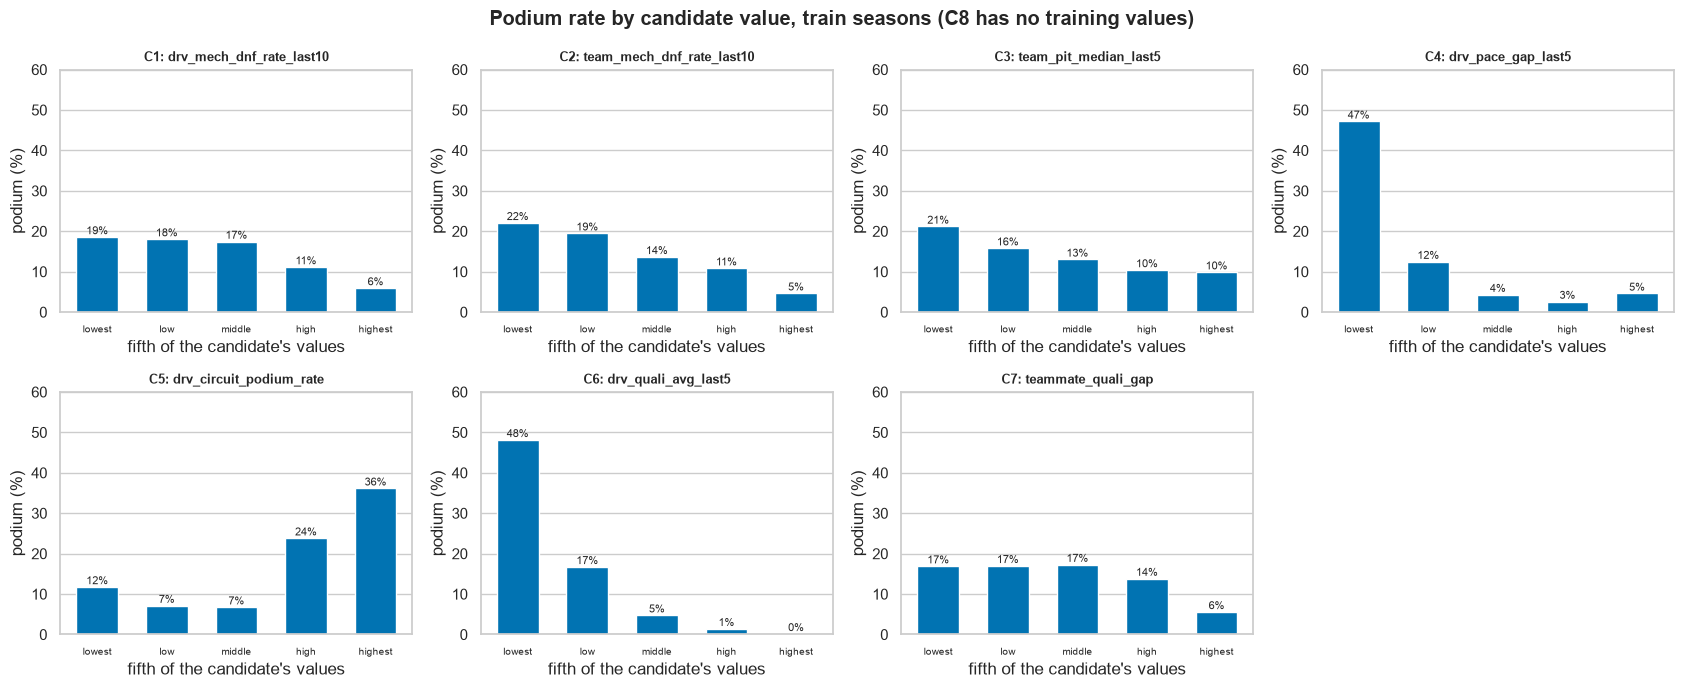

In [79]:
# ── 10.12 Candidates · R3 (not a copy) + evidence plots (train seasons only) ─────
tr = fe[fe["split"].eq("train") & ~fe["exclude_from_model"]]
existing_numeric = [c for c in FEATURE_COLS if c not in CATEGORICAL_FEATURES]
r3 = []
for cid, cand in CANDIDATES.items():
    if tr[cand].notna().sum() < 30:                         # e.g. sprints: no training values at all
        r3.append({"id": cid, "candidate": cand, "closest_existing": "—", "spearman": np.nan, "R3": "n/a (no train values)"})
        continue
    corrs = tr[existing_numeric].astype(float).corrwith(tr[cand].astype(float), method="spearman")
    top = corrs.abs().idxmax()
    r3.append({"id": cid, "candidate": cand, "closest_existing": top, "spearman": round(corrs[top], 3),
               "R3": "pass" if abs(corrs[top]) < 0.9 else "FAIL"})
r3 = pd.DataFrame(r3).set_index("id")
display(r3)

# Evidence: podium rate across 5 equal-sized groups of each candidate (train rows with a value).
plot_ids = [cid for cid in CANDIDATES if tr[CANDIDATES[cid]].notna().sum() >= 30]
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, cid in zip(axes.flat, plot_ids):
    col = CANDIDATES[cid]
    vals = tr[col].astype(float)
    groups = pd.qcut(vals.rank(method="first"), 5, labels=["lowest", "low", "middle", "high", "highest"])
    ev = tr.groupby(groups, observed=True)["podium"].mean().mul(100)
    ax.bar(ev.index.astype(str), ev.values, color=sns.color_palette("colorblind")[0], width=0.6)
    for x, v in enumerate(ev.values):
        ax.annotate(f"{v:.0f}%", (x, v), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=8)
    ax.set_title(f"{cid}: {col}", fontsize=9)
    ax.set(xlabel="fifth of the candidate's values", ylabel="podium (%)", ylim=(0, 60))
    ax.tick_params(axis="x", labelsize=7)
    ax.grid(axis="x", visible=False)
for ax in list(axes.flat)[len(plot_ids):]:
    ax.axis("off")
fig.suptitle("Podium rate by candidate value, train seasons (C8 has no training values)", fontweight="bold")
plt.tight_layout()
plt.show()

**What we found**
- **R3 (not a copy): all 7 candidates with training values pass.** The closest is C6, average qualifying, at **0.868** with team best finish, still under 0.9. C4 race pace is **0.771** with average finish. The rest are 0.35–0.52.
- **The evidence plots show a clear link for most candidates** (podium rate in the "best" fifth vs the "worst"):
  - C6 average qualifying: **48%** vs **0%**; C4 race pace: **47%** vs **5%**
  - C5 podium rate at this track: **36%** vs **12%**. Many drivers have 0 here, so the lower three fifths are mostly zeros.
  - C2 team failures: **22%** vs **5%**; C1 driver failures: **19%** vs **6%**; C3 pit stops: **21%** vs **10%**
  - C7 teammate gap: mostly flat, dropping to **6%** only for drivers who were well behind their teammate
- C8 has no training values, so it cannot be checked (it already failed R2).

**Why it's allowed:** correlations and plots use training seasons only.

**R4: does the candidate really help?** A fixed baseline (the 10.11 pipeline + logistic regression with balanced class weights) is trained with the 20 current features, then once more with each remaining candidate added.

Everything stays **inside the training seasons**: the pipeline and the model are fitted on **2003–2015** and scored on **2016–2019** with **PR-AUC**, which measures how well podium finishers are ranked above the rest. To see whether a gain is real or luck, the 2016–2019 races are resampled 1,000 times (whole races, the same resamples for every model). A candidate passes only if the 95% interval of its gain is above 0.

This is a screening test for feature selection, not the final model comparison (Section 11). **Validation and test are never used for any decision in Section 10.**

In [80]:
# ── 10.12 Candidates · R4 screening: does the candidate raise PR-AUC beyond noise (inside train)? ─
# Screening only, not the final model comparison (Section 11). Everything happens INSIDE the training seasons:
# fit on 2003–2015, score on 2016–2019. Validation and test are never used.
N_BOOT, INNER_SPLIT_YEAR = 1000, 2016
train_all = fe[fe["split"].eq("train") & ~fe["exclude_from_model"]]
fit_rows = train_all[train_all["year"] < INNER_SPLIT_YEAR]
hold_rows = train_all[train_all["year"] >= INNER_SPLIT_YEAR]                     # inner hold-out, still training seasons
y_fit, y_hold = fit_rows["podium"].astype(int), hold_rows["podium"].astype(int)


def screen_scores(features: list[str]) -> np.ndarray:
    """Baseline: the 10.11 pipeline + balanced logistic regression, fitted on 2003–2015; 2016–2019 probabilities."""
    model = Pipeline([("prep", make_preprocessor(features)),
                      ("logreg", LogisticRegression(class_weight="balanced", max_iter=5000))])
    model.fit(features_of(fit_rows, features), y_fit)
    return model.predict_proba(features_of(hold_rows, features))[:, 1]


# Resample whole 2016–2019 races (paired: the same resamples for every model).
rng = np.random.default_rng(SEED)
race_ids = hold_rows["raceId"].to_numpy()
races = np.unique(race_ids)
rows_of = {r: np.flatnonzero(race_ids == r) for r in races}
boot_idx = [np.concatenate([rows_of[r] for r in rng.choice(races, size=len(races), replace=True)]) for _ in range(N_BOOT)]

base_p = screen_scores(FEATURE_COLS)
base_ap = average_precision_score(y_hold, base_p)
print(f"Fit on {fit_rows['year'].min()}–{fit_rows['year'].max()} ({len(fit_rows):,} rows), scored on "
      f"{hold_rows['year'].min()}–{hold_rows['year'].max()} ({races.size} races, {len(hold_rows):,} rows), {N_BOOT} resamples.")
print(f"Baseline (20 features): PR-AUC = {base_ap:.4f}")

still_in = [cid for cid in CANDIDATES if cid not in ("C3", "C8")]     # C3 and C8 already failed R2
r4 = []
for cid in still_in:
    cand = CANDIDATES[cid]
    p = screen_scores(FEATURE_COLS + [cand])
    gains = [average_precision_score(y_hold.iloc[i], p[i]) - average_precision_score(y_hold.iloc[i], base_p[i]) for i in boot_idx]
    lo, hi = np.percentile(gains, [2.5, 97.5])
    r4.append({"id": cid, "candidate": cand, "PR-AUC with candidate": round(average_precision_score(y_hold, p), 4),
               "gain": round(average_precision_score(y_hold, p) - base_ap, 4),
               "95% interval": f"{lo:+.4f} to {hi:+.4f}", "R4": "pass" if lo > 0 else "FAIL"})
r4 = pd.DataFrame(r4).set_index("id")
display(r4)
check_grain(fe, "10.12 R4 screening (no join; fe unchanged)")

Fit on 2003–2015 (5,103 rows), scored on 2016–2019 (83 races, 1,702 rows), 1000 resamples.
Baseline (20 features): PR-AUC = 0.6877


,candidate,PR-AUC with candidate,gain,95% interval,R4
id,,,,,
C1,drv_mech_dnf_rate_last10,0.6908,0.0031,-0.0028 to +0.0084,FAIL
C2,team_mech_dnf_rate_last10,0.6875,-0.0002,-0.0009 to +0.0004,FAIL
C4,drv_pace_gap_last5,0.6883,0.0005,-0.0006 to +0.0018,FAIL
C5,drv_circuit_podium_rate,0.6867,-0.0010,-0.0049 to +0.0037,FAIL
C6,drv_quali_avg_last5,0.6886,0.0009,-0.0034 to +0.0053,FAIL
C7,teammate_quali_gap,0.6872,-0.0005,-0.0047 to +0.0037,FAIL


[grain ok] 10.12 R4 screening (no join; fe unchanged): 24,730 rows, one per (raceId, driverId)


**What we found**
- Fitted on **2003–2015** (5,103 rows) and scored on **2016–2019** (83 races, 1,702 rows), the baseline with the 20 current features reaches a PR-AUC of **0.688**.
- **No candidate helps beyond chance.** Every 95% interval of the gain includes 0:
  - C1 driver mechanical failures: +0.003 (−0.003 to +0.008); C6 average qualifying: +0.001 (−0.003 to +0.005); C4 race pace: +0.001 (−0.001 to +0.002)
  - C2 team failures, C5 podiums at this track and C7 teammate gap: slightly negative (−0.000 to −0.001)
- So **all six fail R4**. Their information is likely already carried by the 20 features, which matches the high R3 similarity of C6 (0.87) and C4 (0.77).
- The rule stays: **not proven, not added**.

**How R4 was run:** a first version scored on the validation seasons, and no candidate passed there either. R4 was then moved inside the training seasons (2003–2015 → 2016–2019), so that **no decision in Section 10 uses validation**. The pass rule did not change.

**Why it's allowed:** everything is fitted and scored within the training seasons; validation and test are not used.

**DECIDE: one table for all 8 candidates**

Every rule with its number, and the final decision. A kept candidate would be added to the modelling table and get its own group in `FEATURE_GROUPS`, so the Section 11 ablation could measure it again.

In [81]:
# ── 10.12 Candidates · DECIDE: one table, every rule with its number, the final decision ─
summary_12 = pd.DataFrame(index=list(CANDIDATES))
summary_12["candidate"] = list(CANDIDATES.values())
summary_12["R1 no leakage"] = "pass"
summary_12["R2 train filled"] = [f"{'pass' if v >= 70 else 'FAIL'} ({v:.1f}%)" for v in cov["train_%"]]
summary_12["R3 closest feature"] = [
    "n/a (no train values)" if pd.isna(r3.loc[c, "spearman"]) else
    f"{r3.loc[c, 'R3']} ({r3.loc[c, 'closest_existing']}, {r3.loc[c, 'spearman']:+.2f})" for c in CANDIDATES]
summary_12["R4 gain (95% range)"] = [
    f"{r4.loc[c, 'R4']} ({r4.loc[c, 'gain']:+.4f}; {r4.loc[c, '95% interval']})" if c in r4.index else "not run (failed R2)"
    for c in CANDIDATES]


def decide(cid: str) -> str:
    failed = [rule for rule, ok in [("R2", cov.loc[cid, "train_%"] >= 70),
                                    ("R3", pd.isna(r3.loc[cid, "spearman"]) or abs(r3.loc[cid, "spearman"]) < 0.9),
                                    ("R4", cid in r4.index and r4.loc[cid, "R4"] == "pass")] if not ok]
    if cid not in r4.index and "R2" in failed:
        failed = ["R2"]                                     # R4 was not run for candidates that already failed R2
    return "KEEP" if not failed else "reject: " + ", ".join(failed)


summary_12["decision"] = [decide(c) for c in CANDIDATES]
with pd.option_context("display.max_colwidth", 70):
    display(summary_12)

KEPT_CANDIDATES = [CANDIDATES[c] for c in CANDIDATES if summary_12.loc[c, "decision"] == "KEEP"]
HELPER_COLS += [c for c in CANDIDATES.values() if c not in KEPT_CANDIDATES]   # built and tested, never features
FEATURE_COLS += KEPT_CANDIDATES
if KEPT_CANDIDATES:
    FEATURE_GROUPS["extra"] = KEPT_CANDIDATES
assert not set(FEATURE_COLS) & set(HELPER_COLS) and len(FEATURE_COLS) == len(set(FEATURE_COLS))
assert sorted(c for cols in FEATURE_GROUPS.values() for c in cols) == sorted(FEATURE_COLS)
check_grain(fe, "10.12 decision (no join)")
print(f"Kept: {KEPT_CANDIDATES or 'none'}. FEATURE_COLS: {len(FEATURE_COLS)} features in {len(FEATURE_GROUPS)} groups "
      f"(unchanged); the 8 candidates stay in fe as helper columns.")

,candidate,R1 no leakage,R2 train filled,R3 closest feature,R4 gain (95% range),decision
C1,drv_mech_dnf_rate_last10,pass,pass (98.9%),"pass (drv_avg_finish_last5, +0.37)",FAIL (+0.0031; -0.0028 to +0.0084),reject: R4
C2,team_mech_dnf_rate_last10,pass,pass (99.5%),"pass (team_points_share_before, -0.39)",FAIL (-0.0002; -0.0009 to +0.0004),reject: R4
C3,team_pit_median_last5,pass,FAIL (55.8%),"pass (year, +0.34)",not run (failed R2),reject: R2
C4,drv_pace_gap_last5,pass,pass (98.9%),"pass (drv_avg_finish_last5, +0.77)",FAIL (+0.0005; -0.0006 to +0.0018),reject: R4
C5,drv_circuit_podium_rate,pass,pass (76.2%),"pass (drv_races_in_history, +0.52)",FAIL (-0.0010; -0.0049 to +0.0037),reject: R4
C6,drv_quali_avg_last5,pass,pass (98.9%),"pass (team_avg_best_finish_last5, +0.87)",FAIL (+0.0009; -0.0034 to +0.0053),reject: R4
C7,teammate_quali_gap,pass,pass (100.0%),"pass (quali_pos, +0.35)",FAIL (-0.0005; -0.0047 to +0.0037),reject: R4
C8,sprint_pos_this_weekend,pass,FAIL (0.0%),n/a (no train values),not run (failed R2),reject: R2


[grain ok] 10.12 decision (no join): 24,730 rows, one per (raceId, driverId)
Kept: none. FEATURE_COLS: 20 features in 7 groups (unchanged); the 8 candidates stay in fe as helper columns.


**What we found**
- **All 8 candidates pass R1** (no leakage).
- **2 fail R2** (not enough training data): pit stops (**55.8%** filled) and the sprint (**0%**).
- **All pass R3** (none is a copy; the closest is average qualifying at **0.87**).
- **The other 6 fail R4:** none raises PR-AUC beyond chance inside the training seasons.
- **Decision: no candidate is added.** The modelling table keeps its **20 features in 7 groups**, and the 8 candidates stay in `fe` as helper columns only.

**Why it matters:** the brief lets us design our own features, but each one needs evidence. These tests show that the extra tables do not add pre-race information beyond what qualifying, grid, standings and form already carry.

In [82]:
# ── 10.12 Data not used · one check: constructor_results only repeats the team standings (train seasons) ─
cr_train = (clean["constructor_results"][["raceId", "constructorId", "points"]]
            .merge(clean["races"][["raceId", "year", "date"]], on="raceId")
            .query("2003 <= year <= 2019").sort_values(["year", "constructorId", "date"]))
cr_train["running_total"] = cr_train.groupby(["year", "constructorId"])["points"].cumsum()
cmp_cr = cr_train.merge(clean["constructor_standings"][["raceId", "constructorId", "points"]],
                        on=["raceId", "constructorId"], suffixes=("", "_standings"))
same = (cmp_cr["running_total"] - cmp_cr["points_standings"]).abs() < 1e-6
print(f"2003–2019: the running total of constructor_results points equals the constructor standings in "
      f"{100 * same.mean():.2f}% of {len(cmp_cr):,} team-race rows; the {int((~same).sum())} exceptions:")
display(cmp_cr.loc[~same].merge(clean["constructors"][["constructorId", "name"]], on="constructorId")
        .groupby(["year", "name"]).size().rename("rows").reset_index())

2003–2019: the running total of constructor_results points equals the constructor standings in 99.65% of 3,402 team-race rows; the 12 exceptions:


,year,name,rows
0,2007,McLaren,3
1,2018,Force India,9


### Data not used, and why

**Rejected candidates** (summary table above):

| Candidate | Failed rule | Number |
|---|---|---|
| C3 team pit-stop median | R2 · not enough training data | 55.8% of train rows filled (pit-stop data starts in 2011) |
| C8 this weekend's sprint | R2 · not enough training data | 0% of train rows filled (sprints start in 2021) |
| C1 driver mechanical failures | R4 · no proven gain | +0.0031 (−0.0028 to +0.0084) |
| C2 team mechanical failures | R4 · no proven gain | −0.0002 (−0.0009 to +0.0004) |
| C4 driver race pace | R4 · no proven gain | +0.0005 (−0.0006 to +0.0018) |
| C5 podium rate at this track | R4 · no proven gain | −0.0010 (−0.0049 to +0.0037) |
| C6 average qualifying, last 5 | R4 · no proven gain | +0.0009 (−0.0034 to +0.0053) |
| C7 gap to teammate in qualifying | R4 · no proven gain | −0.0005 (−0.0047 to +0.0037) |

**Whole tables or uses we leave out:**
- **This race's lap times and pit stops:** they happen *during* the race, so they are race results and never features. Their earlier-race summaries were tested (C3, C4) and rejected.
- **Sprint results:** the sprint runs before the main race, so it is pre-race information. But it exists for only 18 races (2021–2024) and for **no** training season, so the model could never learn from it (C8, R2).
- **constructor_results:** its per-race team points add up to the constructor standings in **99.65%** of 2003–2019 rows (the 12 exceptions are McLaren 2007 and Force India 2018). The team-standings features already use those standings, so it adds nothing new.
- **seasons:** it only holds the year and a Wikipedia link. The year is already a feature.

### 10.13 Section summary

**The final features (20, in 7 groups), and where each one comes from**

| Group | Feature | Source | How we got it | Why it is known before the race |
|---|---|---|---|---|
| Qualifying | `quali_pos` | qualifying (already in `base`) | taken; no qualifying row → back of the field | qualifying is over |
| | `quali_top10` | qualifying (in `base`) | created: qualified in the top 10 | qualifying is over |
| | `q1_gap_pct` | qualifying (in `base`) | created: Q1 lap vs fastest Q1 lap (%); no time → slowest gap of the race | qualifying is over |
| | `q1_missing` | qualifying (in `base`) | created: no Q1 time | qualifying is over |
| | `has_qualifying` | qualifying (in `base`) | created: has a qualifying row | qualifying is over |
| Grid | `pit_lane_start` | results `grid` (in `base`) | created: grid = 0 | the grid is fixed before the start |
| | `grid_minus_quali` | results `grid` + qualifying | created: grid − qualifying position | the grid is fixed before the start |
| Driver standings | `drv_pos_before` | **joined** `driver_standings` (previous race, via `races`) | joined, then ranked by points | standings after the previous race |
| | `drv_points_share_before` | **joined** `driver_standings` | joined, then ÷ the leader's points | standings after the previous race |
| | `is_season_opener` | `races` (previous race by date) | created: no previous race this season | known from the calendar |
| Team standings | `team_pos_before` | **joined** `constructor_standings` | joined, then ranked by points | standings after the previous race |
| | `team_points_share_before` | **joined** `constructor_standings` | joined, then ÷ the leading team's points | standings after the previous race |
| Driver form | `drv_podium_rate_last5` | results of earlier races (in `base`) | created: last 5 races, this race excluded | earlier races only |
| | `drv_avg_finish_last5` | results of earlier races | created: last 5 races | earlier races only |
| | `drv_races_in_history` | results of earlier races | created: count of earlier races | earlier races only |
| Team form | `team_podium_rate_last5` | results of earlier races | created: one row per team per race first, then last 5 races | earlier races only |
| | `team_avg_best_finish_last5` | results of earlier races | created: the same, best car per race | earlier races only |
| Context | `year` | races (in `base`) | taken | known in advance |
| | `circuitId` | races (in `base`) | taken, used as a category | known in advance |
| | `driver_age` | drivers `dob` + race date (in `base`) | created | known in advance |

The pipeline adds one more column, `team_form_missing`. Columns built but **never** given to a model (helper columns): `split`, `n_cars`, `quali_pos_raw`, `prev_raceId`, `grid_clean`, raw `drv_points_before` / `team_points_before`, the re-scored shares and their totals, `is_mech_dnf`, and the 8 tested candidates.

**How empty values are filled**

| Gap | Fill |
|---|---|
| no qualifying row | `quali_pos` = back of the field, `has_qualifying` = 0 |
| no Q1 time | `q1_gap_pct` = slowest gap of the race, `q1_missing` = 1 |
| grid = 0 | `pit_lane_start` = 1 |
| season opener (standings) | points shares and positions empty → training median in the pipeline; `is_season_opener` marks the rows |
| first race of a driver / team (form) | training median in the pipeline; `drv_races_in_history` = 0 / `team_form_missing` = 1 mark the rows |
| anything else empty at prediction time | training median (the pipeline accepts any missing feature) |

**Leakage checks we ran**
- The grain (one row per driver per race, 24,730 rows) was checked after every join.
- Every "before this race" value was computed a second way and matched for every row: standings, re-scored totals, driver and team form, and all candidates.
- Spot checks by hand: Hamilton 2014, Vettel 2010, Ferrari 2008, McLaren 2007, Alonso 2012, Red Bull 2013.
- Teammates always get identical team values.
- In code, no feature is a race result, a flag, `standings_excluded` or a helper column.
- The pipeline is fitted on training seasons only.
- **No decision in Section 10 used validation or test.** Validation is first used in Section 11.

**Extra features (10.12):** 8 candidates from tables not used before were tested on 4 fixed rules. 2 failed R2 (pit stops, sprints: not enough training data), and 6 failed R4 (no proven gain inside the training seasons). **None was added.**

**Planned for Section 11 (the 2 preprocessing-order experiments)**
1. Pipeline fitted on train only vs on train + validation, scored on validation: a demonstration of why the fit must be train-only.
2. Fill → scale vs scale → fill, both fitted on train, scored on validation: whether the order of the two steps matters.

**Known limitations**
- **Qualifying coverage drift:** qualifying is complete only from 2003, so earlier seasons serve only as history.
- **Era sensitivity:** big rule changes in 2009, 2014 and 2022 reshuffle which teams are fast, so form and standings can mislead at the start of a new era.
- **Small validation set:** 780 rows over 2 seasons, including the 17-race 2020.
- **Sprint points:** from 2021 the official standings include sprint points.
- **Renamed teams** get a new ID, so their team history restarts.
- **`year` in test (2022–2024) lies outside the training range** (2003–2019). The Section 11 ablation checks whether the context group helps.

In [83]:
# ── 10.13 End of Section 10 · final checks ───────────────────────────────────────
# (1) base is unchanged, so Section 9's answers stay reproducible.
assert base.shape == BASE_SHAPE and list(base.columns) == BASE_COLUMNS, "base changed shape or columns"
assert fingerprint(base) == BASE_FINGERPRINT, "base values changed"
# (2) Only FEATURE_COLS can reach a model, and none of them is forbidden.
FORBIDDEN = set(POST_RACE_COLS) | set(DOC_FLAGS) | {"standings_excluded"} | set(HELPER_COLS)
assert not set(FEATURE_COLS) & FORBIDDEN, "a forbidden column is a feature"
assert list(features_of(model_table).columns) == FEATURE_COLS, "features_of does not return exactly FEATURE_COLS"
assert sorted(c for cols in FEATURE_GROUPS.values() for c in cols) == sorted(FEATURE_COLS)
# (3) The modelling table still has its grain.
check_grain(model_table, "10.13 model_table")
check_grain(fe, "10.13 fe")
print(f"base unchanged ({base.shape[0]:,} × {base.shape[1]}). model_table: {len(model_table):,} rows, "
      f"{len(FEATURE_COLS)} features in {len(FEATURE_GROUPS)} groups: {list(FEATURE_GROUPS)}.")

[grain ok] 10.13 model_table: 24,730 rows, one per (raceId, driverId)
[grain ok] 10.13 fe: 24,730 rows, one per (raceId, driverId)
base unchanged (24,730 × 29). model_table: 24,730 rows, 20 features in 7 groups: ['qualifying', 'grid', 'driver_standings', 'team_standings', 'driver_form', 'team_form', 'context'].
